# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/industrial'

## Evaluation Settings

In [ ]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 3.5  # For industrial data

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_ind_hour_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_24h', 'consumption_lag_25h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 25 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 25 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.04 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 25 splits
Validation data: 25 splits
First train split shape: X=(1344, 9), y=(1344,)
First valid split shape: X=(1344, 9), y=(1344,)

Memory usage:
Train: 40.54 MB
Valid: 4.23 MB
Test: 1.08 MB
Total: 45.85 MB


# WFV Models Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [ ]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.024620 MB


 2023-02-27 04:00:00+01:00    0.753687
2023-02-27 05:00:00+01:00    0.963438
2023-02-27 06:00:00+01:00    0.985125
2023-02-27 07:00:00+01:00    0.936563
2023-02-27 08:00:00+01:00    0.961000
                               ...   
2023-03-26 23:00:00+02:00    0.152375
2023-03-27 00:00:00+02:00    0.153500
2023-03-27 01:00:00+02:00    0.197687
2023-03-27 02:00:00+02:00    0.208063
2023-03-27 03:00:00+02:00    0.254625
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.242833
2023-03-27 05:00:00+02:00    0.226187
2023-03-27

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.024460 MB


 2023-02-27 04:00:00+01:00    0.759063
2023-02-27 05:00:00+01:00    0.937688
2023-02-27 06:00:00+01:00    0.983562
2023-02-27 07:00:00+01:00    0.941531
2023-02-27 08:00:00+01:00    0.994250
                               ...   
2023-04-23 23:00:00+02:00    0.148375
2023-04-24 00:00:00+02:00    0.146389
2023-04-24 01:00:00+02:00    0.149719
2023-04-24 02:00:00+02:00    0.155625
2023-04-24 03:00:00+02:00    0.145781
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.160214
2023-04-24 05:00:00+02:00    0.187563
2023-04-2

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.024162 MB


 2024-06-29 13:00:00+02:00    2.965651
2024-06-29 14:00:00+02:00    2.934451
2024-06-29 15:00:00+02:00    2.341793
2024-06-29 16:00:00+02:00    2.007989
2024-06-29 17:00:00+02:00    3.149209
                               ...   
2024-12-29 22:00:00+01:00    3.895496
2024-12-29 23:00:00+01:00    3.507841
2024-12-30 00:00:00+01:00    2.685457
2024-12-30 01:00:00+01:00    4.744482
2024-12-30 02:00:00+01:00    3.612723
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00     3.443460
2024-12-30 04:00:00+01:00     4.181425
2024-12

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.024162 MB


 2024-06-29 13:00:00+02:00    2.918749
2024-06-29 14:00:00+02:00    2.922494
2024-06-29 15:00:00+02:00    2.366617
2024-06-29 16:00:00+02:00    1.933749
2024-06-29 17:00:00+02:00    3.141430
                               ...   
2025-01-26 22:00:00+01:00    3.493077
2025-01-26 23:00:00+01:00    2.385811
2025-01-27 00:00:00+01:00    3.467100
2025-01-27 01:00:00+01:00    2.358155
2025-01-27 02:00:00+01:00    3.219302
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     3.847442
2025-01-27 04:00:00+01:00     3.759215
2025-01

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0568 ± 0.0092
	MAE: 0.0379 ± 0.0066
	MAPE: 14.9814% ± 2.9905%

	Directional Metrics:
		Directional Accuracy: 56.9355% ± 3.5743%
		First-Diff Correlation: 0.3865 ± 0.0908

	Immediate Detection (delta=0):
		Spike Precision: 0.2407 ± 0.1164
		Spike Recall: 0.2703 ± 0.1303
		Spike F1: 0.2524 ± 0.1200
		Drop Precision: 0.1231 ± 0.0917
		Drop Recall: 0.1370 ± 0.1010
		Drop F1: 0.1280 ± 0.0930

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6399 ± 0.1532
		Spike Recall: 0.7126 ± 0.1476
		Spike F1: 0.6675 ± 0.1350
		Drop Precision: 0.4631 ± 0.1696
		Drop Recall: 0.4964 ± 0.1327
		Drop F1: 0.4736 ± 0.1414
Daily Metrics:
	RMSE: 0.0753 ± 0.0503
	MAE: 0.0550 ± 0.0392
	MAPE: 0.9071% ± 0.3297%

	Directional Metrics:
		Directional Accuracy: 97.4612% ± 3.4233%
		First-Diff Correlation: 0.9979 ± 0.0019

	Immediate Detection (delta=0):
		Spik

#### Validation plots

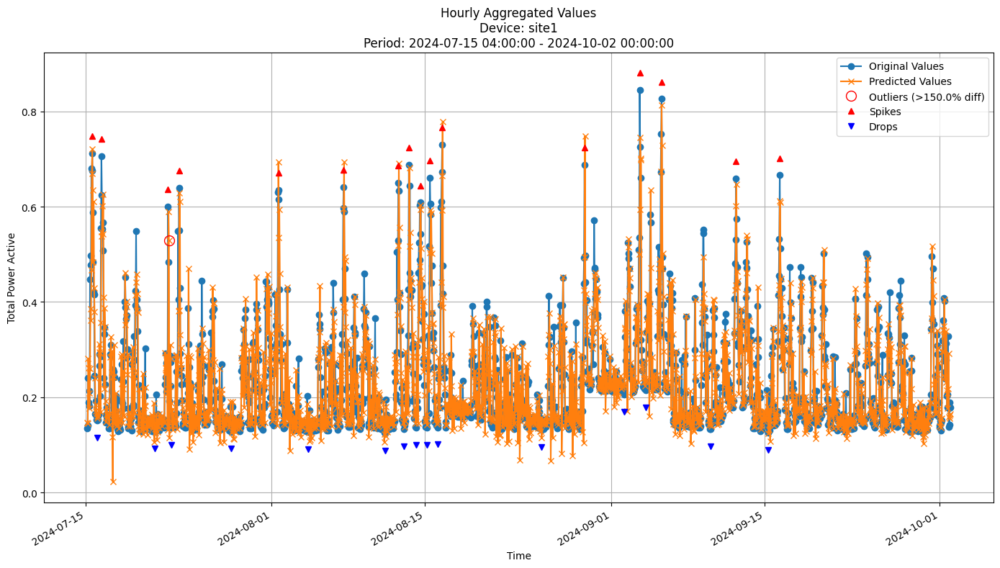


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0625
MAE: 0.0395
MAPE: 16.1876%

Directional Metrics:
Directional Accuracy: 51.1099%
First-Diff Correlation: 0.2893

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2353
  Recall: 0.2500
  F1 Score: 0.2424
Drops:
  Precision: 0.0625
  Recall: 0.0667
  F1 Score: 0.0645

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8235
  Recall: 0.8750
  F1 Score: 0.8485
Drops:
  Precision: 0.2500
  Recall: 0.2667
  F1 Score: 0.2581


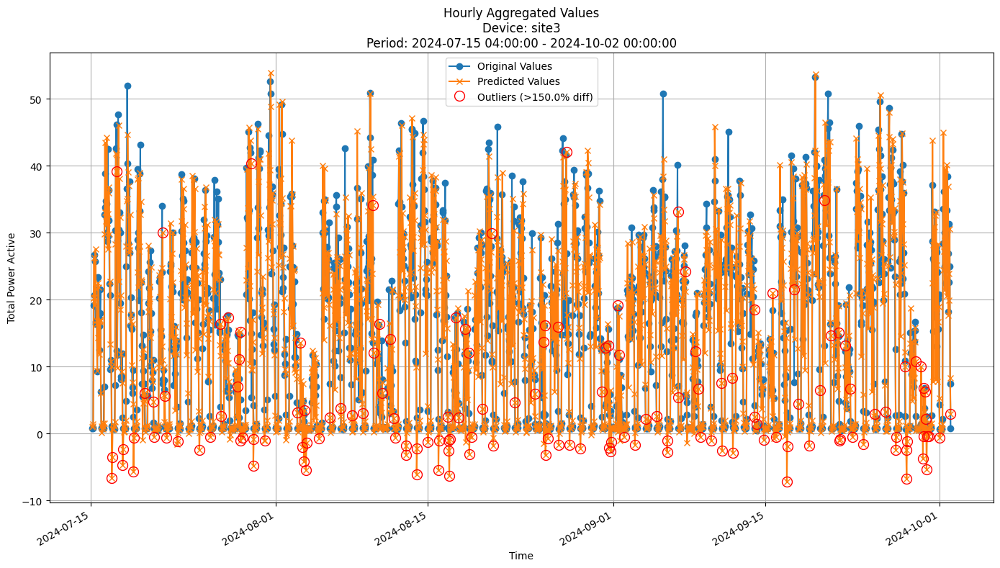


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.4630
MAE: 4.2877
MAPE: 56.6631%

Directional Metrics:
Directional Accuracy: 46.6173%
First-Diff Correlation: 0.2615

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


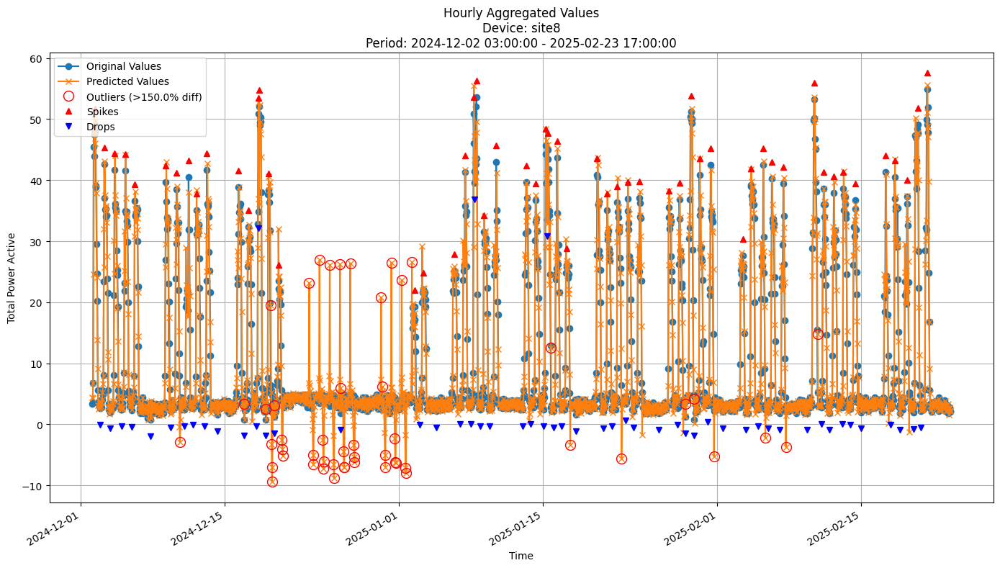


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.7315
MAE: 1.9679
MAPE: 30.0459%

Directional Metrics:
Directional Accuracy: 47.0588%
First-Diff Correlation: 0.5349

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0794
  Recall: 0.0909
  F1 Score: 0.0847
Drops:
  Precision: 0.0161
  Recall: 0.0185
  F1 Score: 0.0172

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7619
  Recall: 0.8727
  F1 Score: 0.8136
Drops:
  Precision: 0.3065
  Recall: 0.3519
  F1 Score: 0.3276


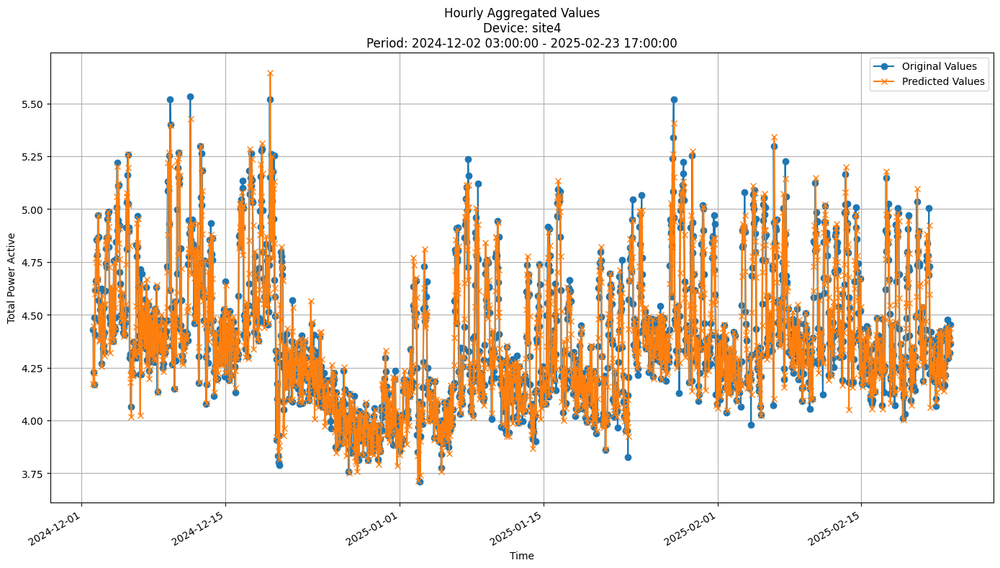


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1754
MAE: 0.1294
MAPE: 2.9219%

Directional Metrics:
Directional Accuracy: 36.2413%
First-Diff Correlation: -0.2633

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


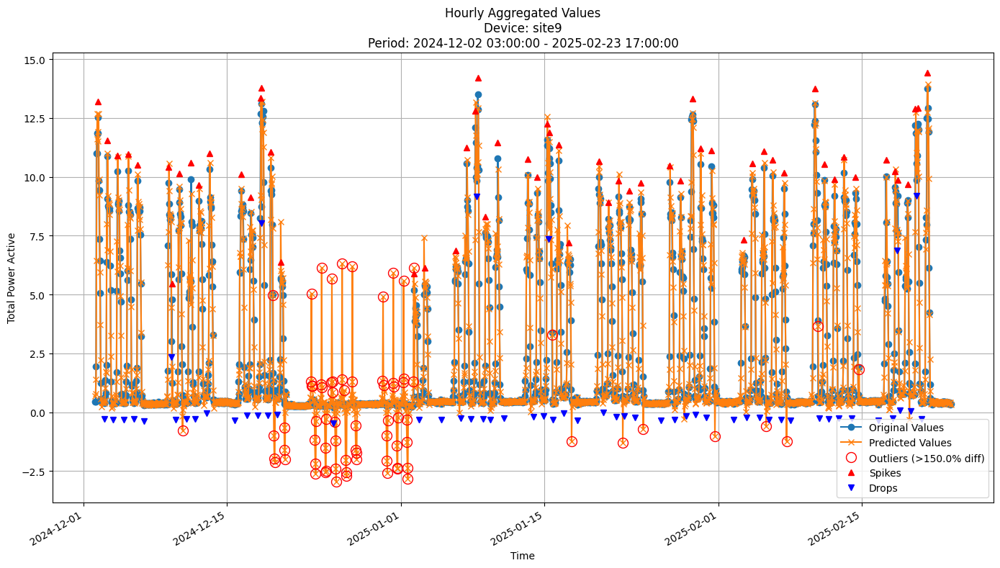


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9071
MAE: 0.4202
MAPE: 39.1434%

Directional Metrics:
Directional Accuracy: 51.1466%
First-Diff Correlation: 0.5689

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0690
  F1 Score: 0.0615
Drops:
  Precision: 0.0704
  Recall: 0.0877
  F1 Score: 0.0781

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7083
  Recall: 0.8793
  F1 Score: 0.7846
Drops:
  Precision: 0.3662
  Recall: 0.4561
  F1 Score: 0.4062


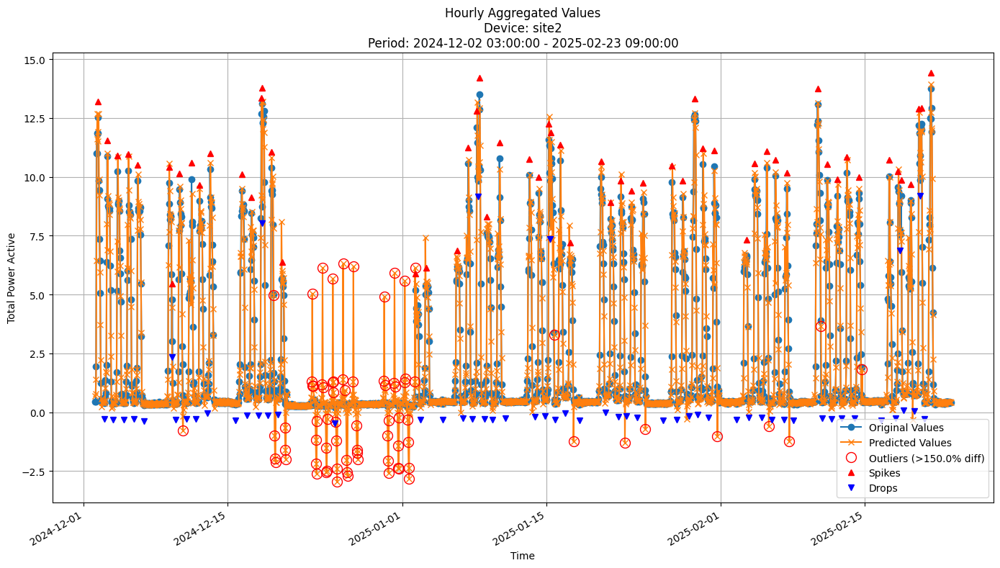


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9089
MAE: 0.4217
MAPE: 39.2591%

Directional Metrics:
Directional Accuracy: 51.2012%
First-Diff Correlation: 0.5689

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0690
  F1 Score: 0.0615
Drops:
  Precision: 0.0704
  Recall: 0.0877
  F1 Score: 0.0781

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7083
  Recall: 0.8793
  F1 Score: 0.7846
Drops:
  Precision: 0.3662
  Recall: 0.4561
  F1 Score: 0.4062


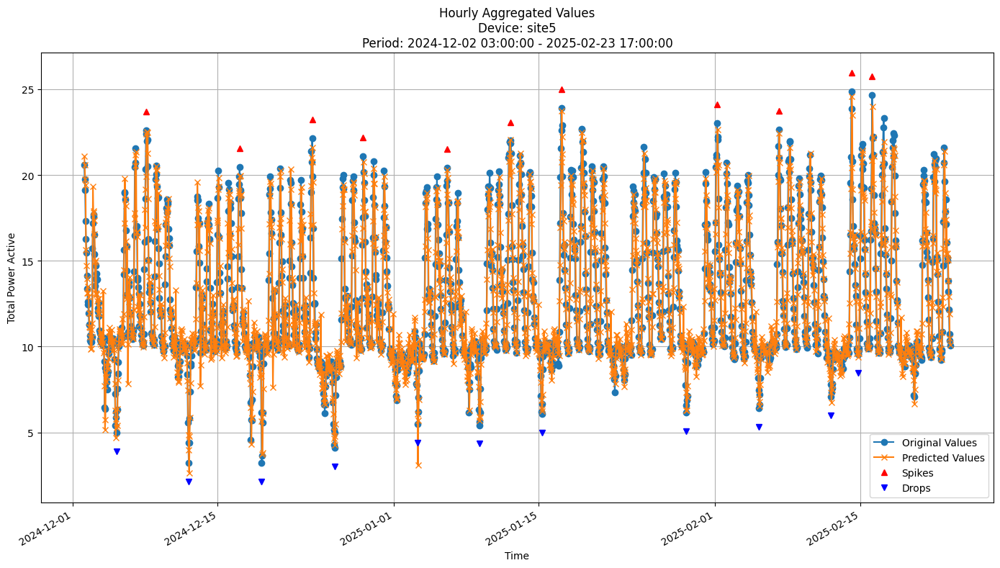


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1285
MAE: 0.8208
MAPE: 6.4781%

Directional Metrics:
Directional Accuracy: 61.9143%
First-Diff Correlation: 0.3968

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0909
  F1 Score: 0.1667
Drops:
  Precision: 1.0000
  Recall: 0.1818
  F1 Score: 0.3077


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [ ]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': True}

In [ ]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000511 MB


 2023-02-27 04:00:00+01:00    0.71225
2023-02-27 05:00:00+01:00    0.75000
2023-02-27 06:00:00+01:00    0.98950
2023-02-27 07:00:00+01:00    0.85375
2023-02-27 08:00:00+01:00    1.04125
                              ...   
2023-03-26 23:00:00+02:00    0.11650
2023-03-27 00:00:00+02:00    0.12600
2023-03-27 01:00:00+02:00    0.15075
2023-03-27 02:00:00+02:00    0.17100
2023-03-27 03:00:00+02:00    0.21600
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.19375
2023-03-27 05:00:00+02:00    0.19800
2023-03-27 06:00:00+02:00    0.28700
2023-03-27 07:00:00+02:00    0.56550
2023-03-27 08:00:00+02:00    0.42775
                              ...   
2023-04-23 23:00:00+02:00    0.12775
2023-04-24 00:00:00+02:00    0.14375
2023-04-24 01:00:00+0

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000496 MB


 2023-02-27 04:00:00+01:00    0.73825
2023-02-27 05:00:00+01:00    0.77600
2023-02-27 06:00:00+01:00    1.01550
2023-02-27 07:00:00+01:00    0.87975
2023-02-27 08:00:00+01:00    1.06725
                              ...   
2023-04-23 23:00:00+02:00    0.13550
2023-04-24 00:00:00+02:00    0.14150
2023-04-24 01:00:00+02:00    0.14150
2023-04-24 02:00:00+02:00    0.14225
2023-04-24 03:00:00+02:00    0.13675
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.14050
2023-04-24 05:00:00+02:00    0.18925
2023-04-24 06:00:00+02:00    0.19250
2023-04-24 07:00:00+02:00    0.38075
2023-04-24 08:00:00+02:00    0.29875
                              ...   
2023-05-21 23:00:00+02:00    0.20875
2023-05-22 00:00:00+02:00    0.15475
2023-05-22 01:00:00+

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000313 MB


 2024-06-29 13:00:00+02:00    1.844425
2024-06-29 14:00:00+02:00    1.825378
2024-06-29 15:00:00+02:00    1.414906
2024-06-29 16:00:00+02:00    0.621030
2024-06-29 17:00:00+02:00    1.637979
                               ...   
2024-12-29 22:00:00+01:00    2.621252
2024-12-29 23:00:00+01:00    2.592051
2024-12-30 00:00:00+01:00    1.380866
2024-12-30 01:00:00+01:00    3.644648
2024-12-30 02:00:00+01:00    2.600222
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00    1.437646
2024-12-30 04:00:00+01:00    4.247235
2024-12-30 05:00:00+01:00    4.906913
2024-12-30 06:00:00+01:00    1.809317
2024-12-30 07:00:00+01:00    2.157751
                               ...   
2025-01-26 22:00:00+01:00    3.201579
2025-01-26 23:00:00+01:00    1.826126
2

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000313 MB


 2024-06-29 13:00:00+02:00    2.787273
2024-06-29 14:00:00+02:00    2.768225
2024-06-29 15:00:00+02:00    2.357754
2024-06-29 16:00:00+02:00    1.563878
2024-06-29 17:00:00+02:00    2.580827
                               ...   
2025-01-26 22:00:00+01:00    3.187951
2025-01-26 23:00:00+01:00    2.397174
2025-01-27 00:00:00+01:00    3.161446
2025-01-27 01:00:00+01:00    2.175005
2025-01-27 02:00:00+01:00    3.004000
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     2.784271
2025-01-27 04:00:00+01:00     3.206353
2025-01-27 05:00:00+01:00     3.219522
2025-01-27 06:00:00+01:00    15.031733
2025-01-27 07:00:00+01:00    61.920127
                               ...    
2025-02-23 13:00:00+01:00     1.193665
2025-02-23 14:00:00+01:00     3.

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1062 ± 0.0087
	MAE: 0.0730 ± 0.0076
	MAPE: 29.0722% ± 4.5021%

	Directional Metrics:
		Directional Accuracy: 48.4419% ± 2.5372%
		First-Diff Correlation: -0.0337 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.0937 ± 0.0363
		Spike Recall: 0.1795 ± 0.0732
		Spike F1: 0.1210 ± 0.0430
		Drop Precision: 0.1000 ± 0.0585
		Drop Recall: 0.1781 ± 0.0907
		Drop F1: 0.1267 ± 0.0704

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5236 ± 0.1281
		Spike Recall: 0.9700 ± 0.0302
		Spike F1: 0.6708 ± 0.1128
		Drop Precision: 0.3109 ± 0.1394
		Drop Recall: 0.5517 ± 0.1701
		Drop F1: 0.3933 ± 0.1563
Daily Metrics:
	RMSE: 0.0498 ± 0.0139
	MAE: 0.0360 ± 0.0100
	MAPE: 0.7129% ± 0.3436%

	Directional Metrics:
		Directional Accuracy: 97.6786% ± 3.2488%
		First-Diff Correlation: 0.9979 ± 0.0023

	Immediate Detection (delta=0):
		Spi

#### Validation plots

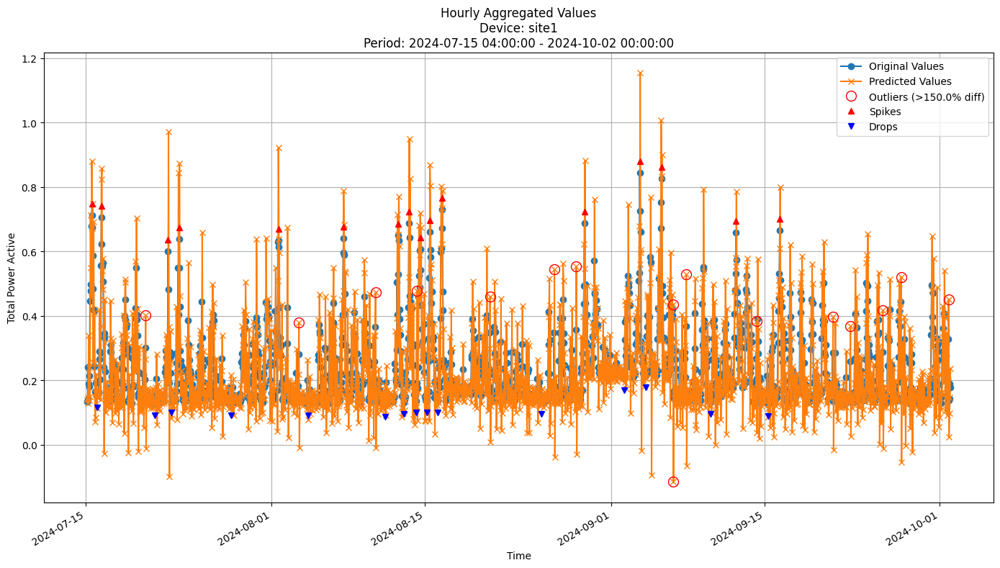


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1043
MAE: 0.0718
MAPE: 30.8104%

Directional Metrics:
Directional Accuracy: 44.5560%
First-Diff Correlation: -0.0395

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0750
  Recall: 0.1875
  F1 Score: 0.1071
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3750
  Recall: 0.9375
  F1 Score: 0.5357
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


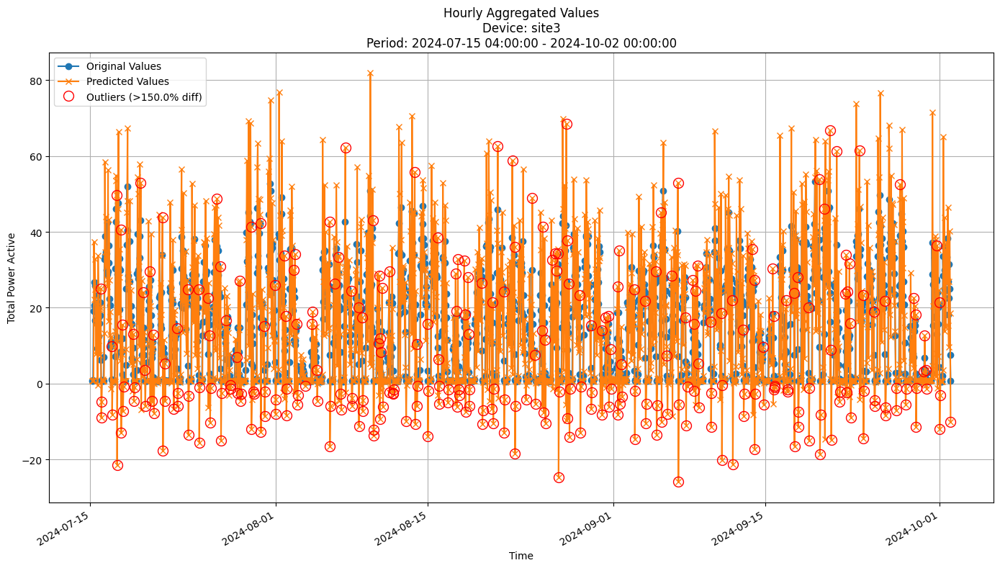


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 12.7240
MAE: 8.6786
MAPE: 132.2774%

Directional Metrics:
Directional Accuracy: 48.2558%
First-Diff Correlation: -0.0436

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


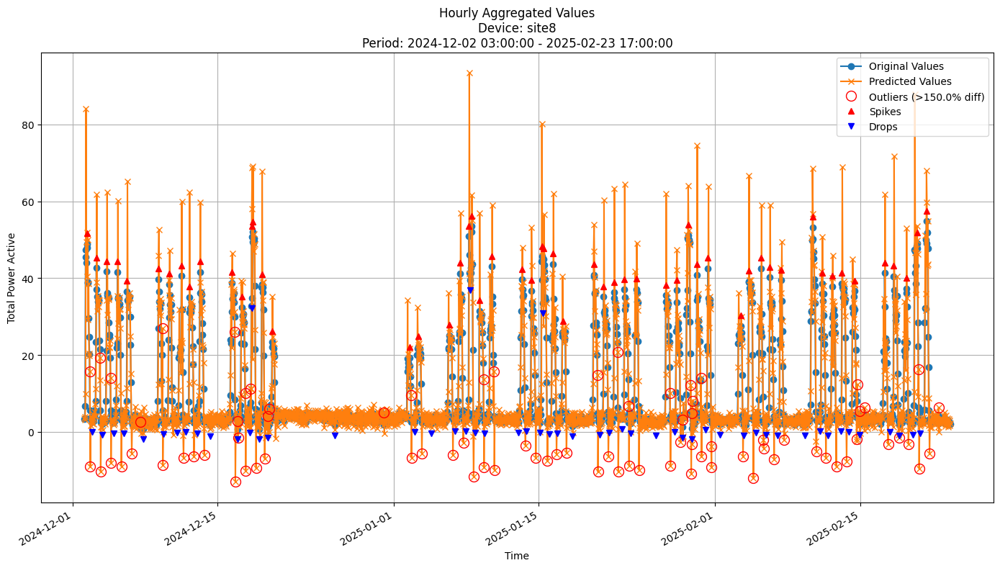


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.4600
MAE: 3.3657
MAPE: 44.0484%

Directional Metrics:
Directional Accuracy: 45.3639%
First-Diff Correlation: 0.1963

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1385
  Recall: 0.1636
  F1 Score: 0.1500
Drops:
  Precision: 0.0312
  Recall: 0.0370
  F1 Score: 0.0339

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7692
  Recall: 0.9091
  F1 Score: 0.8333
Drops:
  Precision: 0.1094
  Recall: 0.1296
  F1 Score: 0.1186


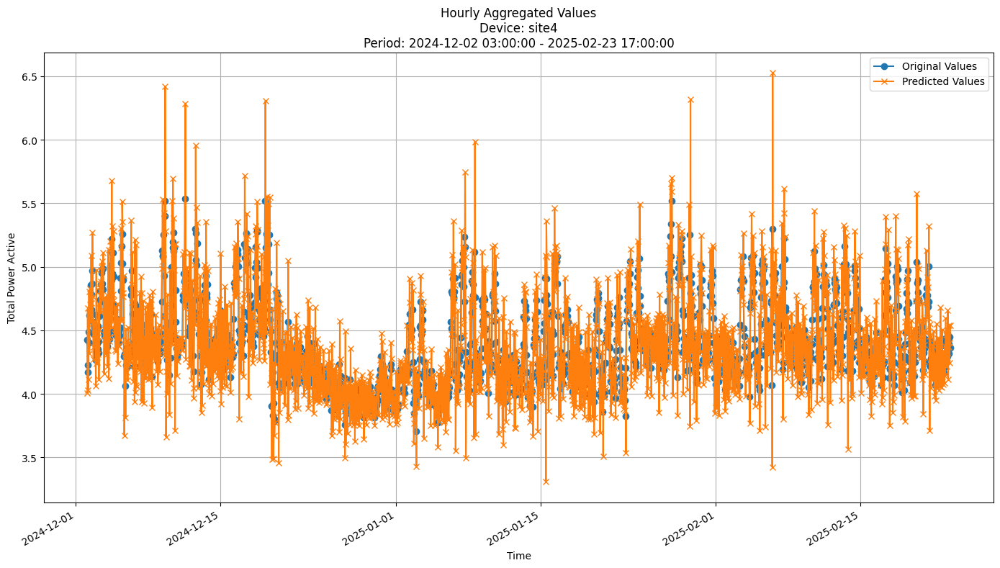


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2955
MAE: 0.2219
MAPE: 5.0111%

Directional Metrics:
Directional Accuracy: 38.2851%
First-Diff Correlation: -0.2370

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


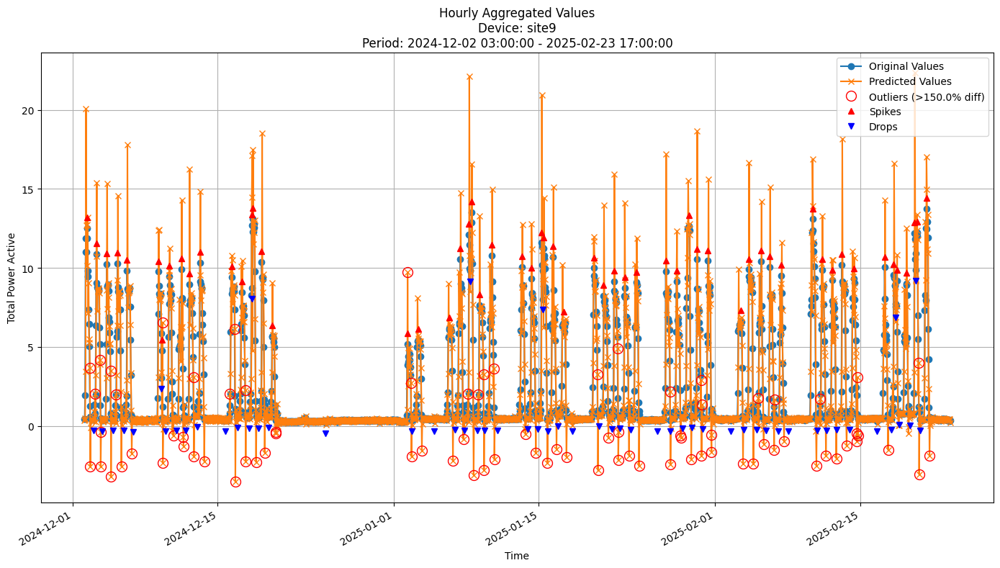


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5650
MAE: 0.7001
MAPE: 34.7411%

Directional Metrics:
Directional Accuracy: 48.0558%
First-Diff Correlation: 0.2303

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.1724
  F1 Score: 0.1190
Drops:
  Precision: 0.0273
  Recall: 0.0526
  F1 Score: 0.0359

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4909
  Recall: 0.9310
  F1 Score: 0.6429
Drops:
  Precision: 0.1364
  Recall: 0.2632
  F1 Score: 0.1796


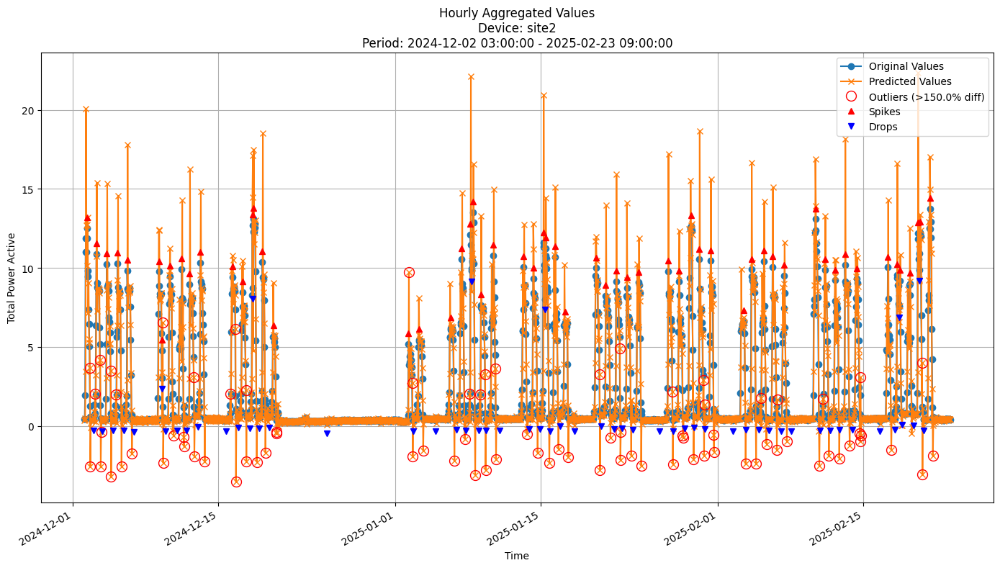


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5682
MAE: 0.7026
MAPE: 34.8141%

Directional Metrics:
Directional Accuracy: 48.0480%
First-Diff Correlation: 0.2304

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.1724
  F1 Score: 0.1190
Drops:
  Precision: 0.0273
  Recall: 0.0526
  F1 Score: 0.0359

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4909
  Recall: 0.9310
  F1 Score: 0.6429
Drops:
  Precision: 0.1364
  Recall: 0.2632
  F1 Score: 0.1796


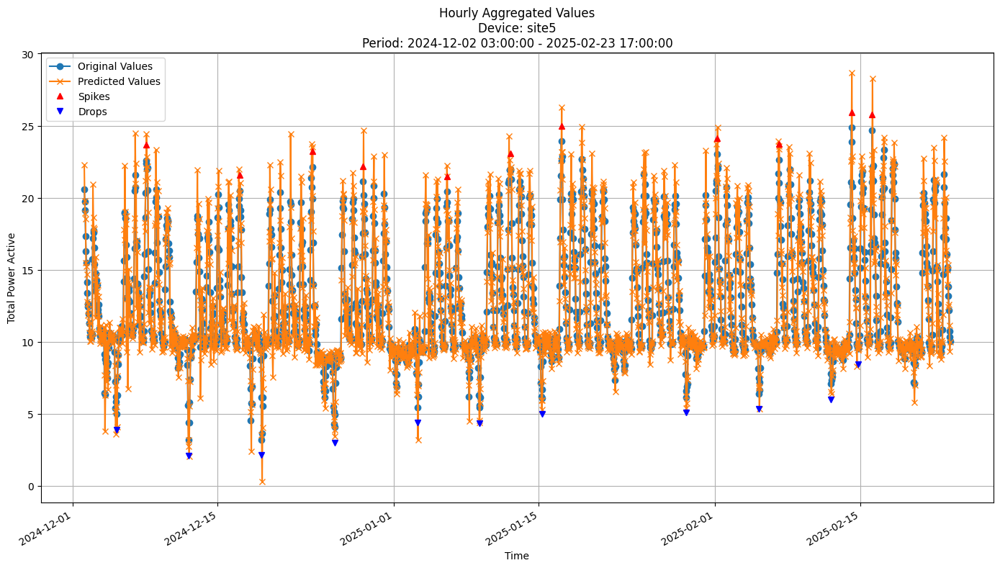


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3226
MAE: 0.8957
MAPE: 6.8820%

Directional Metrics:
Directional Accuracy: 56.7797%
First-Diff Correlation: 0.3501

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0714
  Recall: 0.1818
  F1 Score: 0.1026
Drops:
  Precision: 0.1429
  Recall: 0.3636
  F1 Score: 0.2051

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3214
  Recall: 0.8182
  F1 Score: 0.4615
Drops:
  Precision: 0.3214
  Recall: 0.8182
  F1 Score: 0.4615


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
gbdt_params = {
    'n_estimators': 150, 
     'learning_rate': 0.05, 
     'max_depth': 7, 
     'subsample': 0.8, 
     'random_state': 42
}

In [ ]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.25 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.35 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.012306 MB


 2023-02-27 04:00:00+01:00    0.764954
2023-02-27 05:00:00+01:00    1.005418
2023-02-27 06:00:00+01:00    0.904700
2023-02-27 07:00:00+01:00    1.051199
2023-02-27 08:00:00+01:00    0.897578
                               ...   
2023-03-26 23:00:00+02:00    0.146557
2023-03-27 00:00:00+02:00    0.167623
2023-03-27 01:00:00+02:00    0.187824
2023-03-27 02:00:00+02:00    0.234739
2023-03-27 03:00:00+02:00    0.226917
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.215428
2023-03-27 05:00:00+02:00    0.210870
2023-03-27

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.44 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.53 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.012154 MB


 2023-02-27 04:00:00+01:00    0.768743
2023-02-27 05:00:00+01:00    0.999060
2023-02-27 06:00:00+01:00    0.913252
2023-02-27 07:00:00+01:00    1.039562
2023-02-27 08:00:00+01:00    0.906394
                               ...   
2023-04-23 23:00:00+02:00    0.145870
2023-04-24 00:00:00+02:00    0.142772
2023-04-24 01:00:00+02:00    0.135548
2023-04-24 02:00:00+02:00    0.137333
2023-04-24 03:00:00+02:00    0.133014
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.137311
2023-04-24 05:00:00+02:00    0.170019
2023-04-2

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 1.50 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 1.61 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.011543 MB


 2024-06-29 13:00:00+02:00    3.311853
2024-06-29 14:00:00+02:00    2.219266
2024-06-29 15:00:00+02:00    2.208781
2024-06-29 16:00:00+02:00    2.132253
2024-06-29 17:00:00+02:00    2.904704
                               ...   
2024-12-29 22:00:00+01:00    3.392555
2024-12-29 23:00:00+01:00    3.665576
2024-12-30 00:00:00+01:00    2.534311
2024-12-30 01:00:00+01:00    4.915156
2024-12-30 02:00:00+01:00    3.263916
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00     3.018078
2024-12-30 04:00:00+01:00     4.558327
2024-12

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 1.70 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 1.85 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.011543 MB


 2024-06-29 13:00:00+02:00    3.376750
2024-06-29 14:00:00+02:00    2.657358
2024-06-29 15:00:00+02:00    2.341894
2024-06-29 16:00:00+02:00    1.898902
2024-06-29 17:00:00+02:00    2.752113
                               ...   
2025-01-26 22:00:00+01:00    3.399662
2025-01-26 23:00:00+01:00    2.645115
2025-01-27 00:00:00+01:00    3.427972
2025-01-27 01:00:00+01:00    2.554213
2025-01-27 02:00:00+01:00    3.440837
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     3.856492
2025-01-27 04:00:00+01:00     4.102710
2025-01

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0304 ± 0.0086
	MAE: 0.0213 ± 0.0056
	MAPE: 8.5840% ± 1.9720%

	Directional Metrics:
		Directional Accuracy: 68.4771% ± 7.5626%
		First-Diff Correlation: 0.7418 ± 0.1260

	Immediate Detection (delta=0):
		Spike Precision: 0.5350 ± 0.1268
		Spike Recall: 0.4731 ± 0.1232
		Spike F1: 0.5013 ± 0.1230
		Drop Precision: 0.2620 ± 0.1299
		Drop Recall: 0.2242 ± 0.1188
		Drop F1: 0.2413 ± 0.1240

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8581 ± 0.0506
		Spike Recall: 0.7586 ± 0.0735
		Spike F1: 0.8041 ± 0.0566
		Drop Precision: 0.5747 ± 0.0947
		Drop Recall: 0.4910 ± 0.0995
		Drop F1: 0.5288 ± 0.0966
Daily Metrics:
	RMSE: 0.0976 ± 0.0240
	MAE: 0.0734 ± 0.0180
	MAPE: 1.1309% ± 0.2643%

	Directional Metrics:
		Directional Accuracy: 97.5394% ± 1.0195%
		First-Diff Correlation: 0.9978 ± 0.0008

	Immediate Detection (delta=0):
		Spike

#### Training plots

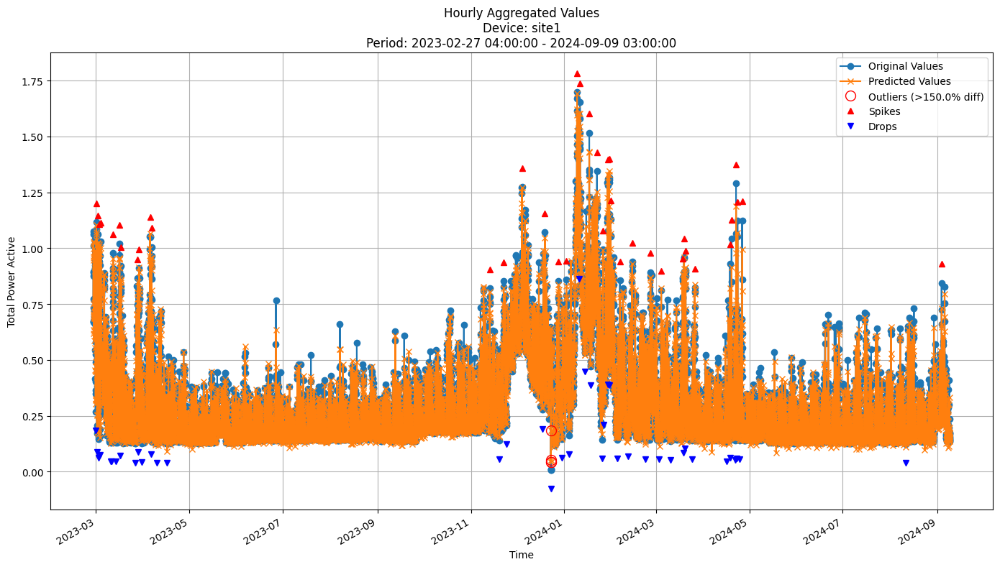


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0411
MAE: 0.0279
MAPE: 10.9339%

Directional Metrics:
Directional Accuracy: 60.0685%
First-Diff Correlation: 0.5683

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4118
  Recall: 0.3590
  F1 Score: 0.3836
Drops:
  Precision: 0.2059
  Recall: 0.1707
  F1 Score: 0.1867

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8529
  Recall: 0.7436
  F1 Score: 0.7945
Drops:
  Precision: 0.6765
  Recall: 0.5610
  F1 Score: 0.6133


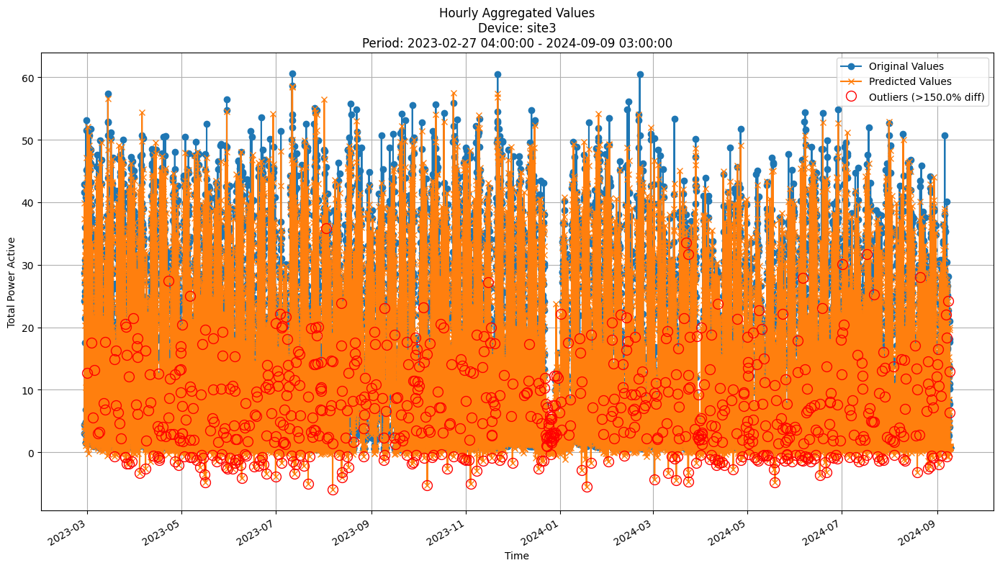


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.4070
MAE: 3.5608
MAPE: 46.9130%

Directional Metrics:
Directional Accuracy: 52.0911%
First-Diff Correlation: 0.4416

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


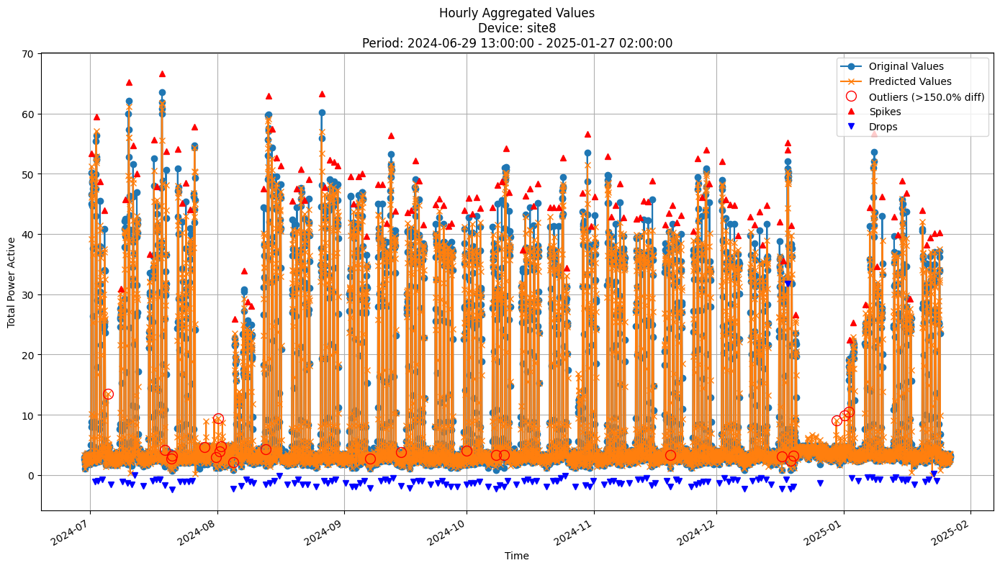


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5526
MAE: 1.0366
MAPE: 19.3773%

Directional Metrics:
Directional Accuracy: 53.1705%
First-Diff Correlation: 0.9002

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2847
  Recall: 0.2889
  F1 Score: 0.2868
Drops:
  Precision: 0.0221
  Recall: 0.0221
  F1 Score: 0.0221

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8832
  Recall: 0.8963
  F1 Score: 0.8897
Drops:
  Precision: 0.7132
  Recall: 0.7132
  F1 Score: 0.7132


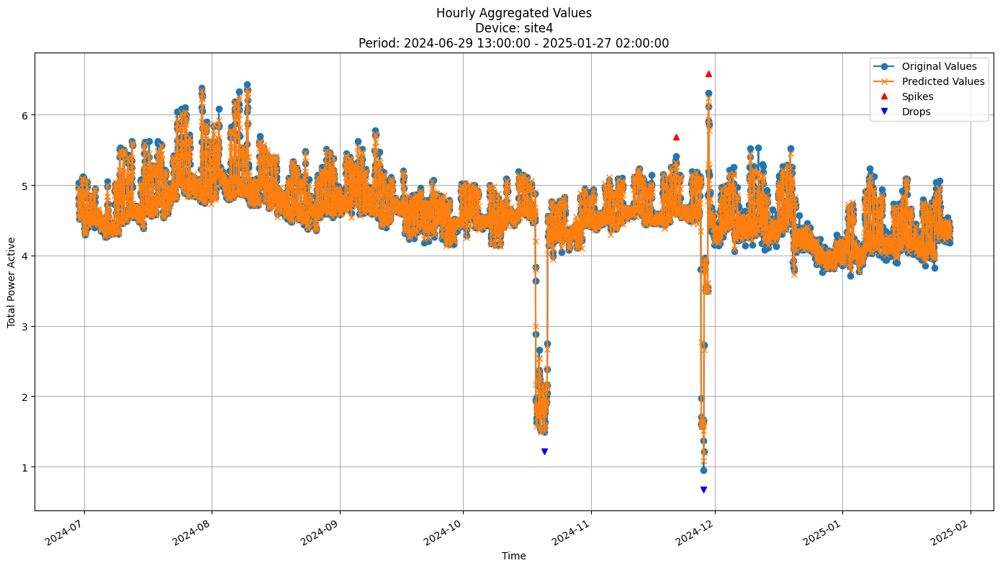


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0840
MAE: 0.0608
MAPE: 1.3457%

Directional Metrics:
Directional Accuracy: 54.6278%
First-Diff Correlation: 0.5275

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


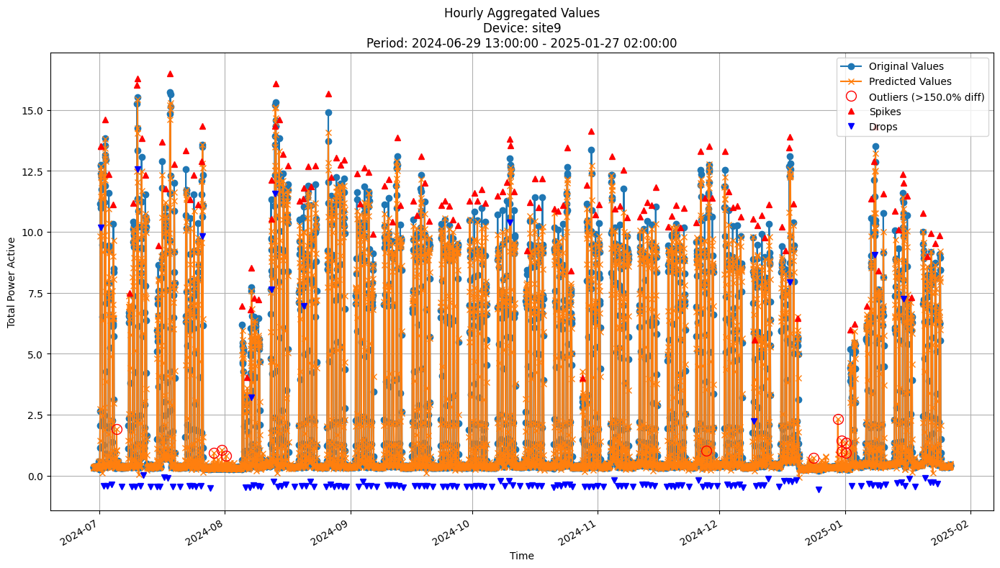


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3222
MAE: 0.1729
MAPE: 12.8215%

Directional Metrics:
Directional Accuracy: 55.3958%
First-Diff Correlation: 0.9352

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3121
  Recall: 0.2973
  F1 Score: 0.3045
Drops:
  Precision: 0.0429
  Recall: 0.0405
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8936
  Recall: 0.8514
  F1 Score: 0.8720
Drops:
  Precision: 0.3357
  Recall: 0.3176
  F1 Score: 0.3264


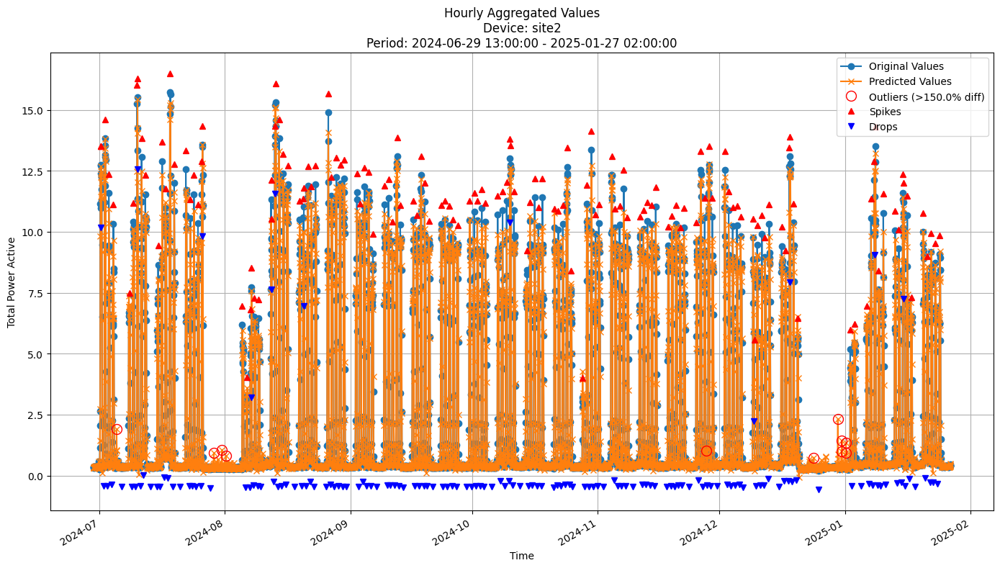


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3222
MAE: 0.1729
MAPE: 12.8215%

Directional Metrics:
Directional Accuracy: 55.3958%
First-Diff Correlation: 0.9352

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3121
  Recall: 0.2973
  F1 Score: 0.3045
Drops:
  Precision: 0.0429
  Recall: 0.0405
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8936
  Recall: 0.8514
  F1 Score: 0.8720
Drops:
  Precision: 0.3357
  Recall: 0.3176
  F1 Score: 0.3264


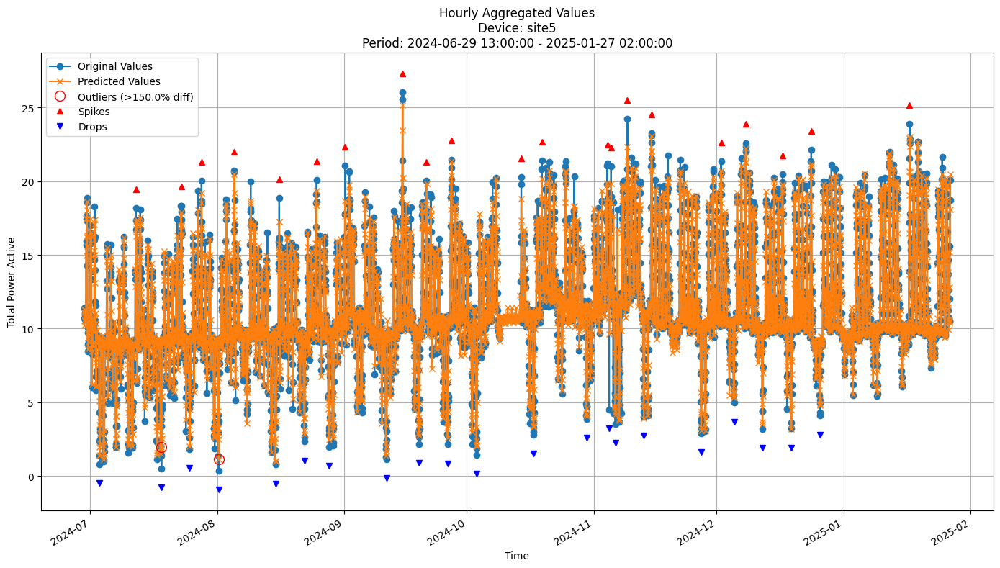


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6659
MAE: 0.4554
MAPE: 4.8216%

Directional Metrics:
Directional Accuracy: 65.2619%
First-Diff Correlation: 0.7363

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4000
  Recall: 0.2857
  F1 Score: 0.3333
Drops:
  Precision: 0.1875
  Recall: 0.1429
  F1 Score: 0.1622

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.4762
  F1 Score: 0.5556
Drops:
  Precision: 0.5625
  Recall: 0.4286
  F1 Score: 0.4865


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

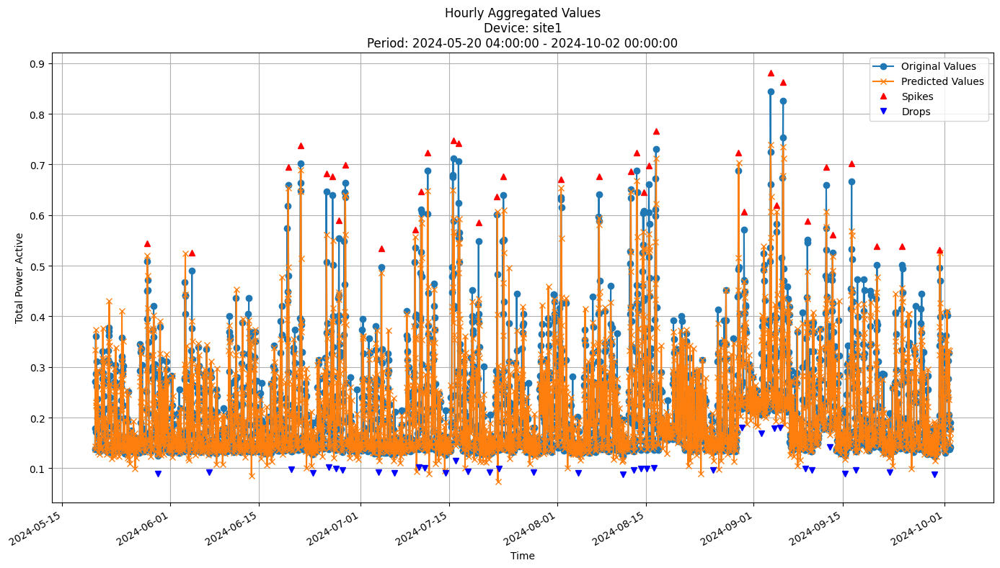


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0553
MAE: 0.0344
MAPE: 14.6426%

Directional Metrics:
Directional Accuracy: 50.7417%
First-Diff Correlation: 0.2691

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3214
  Recall: 0.2500
  F1 Score: 0.2813
Drops:
  Precision: 0.0370
  Recall: 0.0286
  F1 Score: 0.0323

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9286
  Recall: 0.7222
  F1 Score: 0.8125
Drops:
  Precision: 0.2593
  Recall: 0.2000
  F1 Score: 0.2258


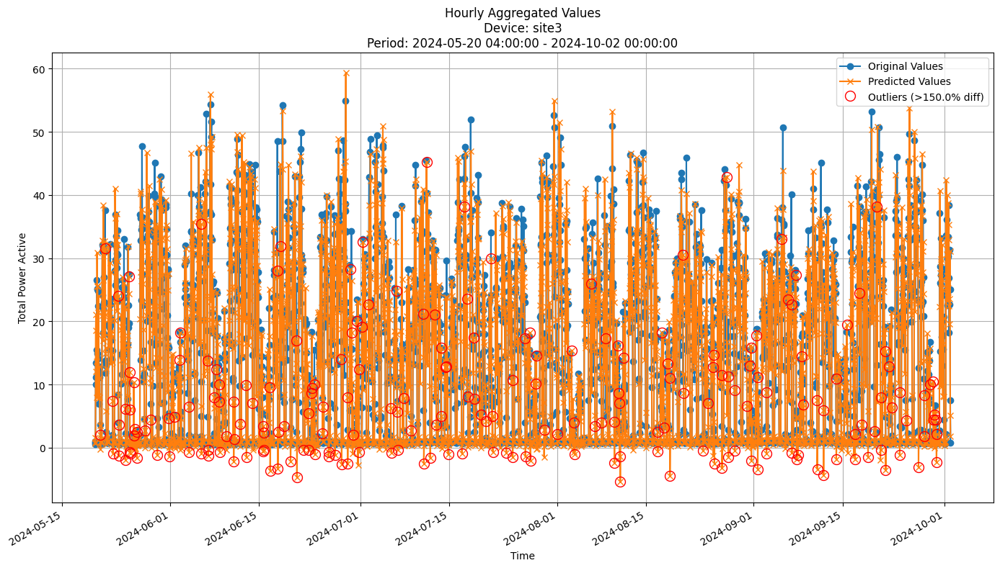


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.9110
MAE: 4.5389
MAPE: 55.5806%

Directional Metrics:
Directional Accuracy: 47.6514%
First-Diff Correlation: 0.1813

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


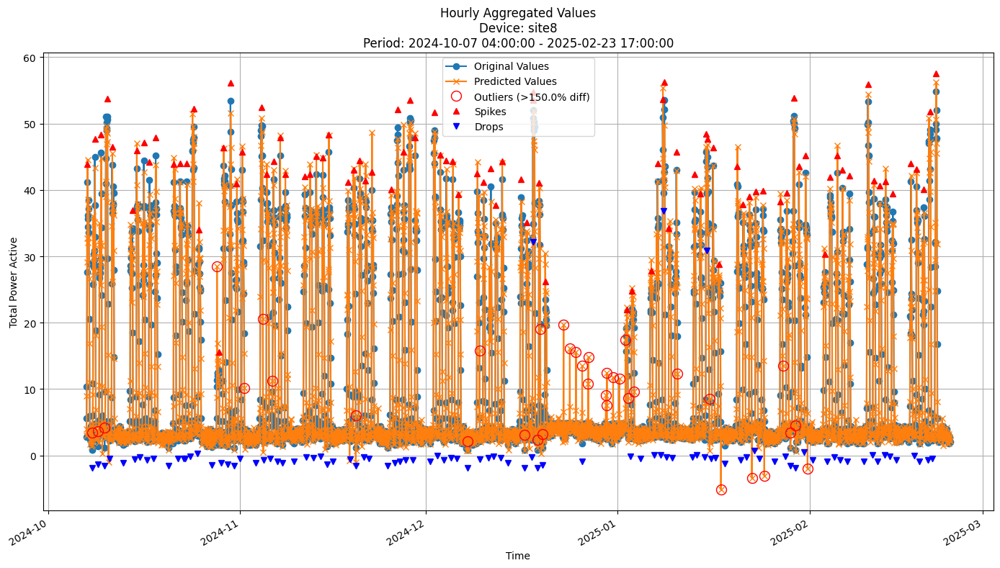


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.3167
MAE: 1.8337
MAPE: 25.2952%

Directional Metrics:
Directional Accuracy: 48.5672%
First-Diff Correlation: 0.5861

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0900
  Recall: 0.0947
  F1 Score: 0.0923
Drops:
  Precision: 0.0303
  Recall: 0.0316
  F1 Score: 0.0309

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8300
  Recall: 0.8737
  F1 Score: 0.8513
Drops:
  Precision: 0.4646
  Recall: 0.4842
  F1 Score: 0.4742


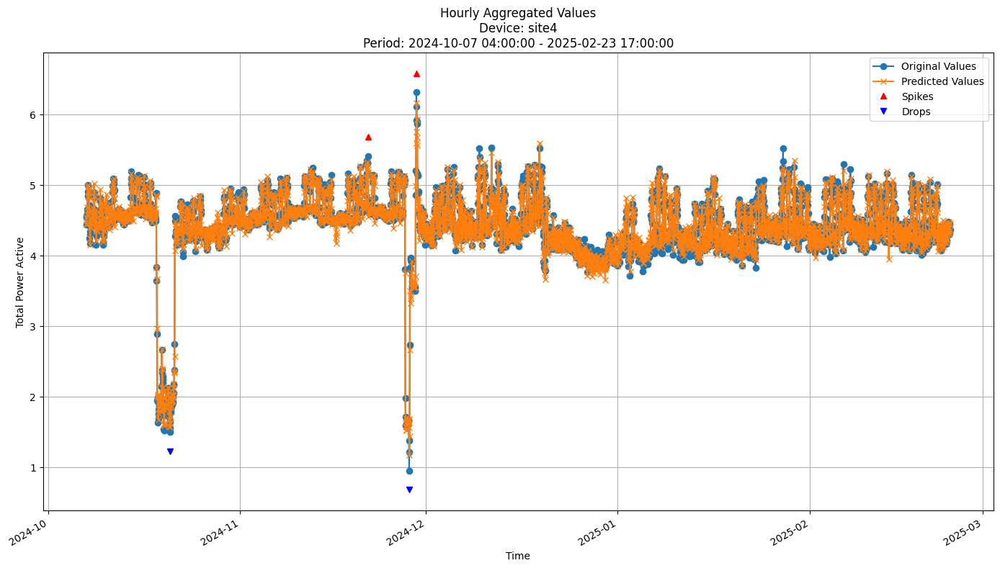


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1685
MAE: 0.1116
MAPE: 2.6208%

Directional Metrics:
Directional Accuracy: 40.9552%
First-Diff Correlation: -0.0833

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


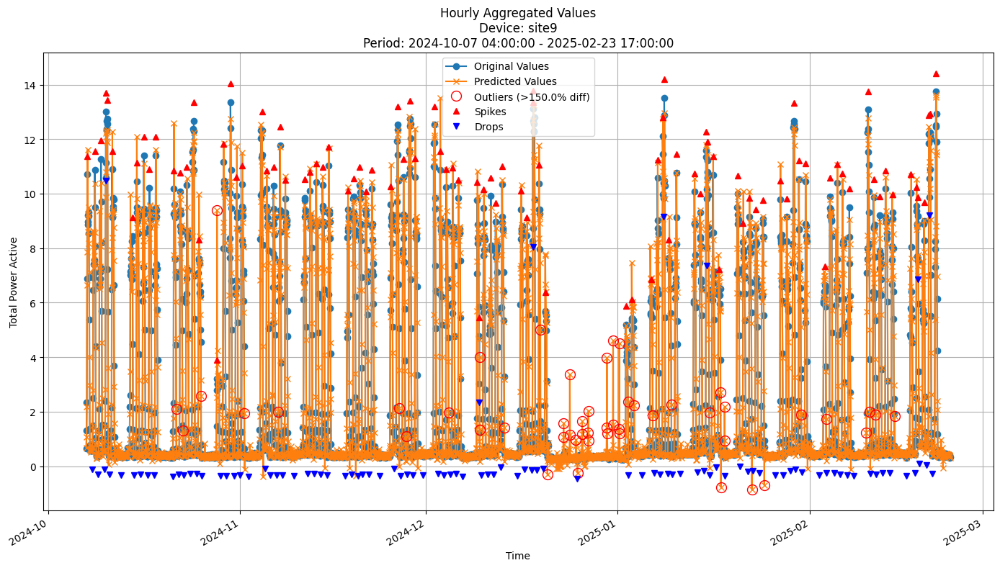


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7876
MAE: 0.3748
MAPE: 22.0622%

Directional Metrics:
Directional Accuracy: 51.6418%
First-Diff Correlation: 0.6258

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0948
  Recall: 0.1111
  F1 Score: 0.1023
Drops:
  Precision: 0.0435
  Recall: 0.0510
  F1 Score: 0.0469

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7500
  Recall: 0.8788
  F1 Score: 0.8093
Drops:
  Precision: 0.2522
  Recall: 0.2959
  F1 Score: 0.2723


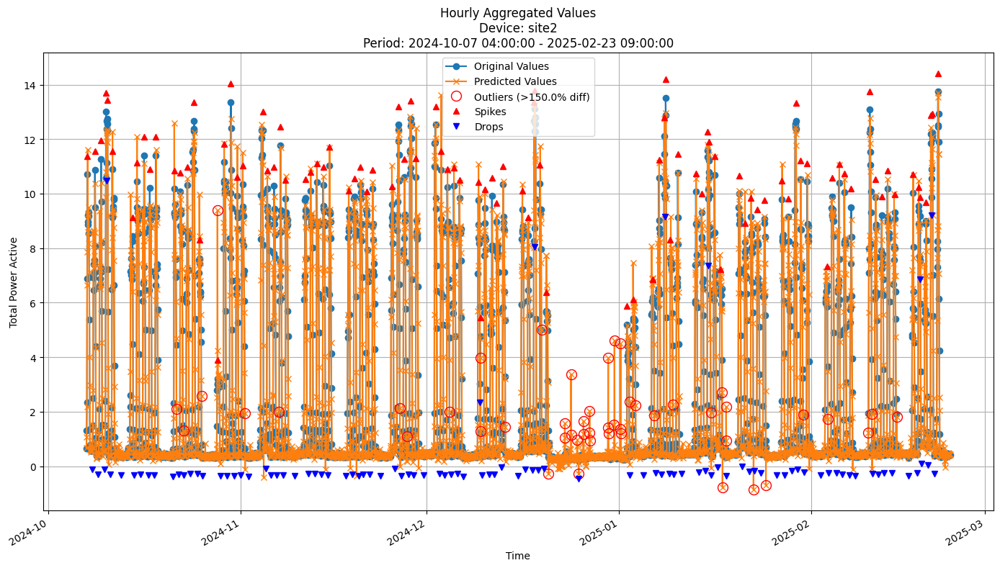


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7884
MAE: 0.3753
MAPE: 22.0367%

Directional Metrics:
Directional Accuracy: 51.5859%
First-Diff Correlation: 0.6257

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0957
  Recall: 0.1111
  F1 Score: 0.1028
Drops:
  Precision: 0.0351
  Recall: 0.0408
  F1 Score: 0.0377

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7565
  Recall: 0.8788
  F1 Score: 0.8131
Drops:
  Precision: 0.2632
  Recall: 0.3061
  F1 Score: 0.2830


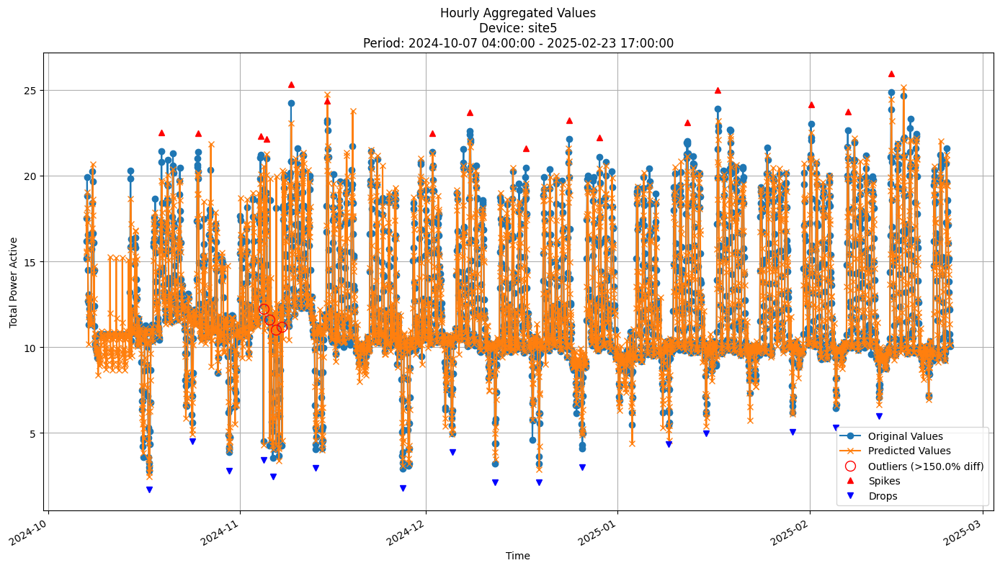


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2286
MAE: 0.7398
MAPE: 6.0217%

Directional Metrics:
Directional Accuracy: 59.6119%
First-Diff Correlation: 0.2720

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2000
  Recall: 0.1250
  F1 Score: 0.1538
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7000
  Recall: 0.4375
  F1 Score: 0.5385
Drops:
  Precision: 0.4000
  Recall: 0.2500
  F1 Score: 0.3077


In [19]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {
    'n_estimators': 300, 
     'max_depth': 20, 
     'max_features': 0.7, 
     'random_state': 42, 
     'n_jobs': -1
}

In [ ]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.32 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.30 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.119949 MB


 2023-02-27 04:00:00+01:00    0.769177
2023-02-27 05:00:00+01:00    0.996063
2023-02-27 06:00:00+01:00    0.936860
2023-02-27 07:00:00+01:00    0.995746
2023-02-27 08:00:00+01:00    0.931061
                               ...   
2023-03-26 23:00:00+02:00    0.145284
2023-03-27 00:00:00+02:00    0.162585
2023-03-27 01:00:00+02:00    0.188317
2023-03-27 02:00:00+02:00    0.223501
2023-03-27 03:00:00+02:00    0.234566
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.230038
2023-03-27 05:00:00+02:00    0.226721
2023-03-27

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.35 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.33 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.119942 MB


 2023-02-27 04:00:00+01:00    0.769583
2023-02-27 05:00:00+01:00    0.991925
2023-02-27 06:00:00+01:00    0.932960
2023-02-27 07:00:00+01:00    1.000503
2023-02-27 08:00:00+01:00    0.938212
                               ...   
2023-04-23 23:00:00+02:00    0.141574
2023-04-24 00:00:00+02:00    0.137509
2023-04-24 01:00:00+02:00    0.138787
2023-04-24 02:00:00+02:00    0.137662
2023-04-24 03:00:00+02:00    0.135271
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.143933
2023-04-24 05:00:00+02:00    0.166597
2023-04-2

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 0.46 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 0.49 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.119942 MB


 2024-06-29 13:00:00+02:00    3.146934
2024-06-29 14:00:00+02:00    2.641632
2024-06-29 15:00:00+02:00    2.223065
2024-06-29 16:00:00+02:00    2.417367
2024-06-29 17:00:00+02:00    2.271196
                               ...   
2024-12-29 22:00:00+01:00    3.616978
2024-12-29 23:00:00+01:00    3.236058
2024-12-30 00:00:00+01:00    3.646774
2024-12-30 01:00:00+01:00    4.287787
2024-12-30 02:00:00+01:00    3.979336
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00     3.494189
2024-12-30 04:00:00+01:00     4.417451
2024-12

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 0.51 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 0.54 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.119942 MB


 2024-06-29 13:00:00+02:00    3.076123
2024-06-29 14:00:00+02:00    2.696197
2024-06-29 15:00:00+02:00    2.167263
2024-06-29 16:00:00+02:00    2.362768
2024-06-29 17:00:00+02:00    2.362615
                               ...   
2025-01-26 22:00:00+01:00    3.230662
2025-01-26 23:00:00+01:00    2.747628
2025-01-27 00:00:00+01:00    3.055972
2025-01-27 01:00:00+01:00    2.851185
2025-01-27 02:00:00+01:00    3.288307
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     3.664632
2025-01-27 04:00:00+01:00     4.229452
2025-01

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0196 ± 0.0017
	MAE: 0.0134 ± 0.0013
	MAPE: 5.2919% ± 0.2769%

	Directional Metrics:
		Directional Accuracy: 80.6108% ± 2.6010%
		First-Diff Correlation: 0.9090 ± 0.0147

	Immediate Detection (delta=0):
		Spike Precision: 0.7018 ± 0.0337
		Spike Recall: 0.6179 ± 0.0403
		Spike F1: 0.6565 ± 0.0306
		Drop Precision: 0.4261 ± 0.0727
		Drop Recall: 0.3638 ± 0.0776
		Drop F1: 0.3921 ± 0.0754

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9019 ± 0.0339
		Spike Recall: 0.7947 ± 0.0555
		Spike F1: 0.8440 ± 0.0386
		Drop Precision: 0.6606 ± 0.0777
		Drop Recall: 0.5631 ± 0.0901
		Drop F1: 0.6074 ± 0.0843
Daily Metrics:
	RMSE: 0.0638 ± 0.0081
	MAE: 0.0490 ± 0.0088
	MAPE: 0.7398% ± 0.0844%

	Directional Metrics:
		Directional Accuracy: 98.2265% ± 0.8167%
		First-Diff Correlation: 0.9991 ± 0.0002

	Immediate Detection (delta=0):
		Spike

#### Training plots
Plot only the last period of predictions

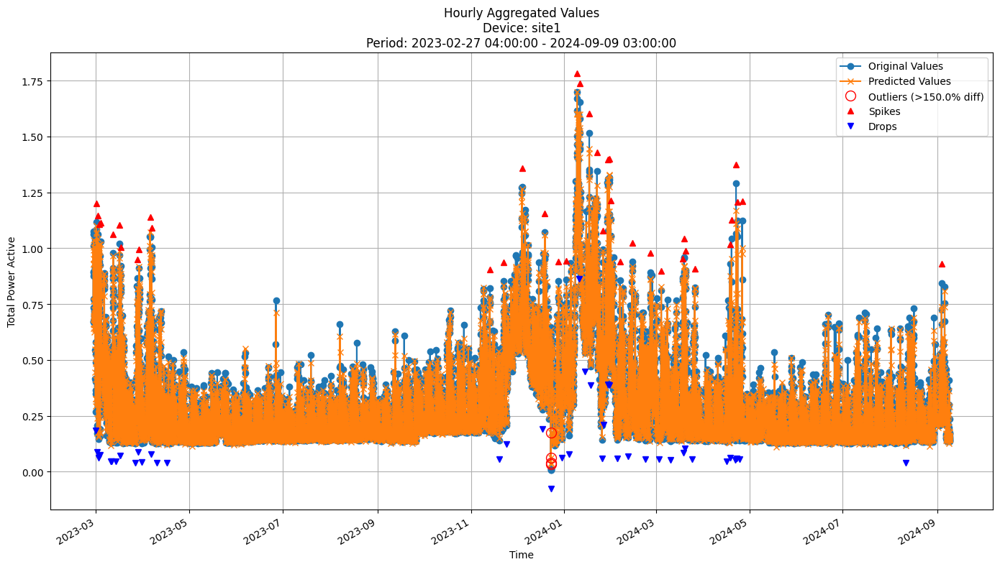


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0217
MAE: 0.0148
MAPE: 5.8741%

Directional Metrics:
Directional Accuracy: 76.6260%
First-Diff Correlation: 0.8844

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5556
  Recall: 0.5128
  F1 Score: 0.5333
Drops:
  Precision: 0.4722
  Recall: 0.4146
  F1 Score: 0.4416

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.7692
  F1 Score: 0.8000
Drops:
  Precision: 0.6111
  Recall: 0.5366
  F1 Score: 0.5714


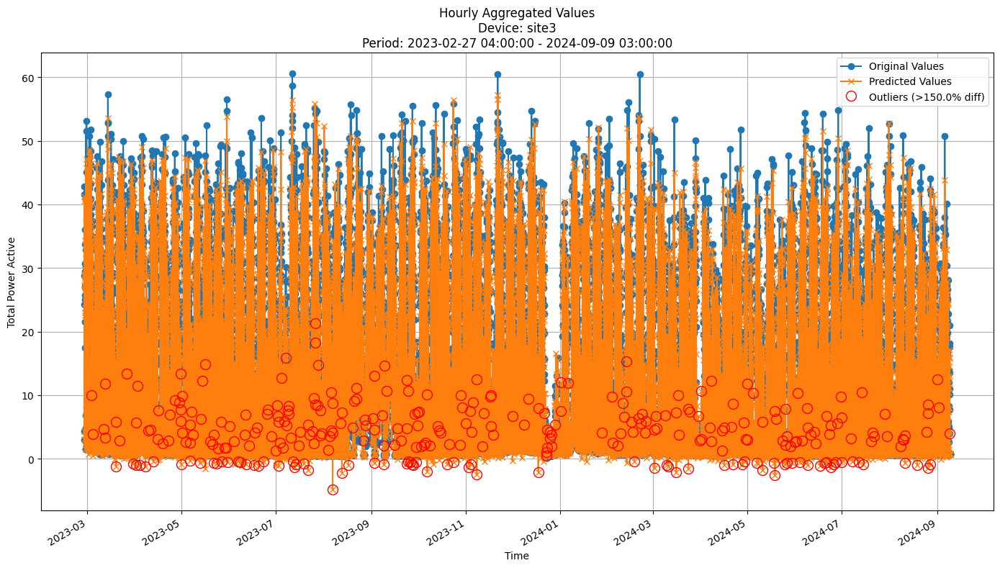


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.9670
MAE: 1.9484
MAPE: 23.7847%

Directional Metrics:
Directional Accuracy: 68.1798%
First-Diff Correlation: 0.8388

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


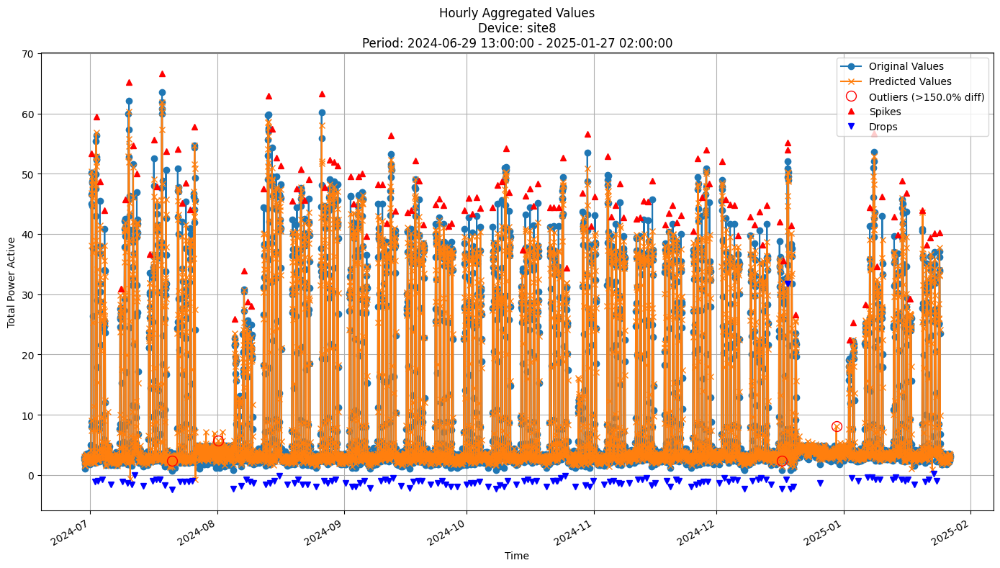


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2304
MAE: 0.7333
MAPE: 12.3530%

Directional Metrics:
Directional Accuracy: 68.3734%
First-Diff Correlation: 0.9385

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3382
  Recall: 0.3407
  F1 Score: 0.3395
Drops:
  Precision: 0.2444
  Recall: 0.2426
  F1 Score: 0.2435

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9191
  Recall: 0.9259
  F1 Score: 0.9225
Drops:
  Precision: 0.6296
  Recall: 0.6250
  F1 Score: 0.6273


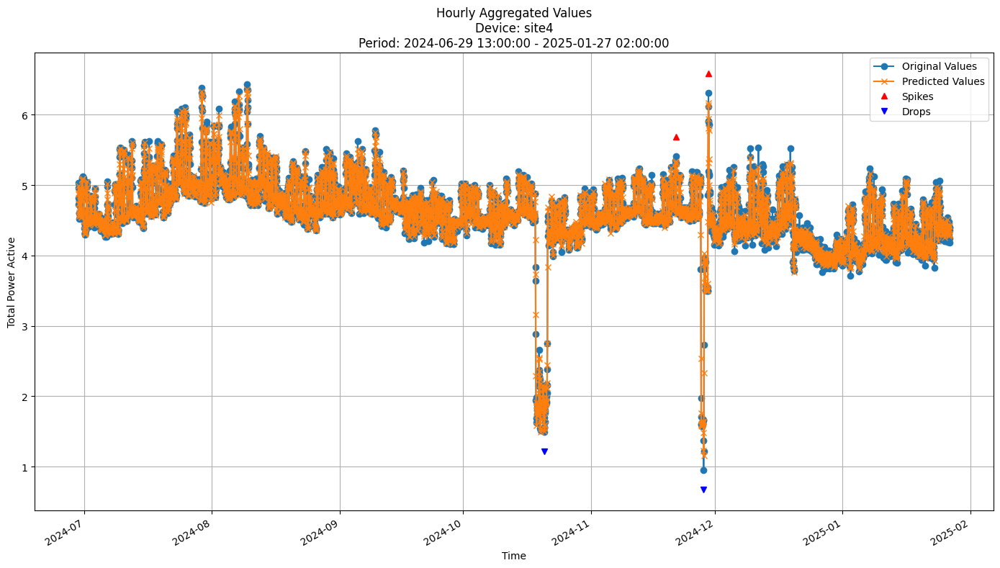


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0550
MAE: 0.0384
MAPE: 0.8586%

Directional Metrics:
Directional Accuracy: 69.3186%
First-Diff Correlation: 0.8084

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


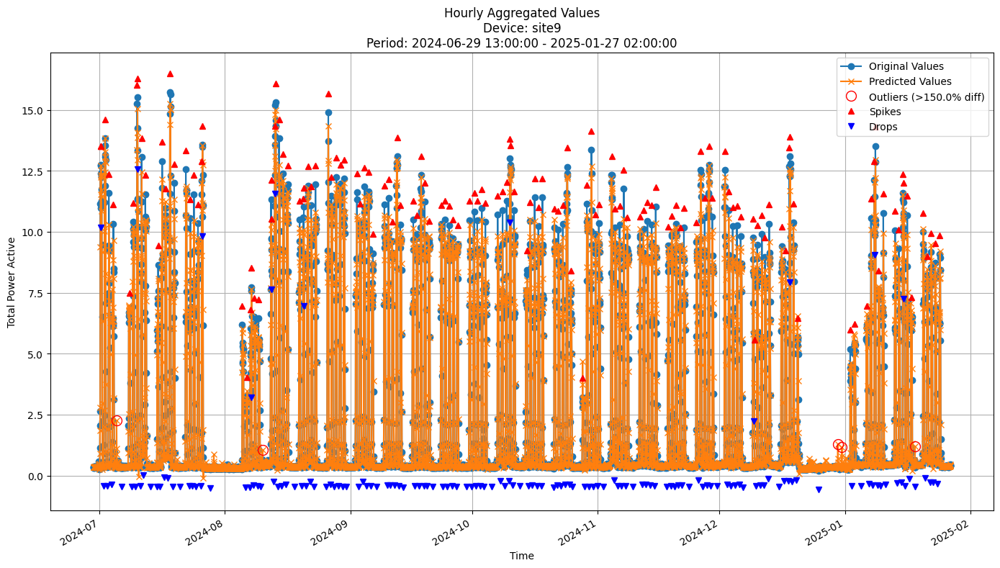


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2864
MAE: 0.1305
MAPE: 7.1573%

Directional Metrics:
Directional Accuracy: 74.1237%
First-Diff Correlation: 0.9476

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3427
  Recall: 0.3311
  F1 Score: 0.3368
Drops:
  Precision: 0.2113
  Recall: 0.2027
  F1 Score: 0.2069

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9231
  Recall: 0.8919
  F1 Score: 0.9072
Drops:
  Precision: 0.3732
  Recall: 0.3581
  F1 Score: 0.3655


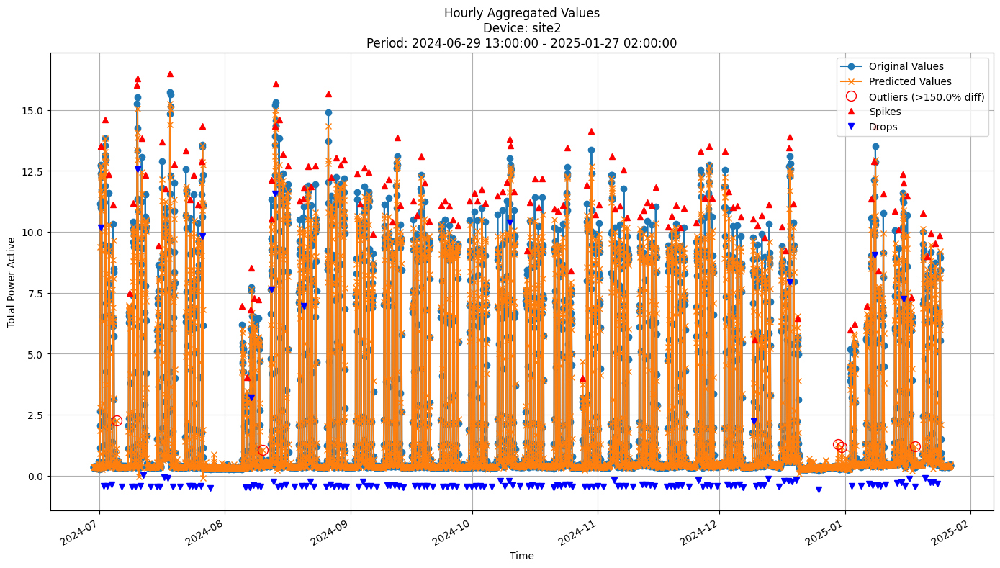


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2864
MAE: 0.1305
MAPE: 7.1574%

Directional Metrics:
Directional Accuracy: 74.1237%
First-Diff Correlation: 0.9476

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3427
  Recall: 0.3311
  F1 Score: 0.3368
Drops:
  Precision: 0.2113
  Recall: 0.2027
  F1 Score: 0.2069

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9231
  Recall: 0.8919
  F1 Score: 0.9072
Drops:
  Precision: 0.3732
  Recall: 0.3581
  F1 Score: 0.3655


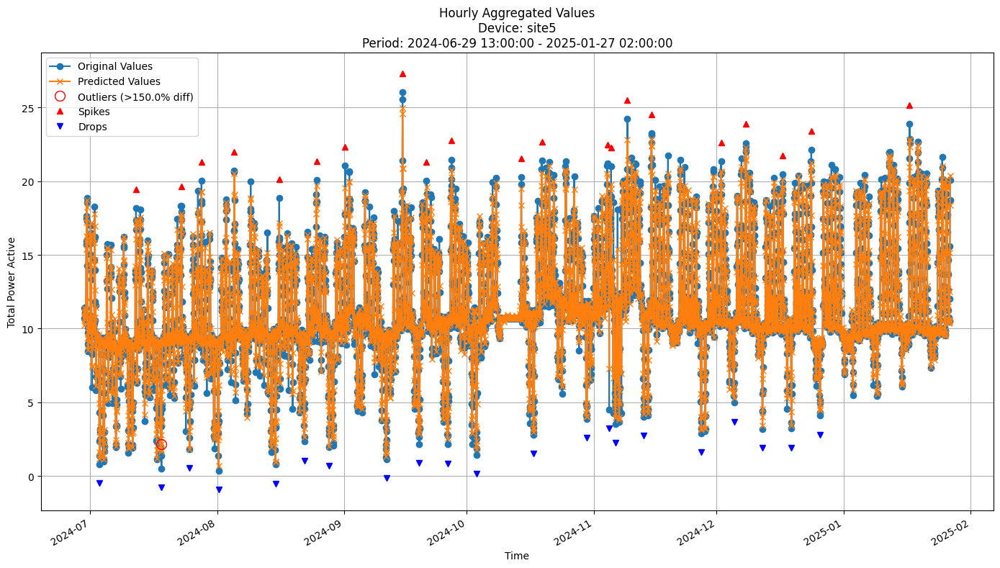


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4342
MAE: 0.2898
MAPE: 3.0369%

Directional Metrics:
Directional Accuracy: 74.4978%
First-Diff Correlation: 0.8896

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4118
  Recall: 0.3333
  F1 Score: 0.3684
Drops:
  Precision: 0.4444
  Recall: 0.3810
  F1 Score: 0.4103

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7059
  Recall: 0.5714
  F1 Score: 0.6316
Drops:
  Precision: 0.7222
  Recall: 0.6190
  F1 Score: 0.6667


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

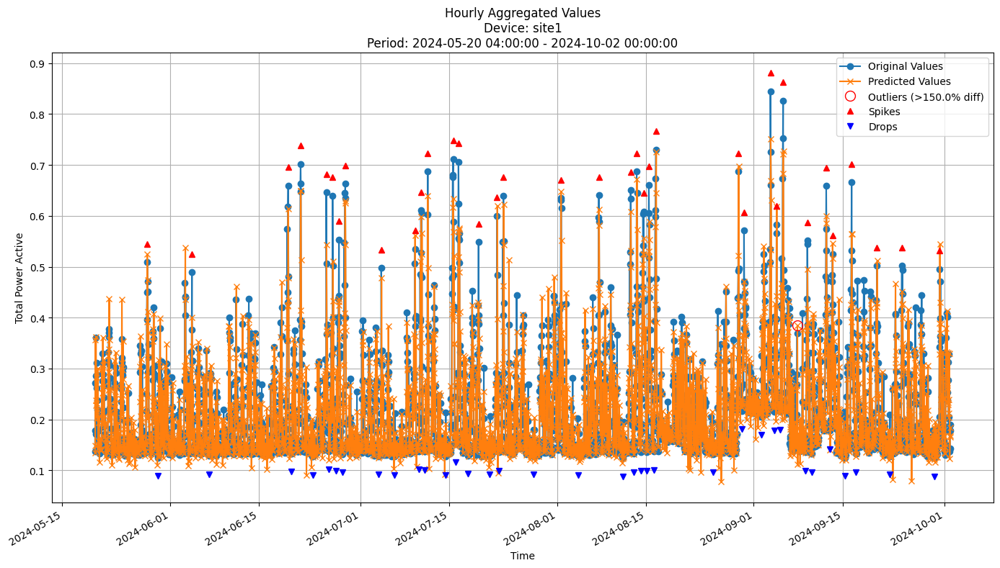


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0556
MAE: 0.0348
MAPE: 14.9023%

Directional Metrics:
Directional Accuracy: 50.4017%
First-Diff Correlation: 0.2733

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3226
  Recall: 0.2778
  F1 Score: 0.2985
Drops:
  Precision: 0.0667
  Recall: 0.0571
  F1 Score: 0.0615

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8710
  Recall: 0.7500
  F1 Score: 0.8060
Drops:
  Precision: 0.3000
  Recall: 0.2571
  F1 Score: 0.2769


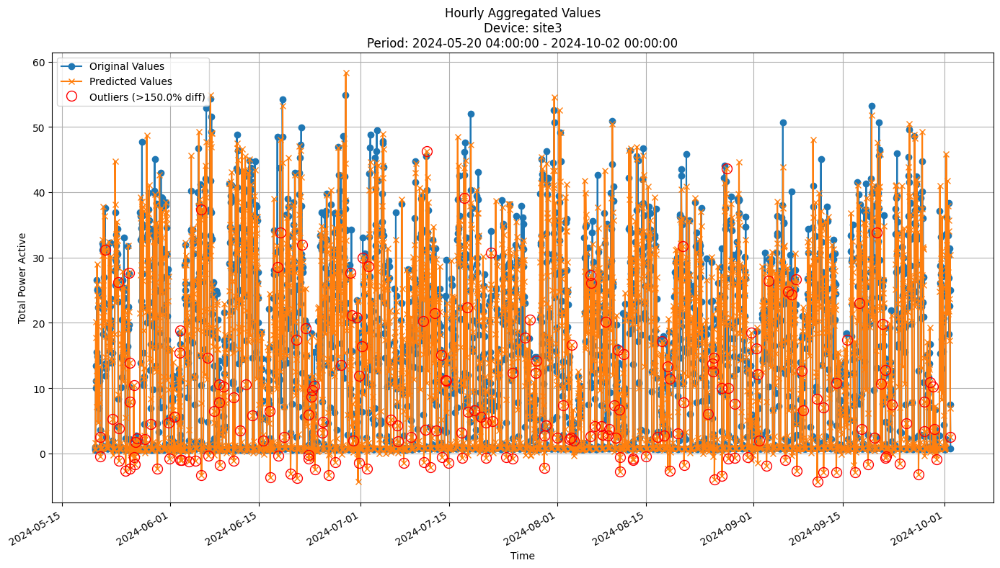


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.0035
MAE: 4.5621
MAPE: 51.8144%

Directional Metrics:
Directional Accuracy: 46.0136%
First-Diff Correlation: 0.1766

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


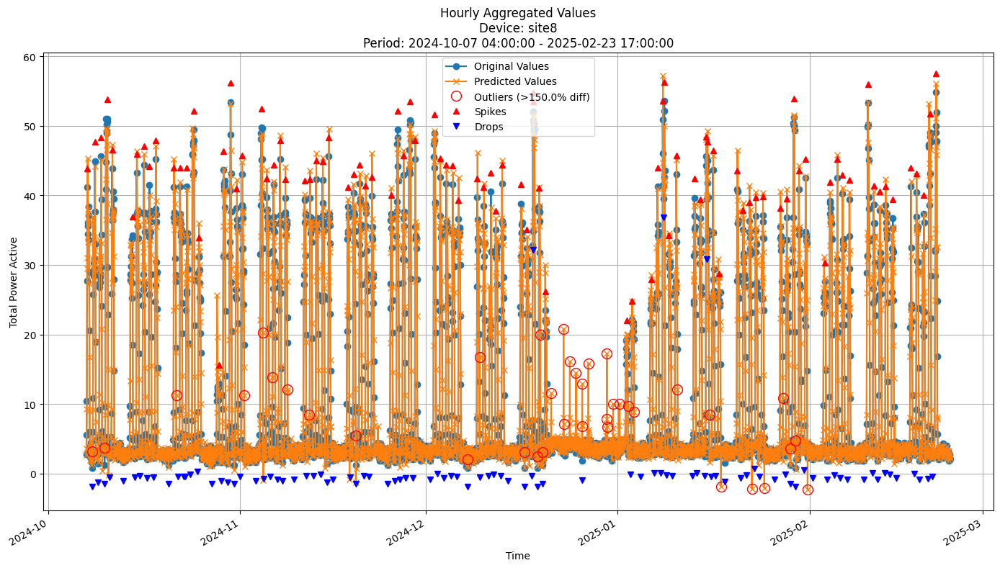


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.2908
MAE: 1.8114
MAPE: 25.1457%

Directional Metrics:
Directional Accuracy: 48.3582%
First-Diff Correlation: 0.5800

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1122
  Recall: 0.1158
  F1 Score: 0.1140
Drops:
  Precision: 0.0309
  Recall: 0.0316
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8776
  Recall: 0.9053
  F1 Score: 0.8912
Drops:
  Precision: 0.4536
  Recall: 0.4632
  F1 Score: 0.4583


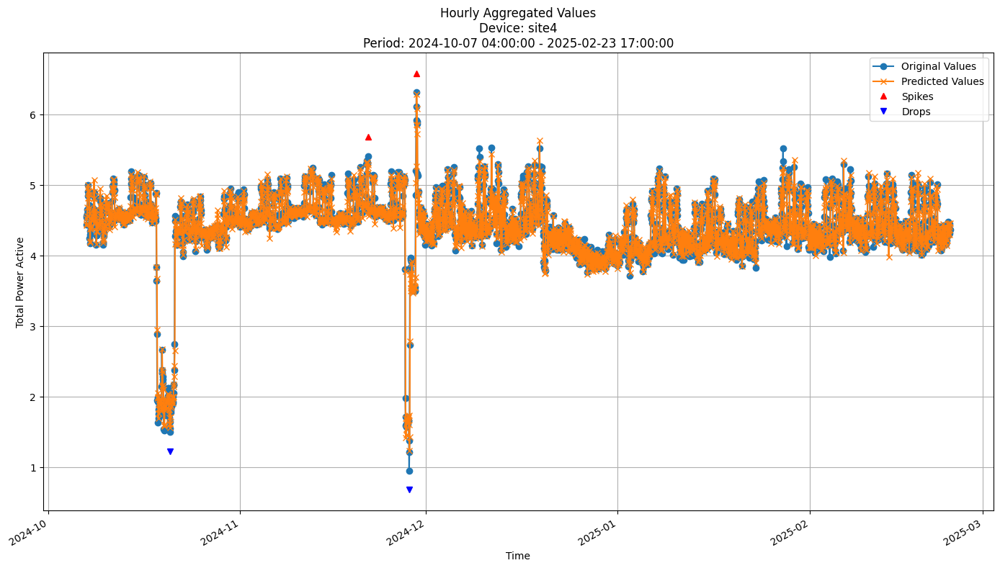


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1653
MAE: 0.1085
MAPE: 2.5450%

Directional Metrics:
Directional Accuracy: 41.3731%
First-Diff Correlation: -0.0860

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


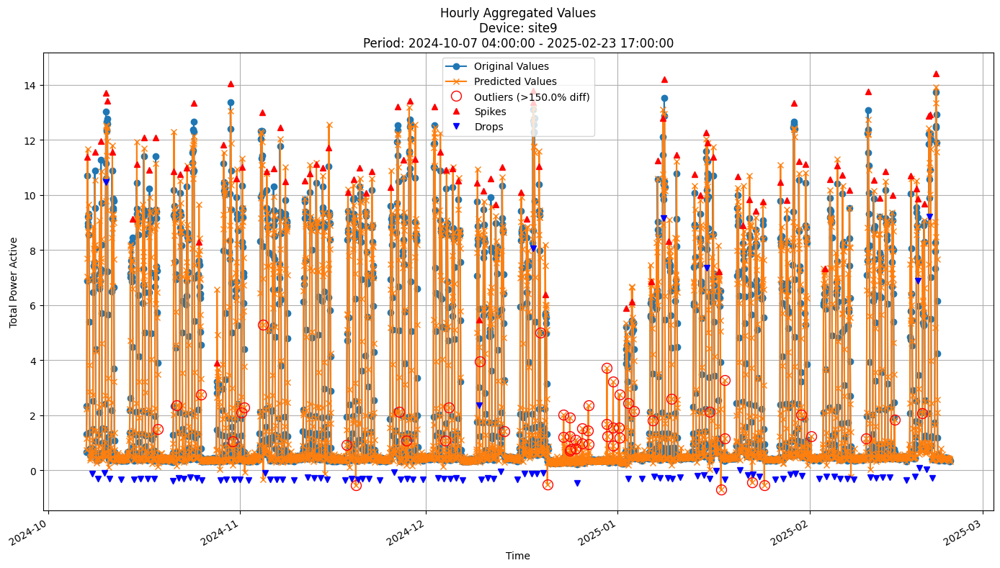


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7738
MAE: 0.3657
MAPE: 20.9116%

Directional Metrics:
Directional Accuracy: 52.0896%
First-Diff Correlation: 0.6271

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0870
  Recall: 0.1010
  F1 Score: 0.0935
Drops:
  Precision: 0.0614
  Recall: 0.0714
  F1 Score: 0.0660

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7739
  Recall: 0.8990
  F1 Score: 0.8318
Drops:
  Precision: 0.3421
  Recall: 0.3980
  F1 Score: 0.3679


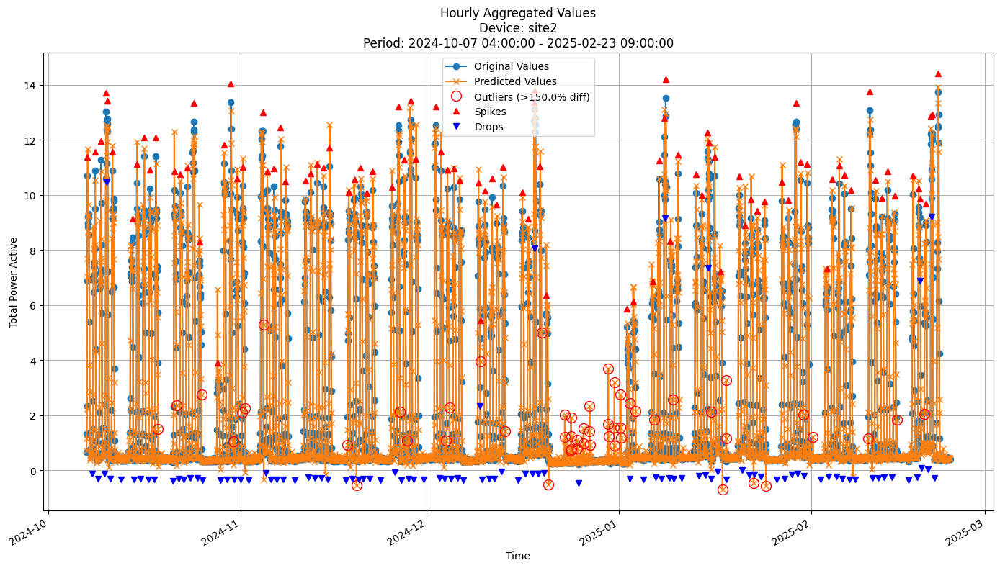


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7747
MAE: 0.3665
MAPE: 20.9367%

Directional Metrics:
Directional Accuracy: 52.1544%
First-Diff Correlation: 0.6271

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0783
  Recall: 0.0909
  F1 Score: 0.0841
Drops:
  Precision: 0.0614
  Recall: 0.0714
  F1 Score: 0.0660

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7652
  Recall: 0.8889
  F1 Score: 0.8224
Drops:
  Precision: 0.3421
  Recall: 0.3980
  F1 Score: 0.3679


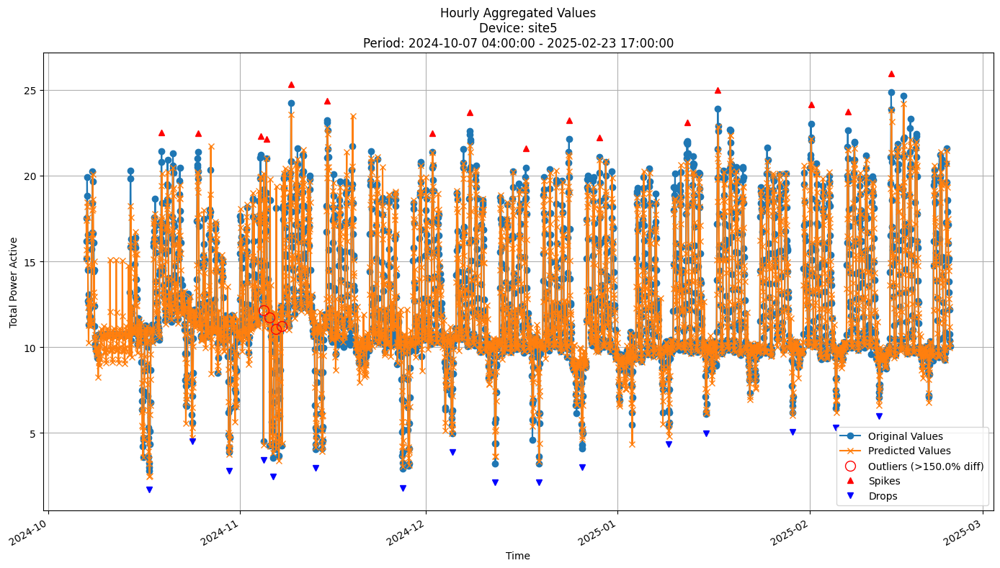


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1969
MAE: 0.7150
MAPE: 5.8138%

Directional Metrics:
Directional Accuracy: 60.0896%
First-Diff Correlation: 0.2807

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1818
  Recall: 0.1250
  F1 Score: 0.1481
Drops:
  Precision: 0.2727
  Recall: 0.1875
  F1 Score: 0.2222

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6364
  Recall: 0.4375
  F1 Score: 0.5185
Drops:
  Precision: 0.5455
  Recall: 0.3750
  F1 Score: 0.4444


In [24]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {
    'max_depth': 15, 
     'grace_period': 10, 
     'tau': 0.1, 
     'delta': 0.01,
    'leaf_prediction': 'mean'
}

In [ ]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.543228 MB


 2023-02-27 04:00:00+01:00    0.754779
2023-02-27 05:00:00+01:00    0.923875
2023-02-27 06:00:00+01:00    1.020776
2023-02-27 07:00:00+01:00    0.837539
2023-02-27 08:00:00+01:00    1.093692
                               ...   
2023-03-26 23:00:00+02:00    0.129422
2023-03-27 00:00:00+02:00    0.138922
2023-03-27 01:00:00+02:00    0.163672
2023-03-27 02:00:00+02:00    0.213529
2023-03-27 03:00:00+02:00    0.258529
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.236279
2023-03-27 05:00:00+02:00    0.226866
2023-03-27 06:00:00+02:00    0.398625
2023-03-27 07:00:00+02:00    0.415276
2023-03-27 08:00:00+02:00    0.408819
                               ...   
2023-04-23 23:00:00+02:00    0.138125
2023-04-24 00:00:00+02:00    0.144119
20

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.716362 MB


 2023-02-27 04:00:00+01:00    0.761889
2023-02-27 05:00:00+01:00    0.914147
2023-02-27 06:00:00+01:00    1.002078
2023-02-27 07:00:00+01:00    0.838633
2023-02-27 08:00:00+01:00    1.089250
                               ...   
2023-04-23 23:00:00+02:00    0.137946
2023-04-24 00:00:00+02:00    0.143946
2023-04-24 01:00:00+02:00    0.143946
2023-04-24 02:00:00+02:00    0.144979
2023-04-24 03:00:00+02:00    0.139479
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.143229
2023-04-24 05:00:00+02:00    0.170028
2023-04-24 06:00:00+02:00    0.319647
2023-04-24 07:00:00+02:00    0.269578
2023-04-24 08:00:00+02:00    0.301853
                               ...   
2023-05-21 23:00:00+02:00    0.194779
2023-05-22 00:00:00+02:00    0.175390
2

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 2.666077 MB


 2024-06-29 13:00:00+02:00     2.728923
2024-06-29 14:00:00+02:00     1.855264
2024-06-29 15:00:00+02:00     0.762724
2024-06-29 16:00:00+02:00     1.746963
2024-06-29 17:00:00+02:00     2.879306
                               ...    
2024-12-29 22:00:00+01:00     3.365133
2024-12-29 23:00:00+01:00     2.714826
2024-12-30 00:00:00+01:00     2.666310
2024-12-30 01:00:00+01:00     6.499280
2024-12-30 02:00:00+01:00    12.970947
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00     3.095668
2024-12-30 04:00:00+01:00     3.930891
2024-12-30 05:00:00+01:00     5.857377
2024-12-30 06:00:00+01:00    11.061882
2024-12-30 07:00:00+01:00     4.134134
                               ...    
2025-01-26 22:00:00+01:00     3.406586
2025-01-26 23:00:00+0

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 2.926239 MB


 2024-06-29 13:00:00+02:00    3.619960
2024-06-29 14:00:00+02:00    1.815002
2024-06-29 15:00:00+02:00    0.930995
2024-06-29 16:00:00+02:00    2.207126
2024-06-29 17:00:00+02:00    2.864928
                               ...   
2025-01-26 22:00:00+01:00    3.392228
2025-01-26 23:00:00+01:00    2.648915
2025-01-27 00:00:00+01:00    3.720789
2025-01-27 01:00:00+01:00    2.368234
2025-01-27 02:00:00+01:00    4.451035
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     4.231306
2025-01-27 04:00:00+01:00     3.921126
2025-01-27 05:00:00+01:00     3.377835
2025-01-27 06:00:00+01:00    10.751039
2025-01-27 07:00:00+01:00    39.942252
                               ...    
2025-02-23 13:00:00+01:00     1.278494
2025-02-23 14:00:00+01:00     2.

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0550 ± 0.0046
	MAE: 0.0365 ± 0.0038
	MAPE: 13.7786% ± 0.4442%

	Directional Metrics:
		Directional Accuracy: 59.1759% ± 2.7526%
		First-Diff Correlation: 0.3889 ± 0.0632

	Immediate Detection (delta=0):
		Spike Precision: 0.2010 ± 0.0428
		Spike Recall: 0.1958 ± 0.0264
		Spike F1: 0.1978 ± 0.0335
		Drop Precision: 0.1168 ± 0.0264
		Drop Recall: 0.1131 ± 0.0334
		Drop F1: 0.1146 ± 0.0296

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6922 ± 0.0637
		Spike Recall: 0.6829 ± 0.0433
		Spike F1: 0.6854 ± 0.0396
		Drop Precision: 0.4851 ± 0.0564
		Drop Recall: 0.4656 ± 0.0759
		Drop F1: 0.4738 ± 0.0622
Daily Metrics:
	RMSE: 0.2070 ± 0.0293
	MAE: 0.1454 ± 0.0284
	MAPE: 2.0400% ± 0.2072%

	Directional Metrics:
		Directional Accuracy: 95.9946% ± 1.0796%
		First-Diff Correlation: 0.9921 ± 0.0014

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

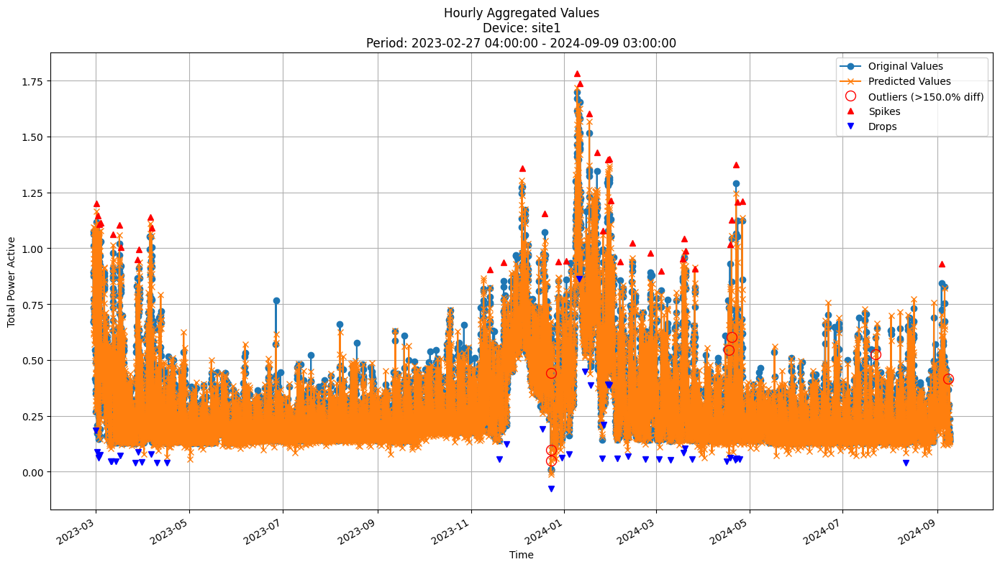


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0582
MAE: 0.0380
MAPE: 14.2888%

Directional Metrics:
Directional Accuracy: 55.8044%
First-Diff Correlation: 0.3057

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0667
  Recall: 0.0513
  F1 Score: 0.0580
Drops:
  Precision: 0.0645
  Recall: 0.0488
  F1 Score: 0.0556

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.6410
  F1 Score: 0.7246
Drops:
  Precision: 0.5484
  Recall: 0.4146
  F1 Score: 0.4722


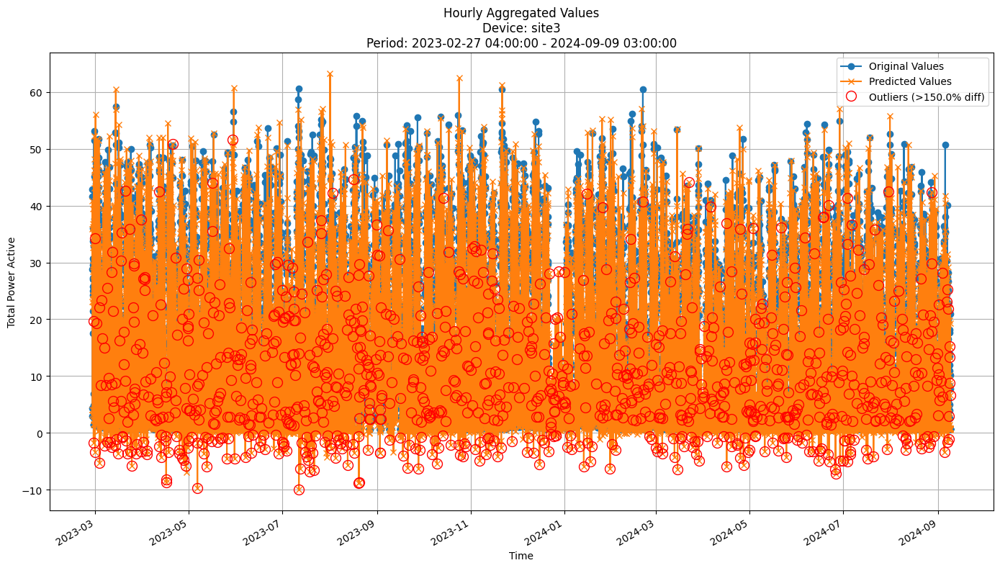


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.4565
MAE: 4.8565
MAPE: 63.5368%

Directional Metrics:
Directional Accuracy: 47.1722%
First-Diff Correlation: 0.1387

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


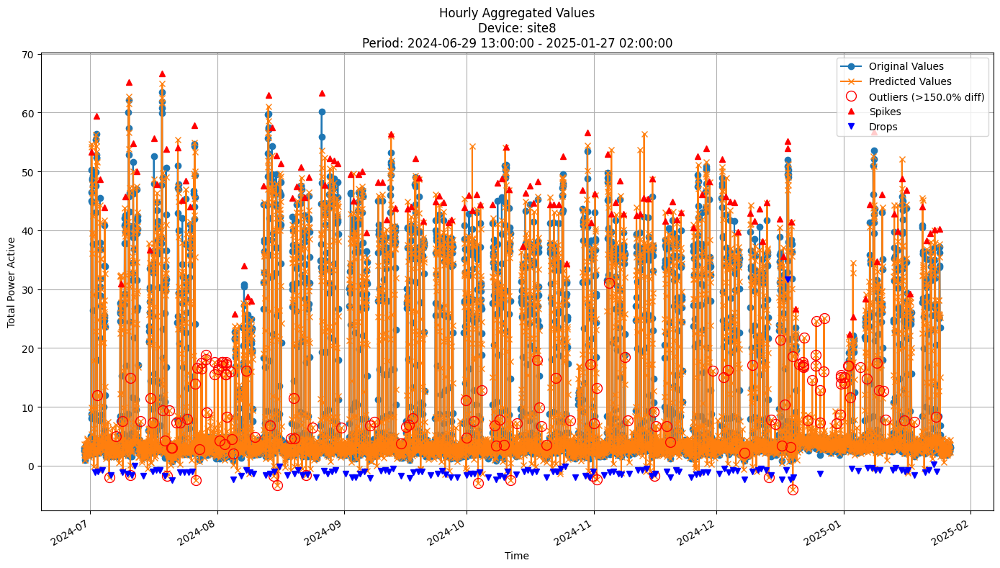


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.1178
MAE: 2.2234
MAPE: 33.2442%

Directional Metrics:
Directional Accuracy: 51.2210%
First-Diff Correlation: 0.4538

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0968
  Recall: 0.1111
  F1 Score: 0.1034
Drops:
  Precision: 0.0390
  Recall: 0.0441
  F1 Score: 0.0414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7290
  Recall: 0.8370
  F1 Score: 0.7793
Drops:
  Precision: 0.2078
  Recall: 0.2353
  F1 Score: 0.2207


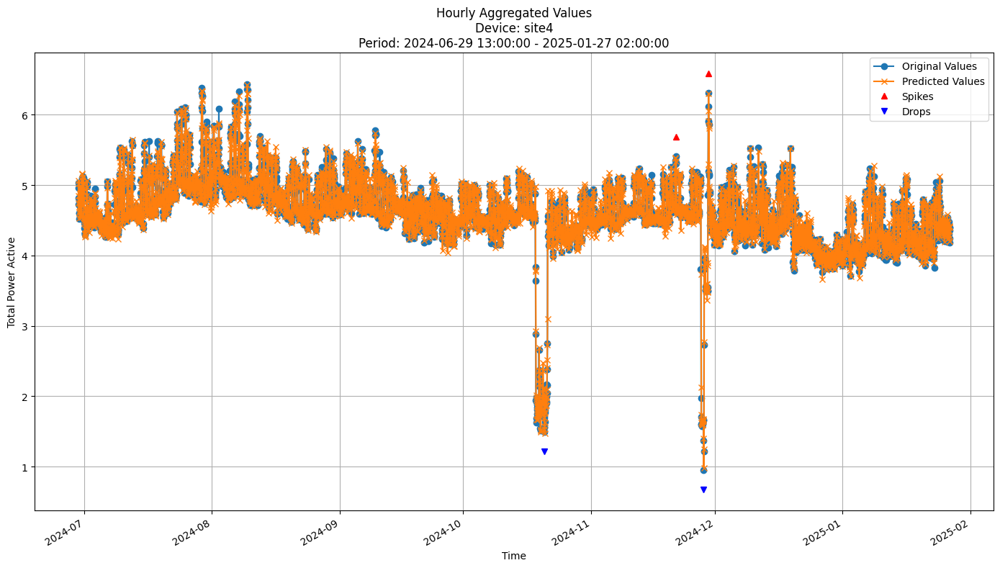


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1374
MAE: 0.0904
MAPE: 2.0389%

Directional Metrics:
Directional Accuracy: 47.5384%
First-Diff Correlation: 0.1038

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


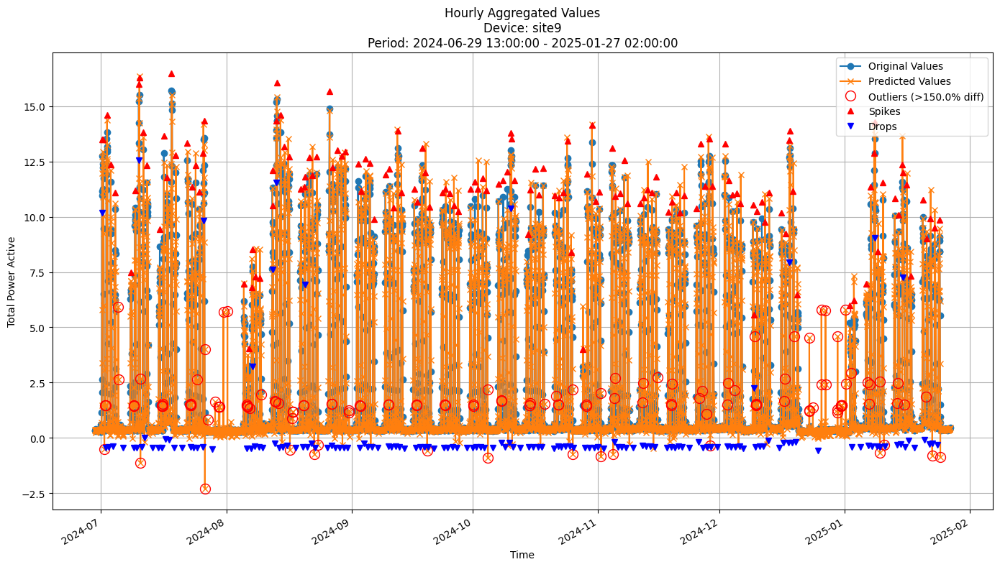


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8806
MAE: 0.4143
MAPE: 26.8512%

Directional Metrics:
Directional Accuracy: 49.7046%
First-Diff Correlation: 0.5881

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0751
  Recall: 0.0878
  F1 Score: 0.0810
Drops:
  Precision: 0.0289
  Recall: 0.0338
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7688
  Recall: 0.8986
  F1 Score: 0.8287
Drops:
  Precision: 0.2428
  Recall: 0.2838
  F1 Score: 0.2617


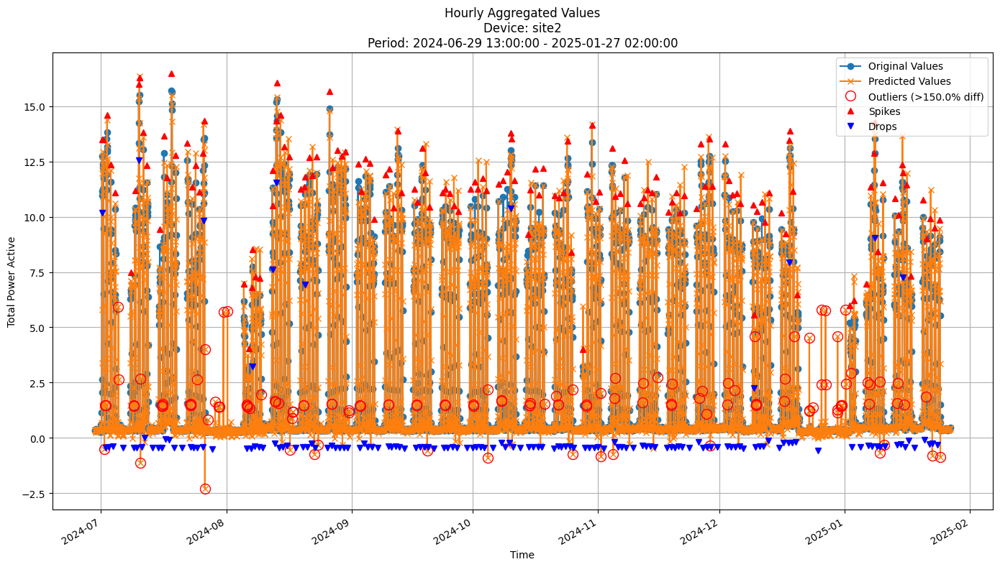


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8806
MAE: 0.4143
MAPE: 26.8512%

Directional Metrics:
Directional Accuracy: 49.7046%
First-Diff Correlation: 0.5881

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0751
  Recall: 0.0878
  F1 Score: 0.0810
Drops:
  Precision: 0.0289
  Recall: 0.0338
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7688
  Recall: 0.8986
  F1 Score: 0.8287
Drops:
  Precision: 0.2428
  Recall: 0.2838
  F1 Score: 0.2617


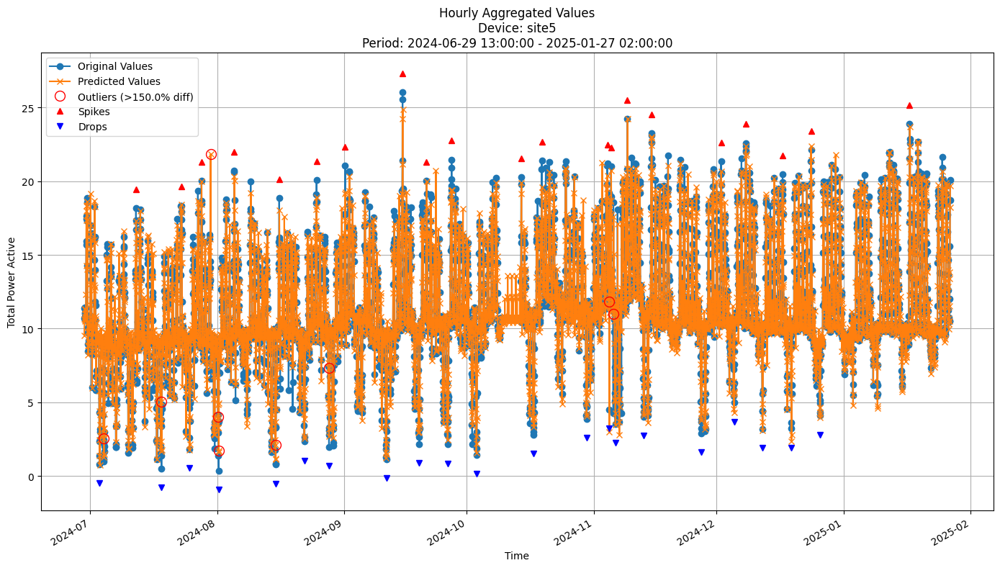


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2550
MAE: 0.8000
MAPE: 8.4159%

Directional Metrics:
Directional Accuracy: 60.8310%
First-Diff Correlation: 0.2783

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0526
  Recall: 0.0476
  F1 Score: 0.0500
Drops:
  Precision: 0.1579
  Recall: 0.1429
  F1 Score: 0.1500

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4211
  Recall: 0.3810
  F1 Score: 0.4000
Drops:
  Precision: 0.6316
  Recall: 0.5714
  F1 Score: 0.6000


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

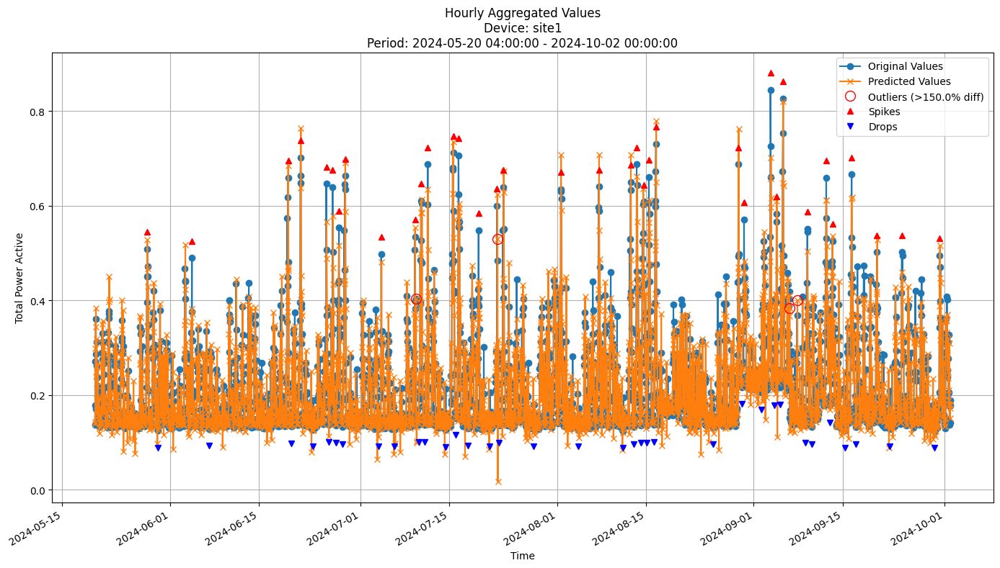


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0574
MAE: 0.0361
MAPE: 15.7234%

Directional Metrics:
Directional Accuracy: 51.9468%
First-Diff Correlation: 0.2915

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3103
  Recall: 0.2500
  F1 Score: 0.2769
Drops:
  Precision: 0.0345
  Recall: 0.0286
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8276
  Recall: 0.6667
  F1 Score: 0.7385
Drops:
  Precision: 0.1034
  Recall: 0.0857
  F1 Score: 0.0938


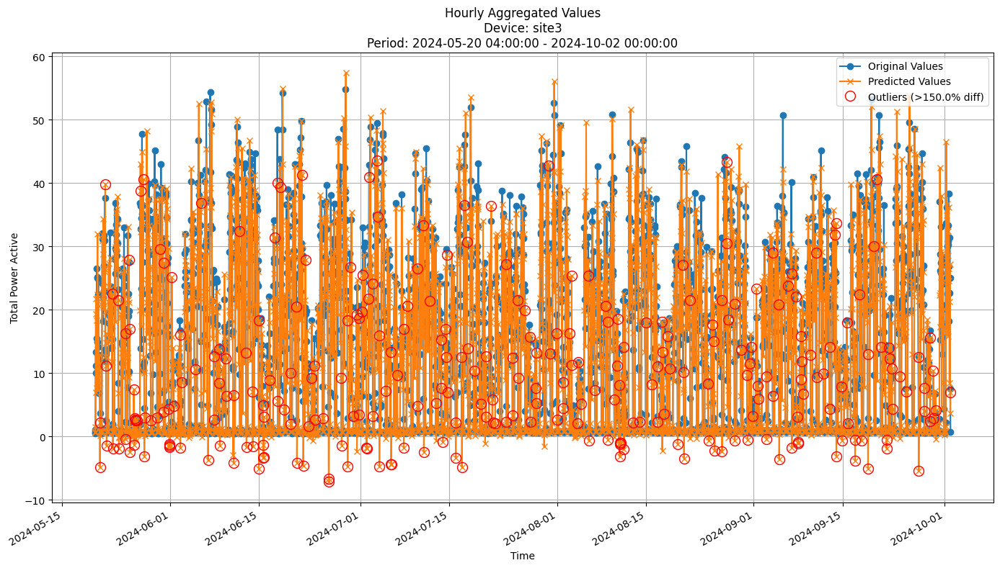


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.9630
MAE: 5.1950
MAPE: 65.0702%

Directional Metrics:
Directional Accuracy: 43.8195%
First-Diff Correlation: 0.0480

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


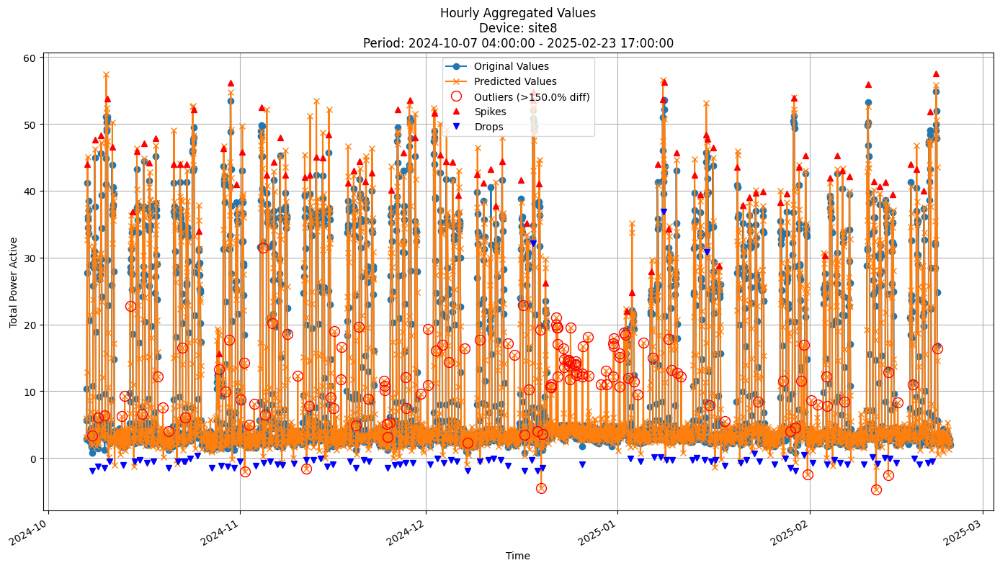


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.6455
MAE: 2.5257
MAPE: 36.8316%

Directional Metrics:
Directional Accuracy: 48.4478%
First-Diff Correlation: 0.3032

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0857
  Recall: 0.0947
  F1 Score: 0.0900
Drops:
  Precision: 0.0481
  Recall: 0.0526
  F1 Score: 0.0503

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.8842
  F1 Score: 0.8400
Drops:
  Precision: 0.2981
  Recall: 0.3263
  F1 Score: 0.3116


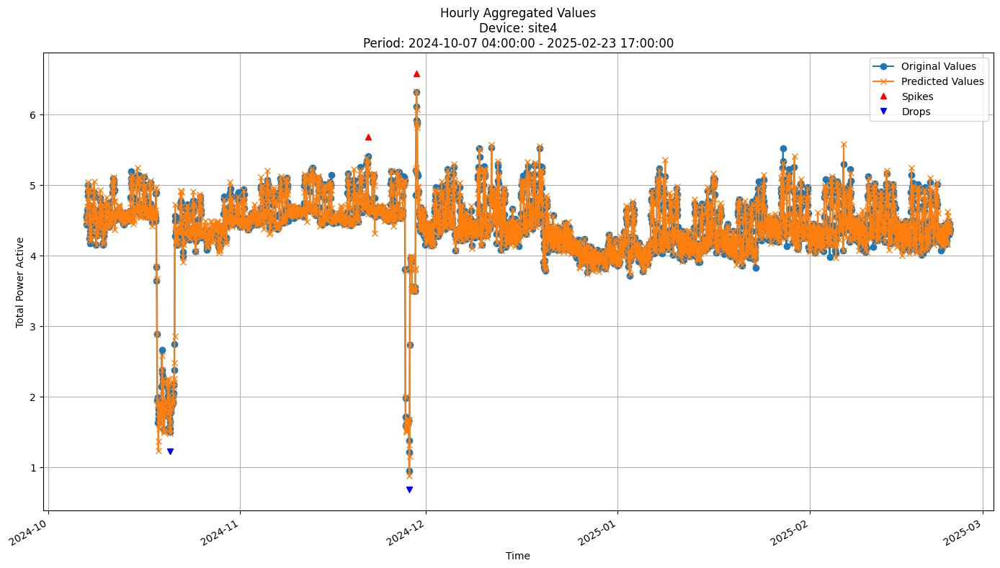


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1708
MAE: 0.1136
MAPE: 2.6753%

Directional Metrics:
Directional Accuracy: 40.8060%
First-Diff Correlation: -0.0909

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


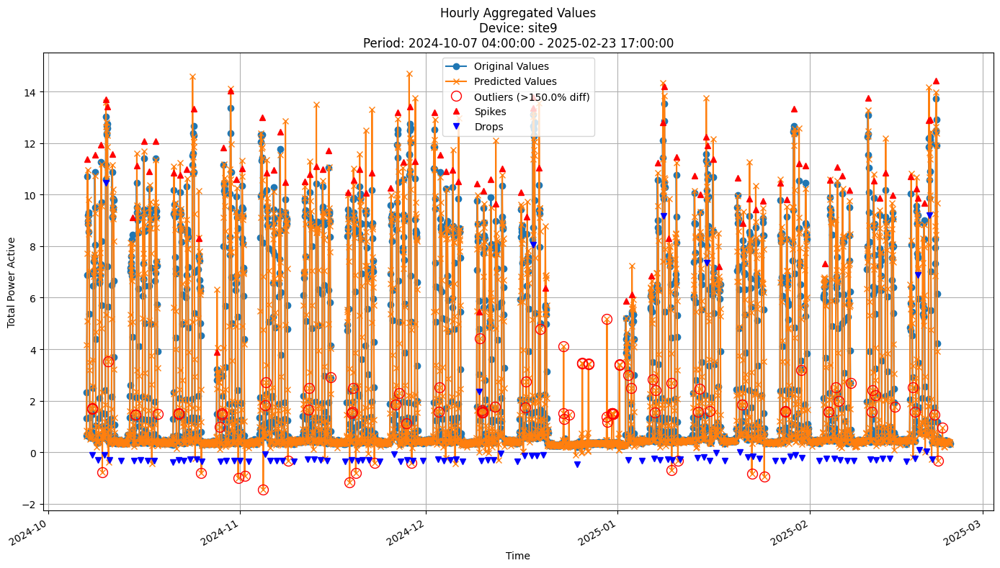


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9675
MAE: 0.4544
MAPE: 26.1997%

Directional Metrics:
Directional Accuracy: 48.9552%
First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.1111
  F1 Score: 0.1000
Drops:
  Precision: 0.0500
  Recall: 0.0612
  F1 Score: 0.0550

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7603
  Recall: 0.9293
  F1 Score: 0.8364
Drops:
  Precision: 0.2500
  Recall: 0.3061
  F1 Score: 0.2752


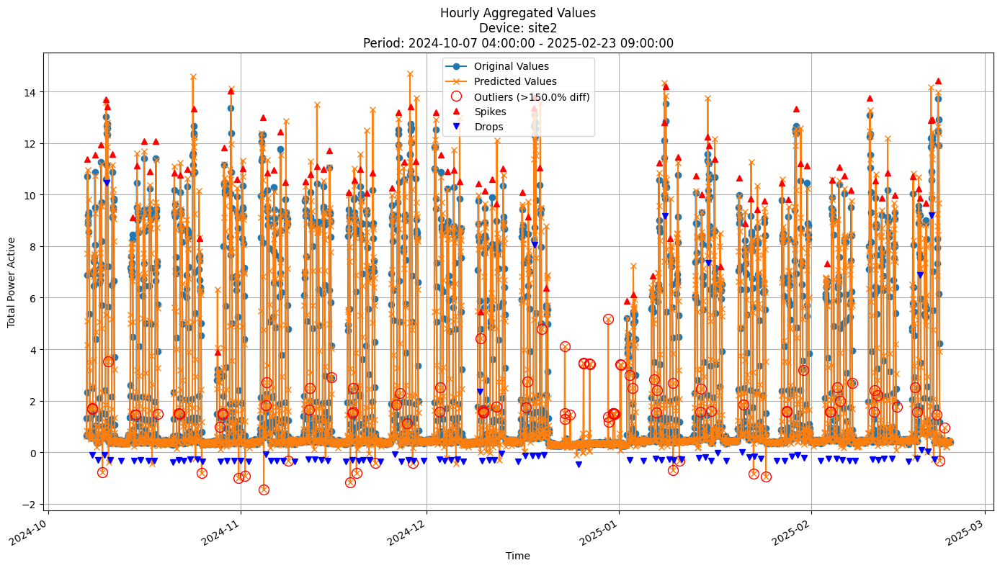


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9686
MAE: 0.4554
MAPE: 26.2398%

Directional Metrics:
Directional Accuracy: 48.9527%
First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.1111
  F1 Score: 0.1000
Drops:
  Precision: 0.0500
  Recall: 0.0612
  F1 Score: 0.0550

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7603
  Recall: 0.9293
  F1 Score: 0.8364
Drops:
  Precision: 0.2500
  Recall: 0.3061
  F1 Score: 0.2752


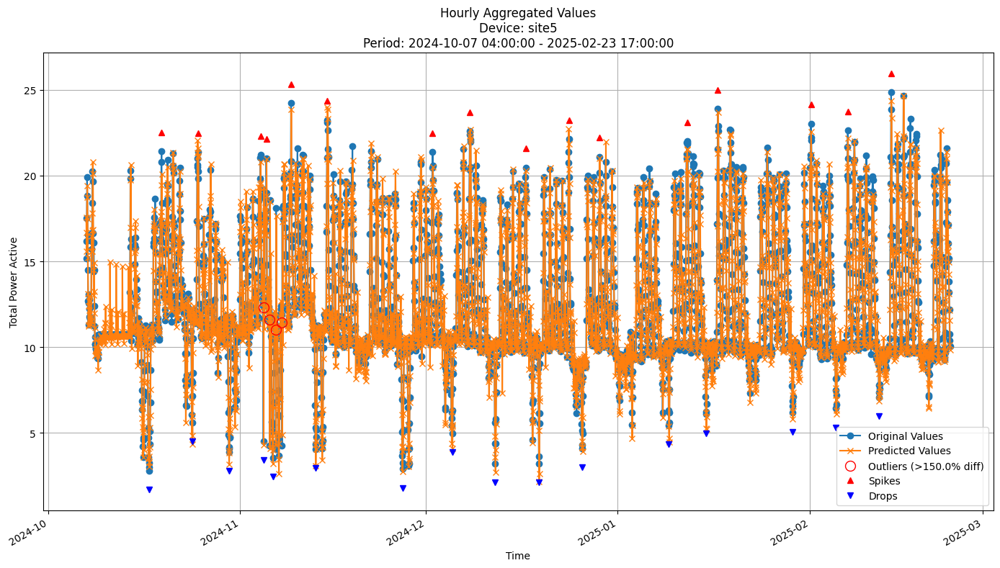


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2863
MAE: 0.7980
MAPE: 6.4813%

Directional Metrics:
Directional Accuracy: 58.3284%
First-Diff Correlation: 0.2348

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1667
  Recall: 0.1250
  F1 Score: 0.1429

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5833
  Recall: 0.4375
  F1 Score: 0.5000
Drops:
  Precision: 0.9167
  Recall: 0.6875
  F1 Score: 0.7857


In [29]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 20,
    'max_features': 0.8,
    'aggregation_method': 'mean',
    'grace_period': 24,
    'max_depth': 10,
    'delta': 0.05,  # split confidence
    'tau': 0.05,  # break ties
    'seed': 42
}

In [ ]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 11.410561 MB


 2023-02-27 04:00:00+01:00    0.757351
2023-02-27 05:00:00+01:00    0.829250
2023-02-27 06:00:00+01:00    1.004344
2023-02-27 07:00:00+01:00    0.891649
2023-02-27 08:00:00+01:00    1.043526
                               ...   
2023-03-26 23:00:00+02:00    0.149406
2023-03-27 00:00:00+02:00    0.158251
2023-03-27 01:00:00+02:00    0.185421
2023-03-27 02:00:00+02:00    0.207364
2023-03-27 03:00:00+02:00    0.252734
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.232818
2023-03-27 05:00:00+02:00    0.233143
2023-03-27 06:00:00+02:00    0.340916
2023-03-27 07:00:00+02:00    0.410136
2023-03-27 08:00:00+02:00    0.410408
                               ...   
2023-04-23 23:00:00+02:00    0.140014
2023-04-24 00:00:00+02:00    0.147477
2

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 12.270821 MB


 2023-02-27 04:00:00+01:00    0.766070
2023-02-27 05:00:00+01:00    0.836659
2023-02-27 06:00:00+01:00    0.996528
2023-02-27 07:00:00+01:00    0.888905
2023-02-27 08:00:00+01:00    1.037677
                               ...   
2023-04-23 23:00:00+02:00    0.140112
2023-04-24 00:00:00+02:00    0.146269
2023-04-24 01:00:00+02:00    0.145895
2023-04-24 02:00:00+02:00    0.151535
2023-04-24 03:00:00+02:00    0.146588
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.151088
2023-04-24 05:00:00+02:00    0.180236
2023-04-24 06:00:00+02:00    0.292631
2023-04-24 07:00:00+02:00    0.291239
2023-04-24 08:00:00+02:00    0.315849
                               ...   
2023-05-21 23:00:00+02:00    0.197634
2023-05-22 00:00:00+02:00    0.175657


Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 20.498756 MB


 2024-06-29 13:00:00+02:00    3.089981
2024-06-29 14:00:00+02:00    2.885965
2024-06-29 15:00:00+02:00    1.535251
2024-06-29 16:00:00+02:00    1.800716
2024-06-29 17:00:00+02:00    2.588415
                               ...   
2024-12-29 22:00:00+01:00    3.684793
2024-12-29 23:00:00+01:00    3.858907
2024-12-30 00:00:00+01:00    2.677245
2024-12-30 01:00:00+01:00    6.223700
2024-12-30 02:00:00+01:00    5.832310
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00    6.402556
2024-12-30 04:00:00+01:00    5.348911
2024-12-30 05:00:00+01:00    6.535187
2024-12-30 06:00:00+01:00    9.850058
2024-12-30 07:00:00+01:00    5.266576
                               ...   
2025-01-26 22:00:00+01:00    3.422234
2025-01-26 23:00:00+01:00    2.488878


Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 21.786575 MB


 2024-06-29 13:00:00+02:00    3.011875
2024-06-29 14:00:00+02:00    2.653733
2024-06-29 15:00:00+02:00    1.724319
2024-06-29 16:00:00+02:00    1.757097
2024-06-29 17:00:00+02:00    2.648125
                               ...   
2025-01-26 22:00:00+01:00    3.362531
2025-01-26 23:00:00+01:00    2.569223
2025-01-27 00:00:00+01:00    3.133815
2025-01-27 01:00:00+01:00    3.204691
2025-01-27 02:00:00+01:00    3.651000
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     4.907875
2025-01-27 04:00:00+01:00     4.581921
2025-01-27 05:00:00+01:00     4.990889
2025-01-27 06:00:00+01:00    14.524485
2025-01-27 07:00:00+01:00    40.380843
                               ...    
2025-02-23 13:00:00+01:00     1.668417
2025-02-23 14:00:00+01:00     2

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0570 ± 0.0052
	MAE: 0.0387 ± 0.0041
	MAPE: 15.0554% ± 1.4201%

	Directional Metrics:
		Directional Accuracy: 55.0868% ± 4.8964%
		First-Diff Correlation: 0.2171 ± 0.1090

	Immediate Detection (delta=0):
		Spike Precision: 0.1187 ± 0.0424
		Spike Recall: 0.1066 ± 0.0353
		Spike F1: 0.1118 ± 0.0374
		Drop Precision: 0.1146 ± 0.0143
		Drop Recall: 0.1030 ± 0.0233
		Drop F1: 0.1079 ± 0.0184

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8384 ± 0.0616
		Spike Recall: 0.7712 ± 0.0765
		Spike F1: 0.7992 ± 0.0426
		Drop Precision: 0.6126 ± 0.0474
		Drop Recall: 0.5463 ± 0.0891
		Drop F1: 0.5746 ± 0.0629
Daily Metrics:
	RMSE: 0.2109 ± 0.0498
	MAE: 0.1593 ± 0.0583
	MAPE: 2.5325% ± 1.2518%

	Directional Metrics:
		Directional Accuracy: 97.2854% ± 1.0795%
		First-Diff Correlation: 0.9958 ± 0.0012

	Immediate Detection (delta=0):
		Spik

#### Training plots

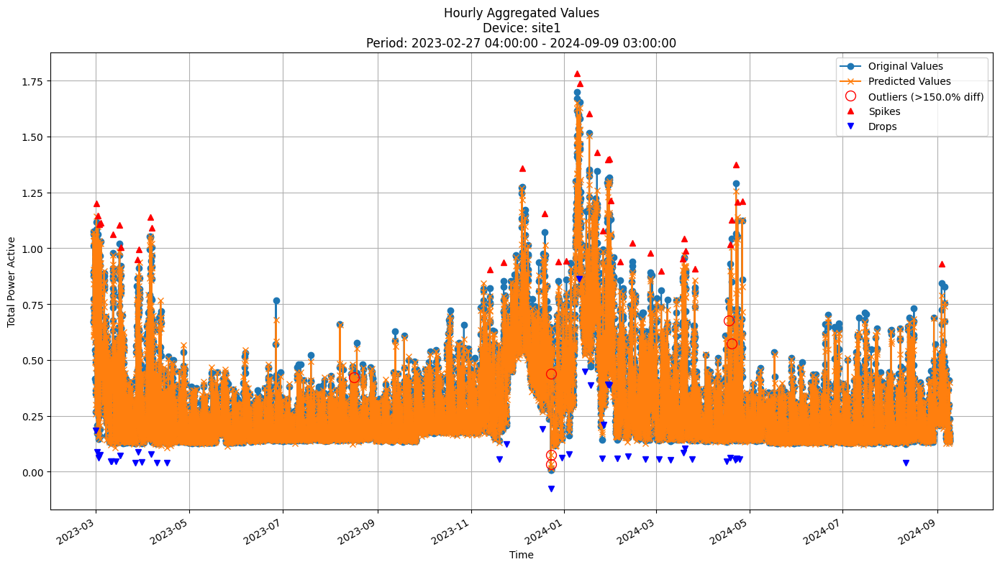


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0608
MAE: 0.0403
MAPE: 15.3625%

Directional Metrics:
Directional Accuracy: 50.1339%
First-Diff Correlation: 0.1205

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.0769
  F1 Score: 0.0833
Drops:
  Precision: 0.0606
  Recall: 0.0488
  F1 Score: 0.0541

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8788
  Recall: 0.7436
  F1 Score: 0.8056
Drops:
  Precision: 0.7576
  Recall: 0.6098
  F1 Score: 0.6757


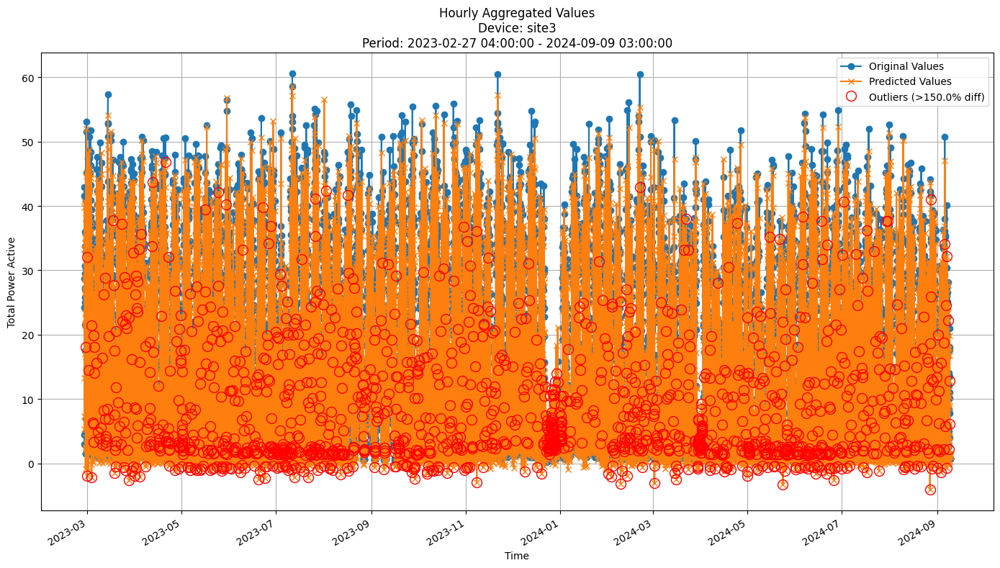


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.4520
MAE: 4.9970
MAPE: 73.9417%

Directional Metrics:
Directional Accuracy: 46.3090%
First-Diff Correlation: 0.0344

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


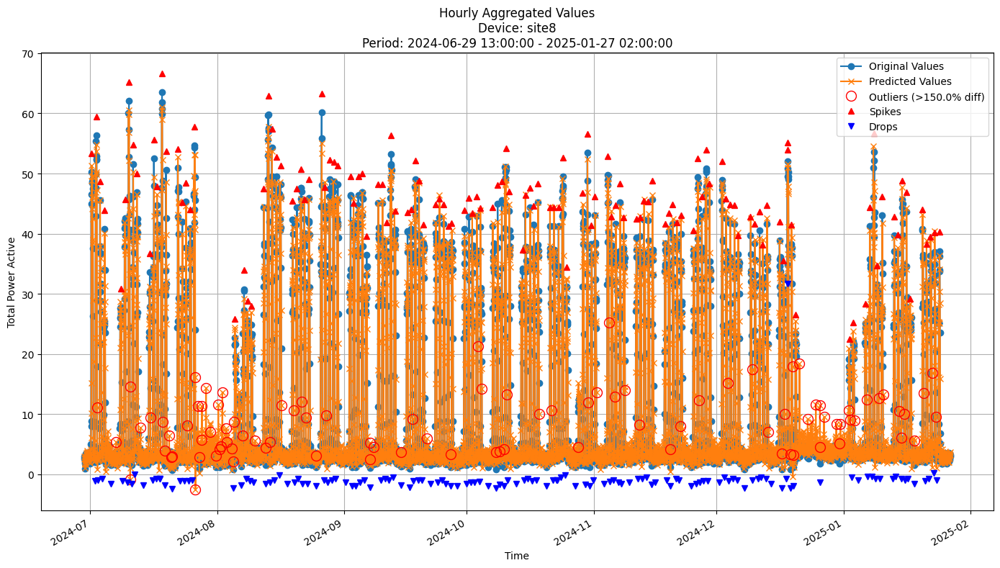


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.6942
MAE: 1.9920
MAPE: 29.4277%

Directional Metrics:
Directional Accuracy: 49.1532%
First-Diff Correlation: 0.5140

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0809
  Recall: 0.0815
  F1 Score: 0.0812
Drops:
  Precision: 0.0148
  Recall: 0.0147
  F1 Score: 0.0148

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8897
  Recall: 0.8963
  F1 Score: 0.8930
Drops:
  Precision: 0.4667
  Recall: 0.4632
  F1 Score: 0.4649


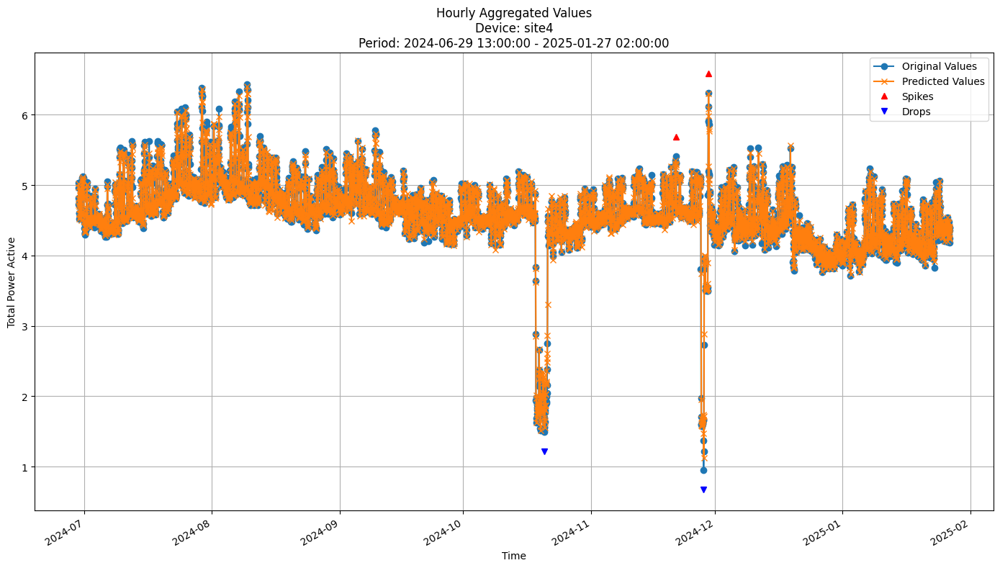


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1308
MAE: 0.0842
MAPE: 1.9102%

Directional Metrics:
Directional Accuracy: 47.5384%
First-Diff Correlation: 0.1045

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


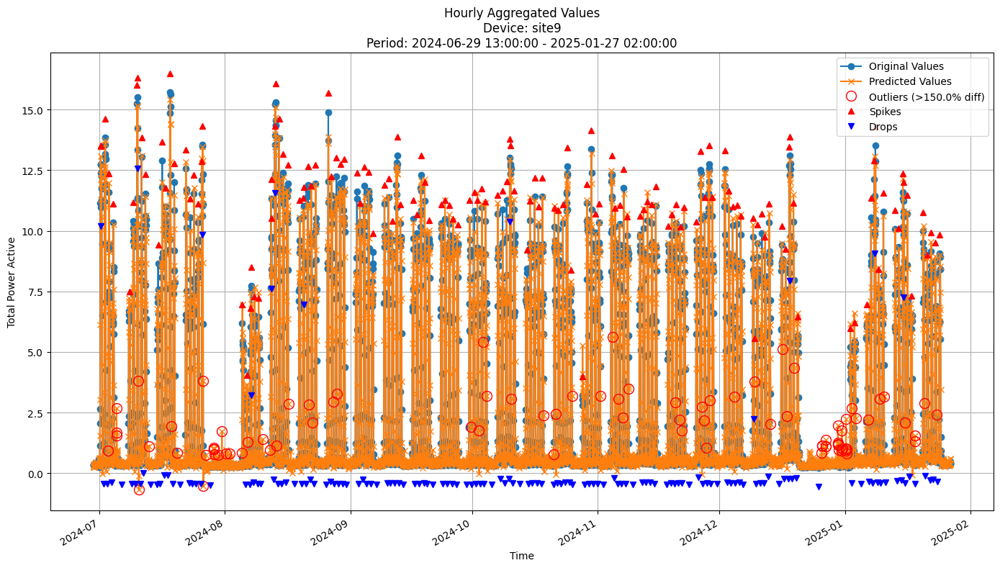


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8262
MAE: 0.3896
MAPE: 25.1662%

Directional Metrics:
Directional Accuracy: 52.6191%
First-Diff Correlation: 0.5733

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1049
  Recall: 0.1014
  F1 Score: 0.1031
Drops:
  Precision: 0.0423
  Recall: 0.0405
  F1 Score: 0.0414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9091
  Recall: 0.8784
  F1 Score: 0.8935
Drops:
  Precision: 0.2817
  Recall: 0.2703
  F1 Score: 0.2759


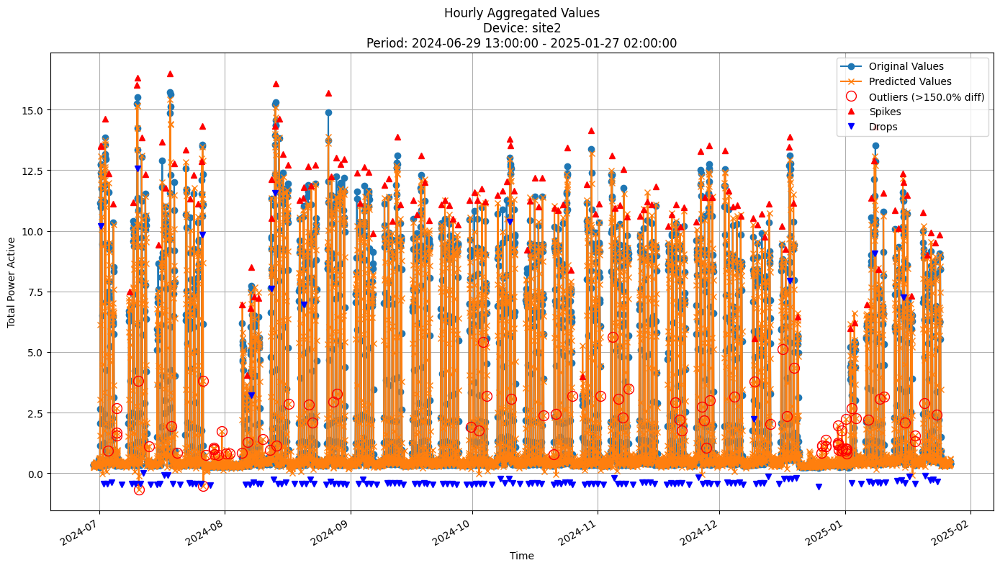


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8262
MAE: 0.3896
MAPE: 25.1662%

Directional Metrics:
Directional Accuracy: 52.6191%
First-Diff Correlation: 0.5733

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1049
  Recall: 0.1014
  F1 Score: 0.1031
Drops:
  Precision: 0.0423
  Recall: 0.0405
  F1 Score: 0.0414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9091
  Recall: 0.8784
  F1 Score: 0.8935
Drops:
  Precision: 0.2817
  Recall: 0.2703
  F1 Score: 0.2759


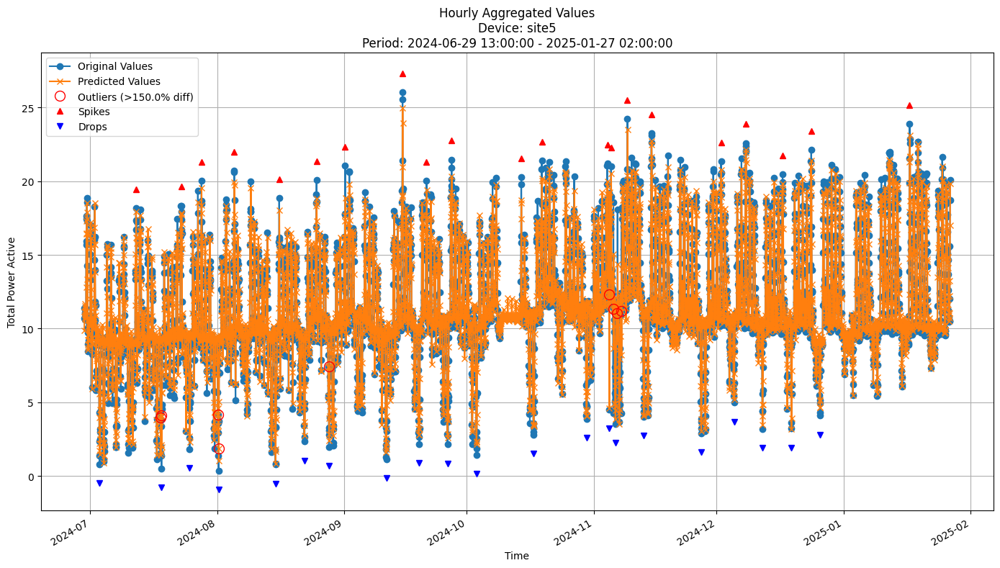


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1737
MAE: 0.7555
MAPE: 7.8350%

Directional Metrics:
Directional Accuracy: 60.0433%
First-Diff Correlation: 0.2773

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0800
  Recall: 0.0952
  F1 Score: 0.0870
Drops:
  Precision: 0.0800
  Recall: 0.0952
  F1 Score: 0.0870

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6800
  Recall: 0.8095
  F1 Score: 0.7391
Drops:
  Precision: 0.6800
  Recall: 0.8095
  F1 Score: 0.7391


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

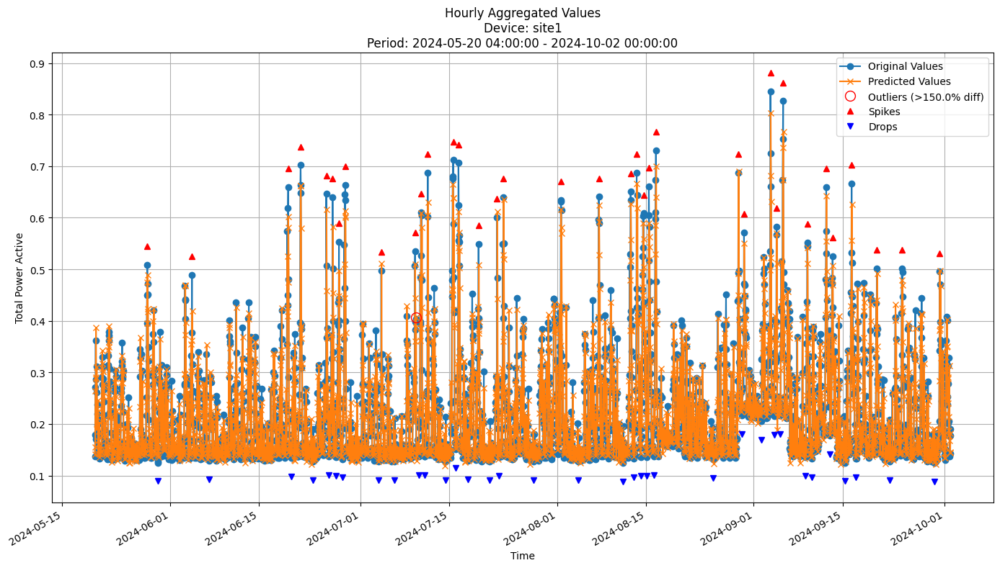


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0602
MAE: 0.0380
MAPE: 16.4432%

Directional Metrics:
Directional Accuracy: 46.4771%
First-Diff Correlation: 0.0372

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1250
  Recall: 0.0833
  F1 Score: 0.1000
Drops:
  Precision: 0.0435
  Recall: 0.0286
  F1 Score: 0.0345

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.6667
  F1 Score: 0.8000
Drops:
  Precision: 0.3043
  Recall: 0.2000
  F1 Score: 0.2414


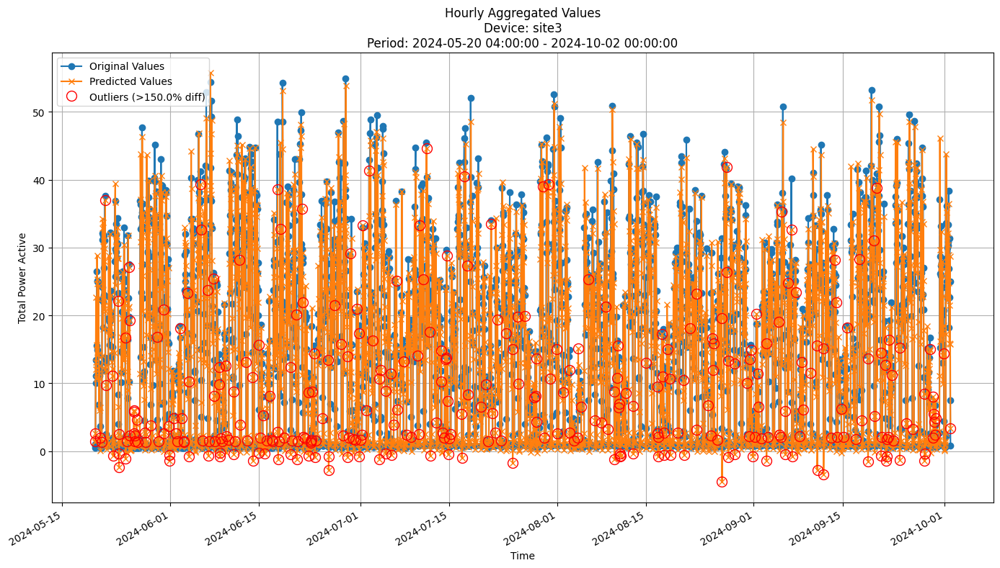


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.6550
MAE: 5.1078
MAPE: 72.5926%

Directional Metrics:
Directional Accuracy: 44.7157%
First-Diff Correlation: -0.0155

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


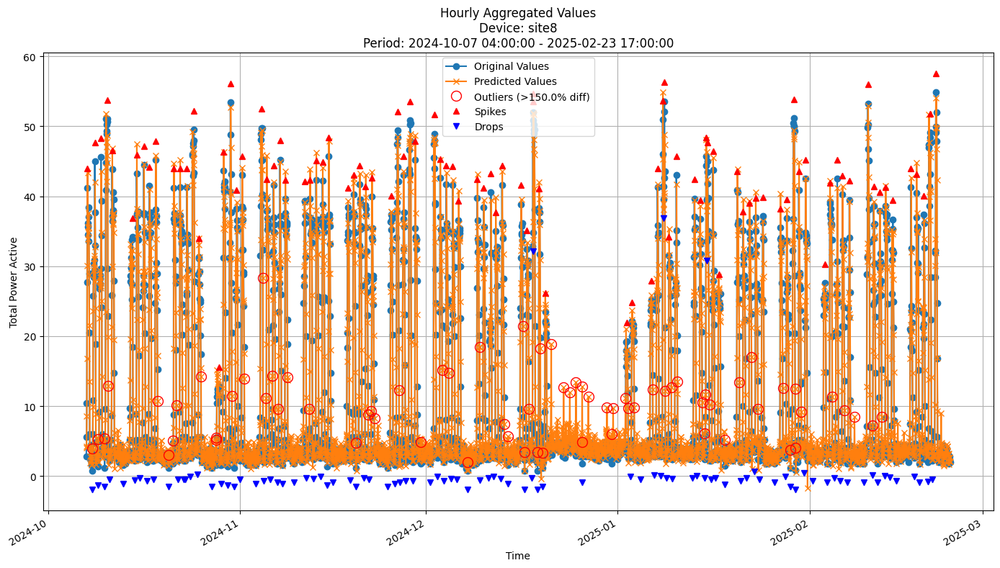


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.8785
MAE: 2.1114
MAPE: 30.8779%

Directional Metrics:
Directional Accuracy: 48.7463%
First-Diff Correlation: 0.4232

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0860
  Recall: 0.0842
  F1 Score: 0.0851
Drops:
  Precision: 0.0326
  Recall: 0.0316
  F1 Score: 0.0321

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9032
  Recall: 0.8842
  F1 Score: 0.8936
Drops:
  Precision: 0.4783
  Recall: 0.4632
  F1 Score: 0.4706


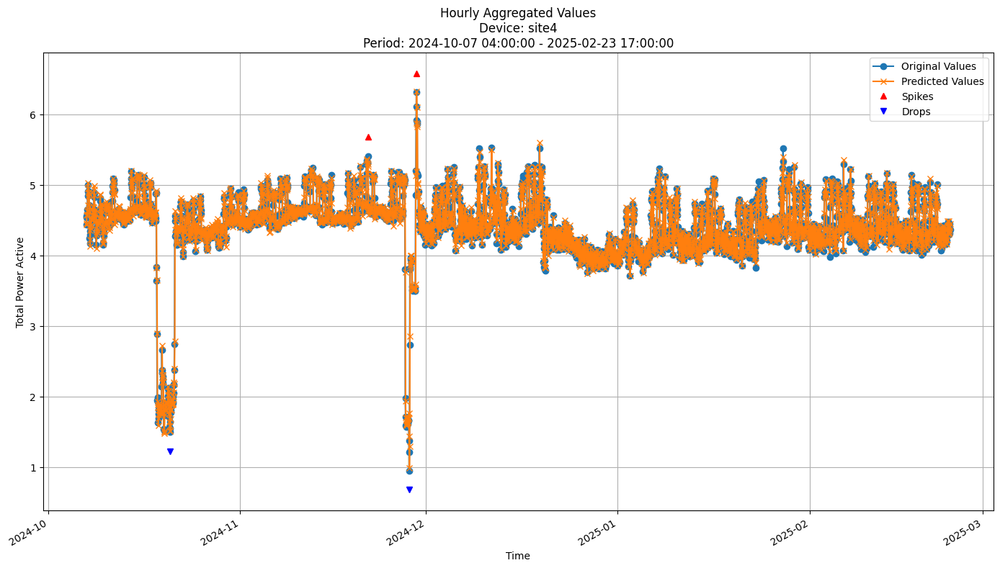


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1663
MAE: 0.1084
MAPE: 2.5368%

Directional Metrics:
Directional Accuracy: 40.5373%
First-Diff Correlation: -0.0976

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


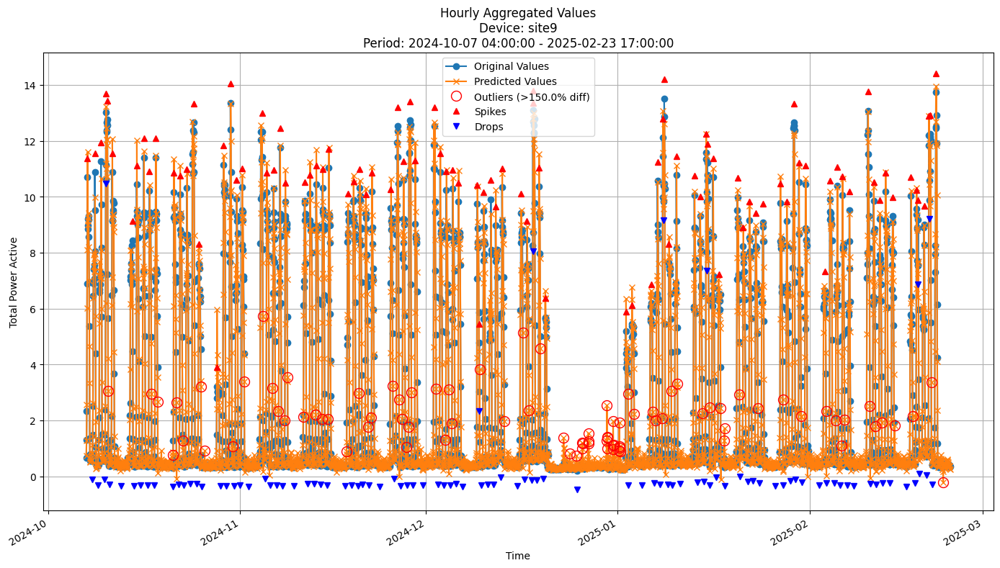


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8521
MAE: 0.4149
MAPE: 27.1929%

Directional Metrics:
Directional Accuracy: 52.2090%
First-Diff Correlation: 0.5075

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1053
  Recall: 0.1010
  F1 Score: 0.1031
Drops:
  Precision: 0.1277
  Recall: 0.1224
  F1 Score: 0.1250

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9263
  Recall: 0.8889
  F1 Score: 0.9072
Drops:
  Precision: 0.3617
  Recall: 0.3469
  F1 Score: 0.3542


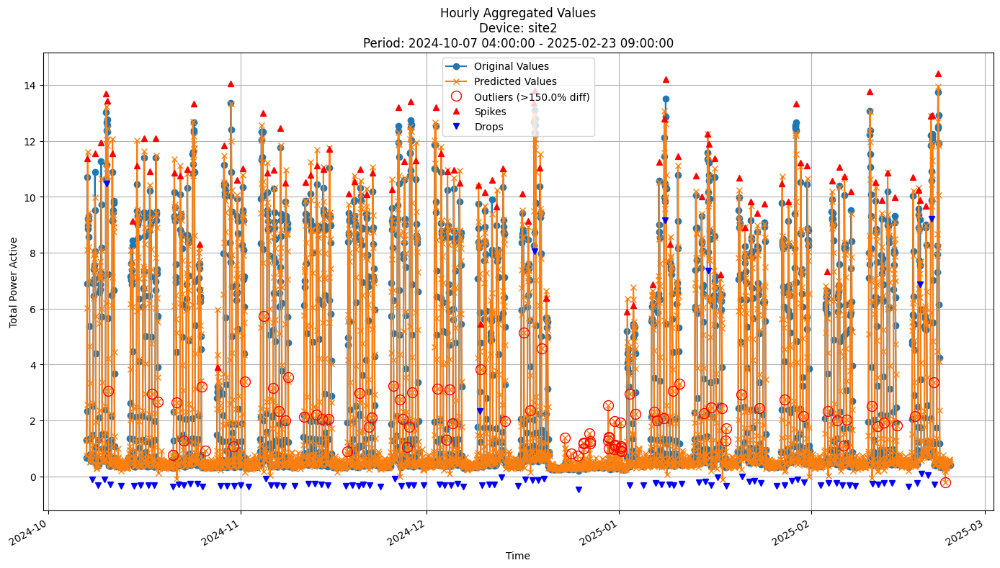


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8531
MAE: 0.4158
MAPE: 27.2283%

Directional Metrics:
Directional Accuracy: 52.2741%
First-Diff Correlation: 0.5075

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1053
  Recall: 0.1010
  F1 Score: 0.1031
Drops:
  Precision: 0.1277
  Recall: 0.1224
  F1 Score: 0.1250

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9263
  Recall: 0.8889
  F1 Score: 0.9072
Drops:
  Precision: 0.3617
  Recall: 0.3469
  F1 Score: 0.3542


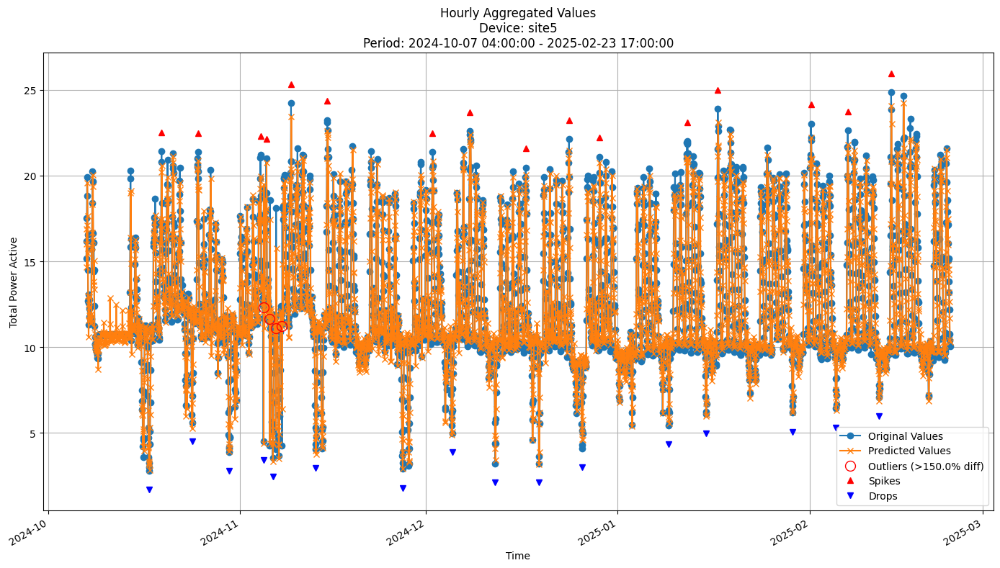


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2292
MAE: 0.7608
MAPE: 6.1188%

Directional Metrics:
Directional Accuracy: 60.4478%
First-Diff Correlation: 0.2507

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0625
  Recall: 0.0625
  F1 Score: 0.0625
Drops:
  Precision: 0.1765
  Recall: 0.1875
  F1 Score: 0.1818

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8125
  Recall: 0.8125
  F1 Score: 0.8125
Drops:
  Precision: 0.7647
  Recall: 0.8125
  F1 Score: 0.7879


In [34]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {
        'depth': 50, 
        'grace_period': 10, 
        'grace_period_depth': -1, 
        'split_confidence': 0.5, 
        'max_feature': 1.0, 
        'tie_threshold': 0.05, 
        'hist' : [
                HistogramContainer(
                bin_type = get_histogram_type('adaptive'),
                max_bins = 32
                ),
        ],
        'split_criterion': [VarianceReductionRelative],
}

In [ ]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 1.321342 MB


 2023-02-27 04:00:00+01:00    0.767500
2023-02-27 05:00:00+01:00    0.916187
2023-02-27 06:00:00+01:00    0.993031
2023-02-27 07:00:00+01:00    0.872306
2023-02-27 08:00:00+01:00    1.039536
                               ...   
2023-03-26 23:00:00+02:00    0.151125
2023-03-27 00:00:00+02:00    0.139375
2023-03-27 01:00:00+02:00    0.164125
2023-03-27 02:00:00+02:00    0.207594
2023-03-27 03:00:00+02:00    0.252594
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.230344
2023-03-27 05:00:00+02:00    0.216675
2023-03-27 06:00:00+02:00    0.398438
2023-03-27 07:00:00+02:00    0.420208
2023-03-27 08:00:00+02:00    0.423187
                               ...   
2023-04-23 23:00:00+02:00    0.102688
2023-04-24 00:00:00+02:00    0.132775
20

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 2.059418 MB


 2023-02-27 04:00:00+01:00    0.772568
2023-02-27 05:00:00+01:00    0.925045
2023-02-27 06:00:00+01:00    0.973929
2023-02-27 07:00:00+01:00    0.933938
2023-02-27 08:00:00+01:00    0.921375
                               ...   
2023-04-23 23:00:00+02:00    0.106583
2023-04-24 00:00:00+02:00    0.138500
2023-04-24 01:00:00+02:00    0.138500
2023-04-24 02:00:00+02:00    0.142250
2023-04-24 03:00:00+02:00    0.136750
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.140500
2023-04-24 05:00:00+02:00    0.178000
2023-04-24 06:00:00+02:00    0.302325
2023-04-24 07:00:00+02:00    0.267500
2023-04-24 08:00:00+02:00    0.288000
                               ...   
2023-05-21 23:00:00+02:00    0.181455
2023-05-22 00:00:00+02:00    0.154750
2

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 5.057266 MB


 2024-06-29 13:00:00+02:00    2.490959
2024-06-29 14:00:00+02:00    2.471912
2024-06-29 15:00:00+02:00    3.233284
2024-06-29 16:00:00+02:00    1.331105
2024-06-29 17:00:00+02:00    2.750247
                               ...   
2024-12-29 22:00:00+01:00    3.645133
2024-12-29 23:00:00+01:00    3.255241
2024-12-30 00:00:00+01:00    3.218402
2024-12-30 01:00:00+01:00    4.681844
2024-12-30 02:00:00+01:00    4.207811
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00     3.176867
2024-12-30 04:00:00+01:00     5.294591
2024-12-30 05:00:00+01:00     4.190845
2024-12-30 06:00:00+01:00    17.557487
2024-12-30 07:00:00+01:00     3.152863
                               ...    
2025-01-26 22:00:00+01:00     3.392837
2025-01-26 23:00:00+01:00     2.

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 5.773323 MB


 2024-06-29 13:00:00+02:00    3.310165
2024-06-29 14:00:00+02:00    2.591900
2024-06-29 15:00:00+02:00    3.233284
2024-06-29 16:00:00+02:00    1.735669
2024-06-29 17:00:00+02:00    2.207335
                               ...   
2025-01-26 22:00:00+01:00    3.198853
2025-01-26 23:00:00+01:00    2.675276
2025-01-27 00:00:00+01:00    3.261463
2025-01-27 01:00:00+01:00    2.605524
2025-01-27 02:00:00+01:00    3.713173
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     2.206582
2025-01-27 04:00:00+01:00     3.696941
2025-01-27 05:00:00+01:00     6.485395
2025-01-27 06:00:00+01:00    17.508205
2025-01-27 07:00:00+01:00    34.455256
                               ...    
2025-02-23 13:00:00+01:00     0.914392
2025-02-23 14:00:00+01:00     2.

#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0727 ± 0.0085
	MAE: 0.0486 ± 0.0056
	MAPE: 18.4508% ± 0.8248%

	Directional Metrics:
		Directional Accuracy: 52.9535% ± 1.7347%
		First-Diff Correlation: 0.2092 ± 0.0694

	Immediate Detection (delta=0):
		Spike Precision: 0.1111 ± 0.0345
		Spike Recall: 0.1224 ± 0.0382
		Spike F1: 0.1159 ± 0.0352
		Drop Precision: 0.0875 ± 0.0291
		Drop Recall: 0.0944 ± 0.0353
		Drop F1: 0.0903 ± 0.0311

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6713 ± 0.0849
		Spike Recall: 0.7420 ± 0.0701
		Spike F1: 0.7009 ± 0.0585
		Drop Precision: 0.3913 ± 0.0641
		Drop Recall: 0.4190 ± 0.0698
		Drop F1: 0.4024 ± 0.0598
Daily Metrics:
	RMSE: 0.4707 ± 0.1444
	MAE: 0.3132 ± 0.0938
	MAPE: 3.9431% ± 0.5174%

	Directional Metrics:
		Directional Accuracy: 92.3270% ± 1.8423%
		First-Diff Correlation: 0.9837 ± 0.0054

	Immediate Detection (delta=0):
		Spik

```

Train period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.4286 ± 0.4411
	MAE: 0.4649 ± 0.0949
	MAPE: 154.1858% ± 12.7512%

	Directional Metrics:
		Directional Accuracy: 63.7949% ± 1.4450%
		First-Diff Correlation: 0.0459 ± 0.0963

	Immediate Detection (delta=0):
		Spike Precision: 0.0945 ± 0.0637
		Spike Recall: 0.1248 ± 0.0342
		Spike F1: 0.1023 ± 0.0492
		Drop Precision: 0.0928 ± 0.0243
		Drop Recall: 0.1472 ± 0.0543
		Drop F1: 0.1082 ± 0.0211

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2370 ± 0.1074
		Spike Recall: 0.3507 ± 0.0532
		Spike F1: 0.2679 ± 0.0703
		Drop Precision: 0.1830 ± 0.0423
		Drop Recall: 0.3002 ± 0.1367
		Drop F1: 0.2161 ± 0.0506
Daily Metrics:
	RMSE: 20.4400 ± 7.4693
	MAE: 10.7240 ± 2.2030
	MAPE: 140.4382% ± 15.5932%

	Directional Metrics:
		Directional Accuracy: 69.0647% ± 1.8056%
		First-Diff Correlation: 0.5645 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.3597 ± 0.1428
		Spike Recall: 0.6779 ± 0.2191
		Spike F1: 0.4554 ± 0.1511
		Drop Precision: 0.2963 ± 0.1443
		Drop Recall: 0.5238 ± 0.1866
		Drop F1: 0.3630 ± 0.1328

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4043 ± 0.1354
		Spike Recall: 0.7713 ± 0.2297
		Spike F1: 0.5155 ± 0.1490
		Drop Precision: 0.4329 ± 0.1644
		Drop Recall: 0.7762 ± 0.2140
		Drop F1: 0.5371 ± 0.1586
Weekly Metrics:
	RMSE: 113.7435 ± 37.9546
	MAE: 72.5625 ± 15.5612
	MAPE: 142.3324% ± 16.4446%
28_days Metrics:
	RMSE: 360.8309 ± 118.6854
	MAE: 263.8197 ± 64.2663
	MAPE: 149.4141% ± 21.0361%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.5669 ± 1.4555
	MAE: 8.0340 ± 1.0846
	MAPE: 111.1159% ± 6.0388%

	Directional Metrics:
		Directional Accuracy: 62.6447% ± 3.8172%
		First-Diff Correlation: 0.5265 ± 0.0533

	Immediate Detection (delta=0):
		Spike Precision: 0.0630 ± 0.0472
		Spike Recall: 0.0105 ± 0.0087
		Spike F1: 0.0177 ± 0.0140
		Drop Precision: 0.1906 ± 0.1411
		Drop Recall: 0.0133 ± 0.0121
		Drop F1: 0.0218 ± 0.0153

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1596 ± 0.1153
		Spike Recall: 0.0262 ± 0.0204
		Spike F1: 0.0442 ± 0.0332
		Drop Precision: 0.4194 ± 0.2593
		Drop Recall: 0.0504 ± 0.0704
		Drop F1: 0.0571 ± 0.0369
Daily Metrics:
	RMSE: 172.6580 ± 26.0863
	MAE: 146.3021 ± 23.9399
	MAPE: 41.7586% ± 4.0344%

	Directional Metrics:
		Directional Accuracy: 81.5129% ± 2.2913%
		First-Diff Correlation: 0.8680 ± 0.0527

	Immediate Detection (delta=0):
		Spike Precision: 0.3788 ± 0.1361
		Spike Recall: 0.5379 ± 0.1611
		Spike F1: 0.4389 ± 0.1422
		Drop Precision: 0.5538 ± 0.1801
		Drop Recall: 0.7194 ± 0.1023
		Drop F1: 0.6031 ± 0.1125

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5900 ± 0.2319
		Spike Recall: 0.8119 ± 0.2027
		Spike F1: 0.6742 ± 0.2186
		Drop Precision: 0.6804 ± 0.1865
		Drop Recall: 0.8966 ± 0.1323
		Drop F1: 0.7489 ± 0.1365
Weekly Metrics:
	RMSE: 971.9025 ± 152.7558
	MAE: 902.1004 ± 139.8825
	MAPE: 33.8709% ± 3.7386%
28_days Metrics:
	RMSE: 3496.3959 ± 412.0541
	MAE: 3151.8350 ± 226.5504
	MAPE: 31.4738% ± 3.8223%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.2047 ± 0.1088
	MAE: 5.8004 ± 0.0861
	MAPE: 122.7946% ± 6.2983%

	Directional Metrics:
		Directional Accuracy: 51.1547% ± 0.5179%
		First-Diff Correlation: 0.0186 ± 0.0173

	Immediate Detection (delta=0):
		Spike Precision: 0.0430 ± 0.0220
		Spike Recall: 0.0769 ± 0.0120
		Spike F1: 0.0537 ± 0.0183
		Drop Precision: 0.0219 ± 0.0096
		Drop Recall: 0.0463 ± 0.0214
		Drop F1: 0.0296 ± 0.0130

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2057 ± 0.0498
		Spike Recall: 0.3891 ± 0.0493
		Spike F1: 0.2640 ± 0.0395
		Drop Precision: 0.0536 ± 0.0238
		Drop Recall: 0.0945 ± 0.0143
		Drop F1: 0.0664 ± 0.0186
Daily Metrics:
	RMSE: 122.3920 ± 3.3864
	MAE: 113.0393 ± 4.2904
	MAPE: 101.4446% ± 6.2264%

	Directional Metrics:
		Directional Accuracy: 64.9284% ± 1.3102%
		First-Diff Correlation: 0.4384 ± 0.0827

	Immediate Detection (delta=0):
		Spike Precision: 0.0151 ± 0.0196
		Spike Recall: 0.1250 ± 0.1614
		Spike F1: 0.0270 ± 0.0350
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0221 ± 0.0227
		Spike Recall: 0.1875 ± 0.1943
		Spike F1: 0.0395 ± 0.0405
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 744.0829 ± 66.3055
	MAE: 688.2735 ± 105.1532
	MAPE: 93.2305% ± 10.0279%
28_days Metrics:
	RMSE: 2808.1318 ± 427.2894
	MAE: 2750.4929 ± 422.6597
	MAPE: 101.6742% ± 6.1800%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.1001 ± 0.1762
	MAE: 5.7555 ± 0.1221
	MAPE: 66.2675% ± 8.1382%

	Directional Metrics:
		Directional Accuracy: 49.6081% ± 1.7725%
		First-Diff Correlation: -0.0996 ± 0.0138

	Immediate Detection (delta=0):
		Spike Precision: 0.0350 ± 0.0220
		Spike Recall: 0.0310 ± 0.0204
		Spike F1: 0.0329 ± 0.0211
		Drop Precision: 0.0128 ± 0.0095
		Drop Recall: 0.0108 ± 0.0076
		Drop F1: 0.0117 ± 0.0084

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0821 ± 0.0119
		Spike Recall: 0.0723 ± 0.0103
		Spike F1: 0.0769 ± 0.0109
		Drop Precision: 0.0287 ± 0.0171
		Drop Recall: 0.0246 ± 0.0142
		Drop F1: 0.0265 ± 0.0155
Daily Metrics:
	RMSE: 72.5536 ± 6.0504
	MAE: 63.1687 ± 4.2827
	MAPE: 27.2779% ± 1.6561%

	Directional Metrics:
		Directional Accuracy: 55.3416% ± 4.8641%
		First-Diff Correlation: 0.3503 ± 0.1151

	Immediate Detection (delta=0):
		Spike Precision: 0.0208 ± 0.0551
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0250 ± 0.0661
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3750 ± 0.3975
		Spike Recall: 0.0878 ± 0.0838
		Spike F1: 0.1216 ± 0.1029
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 167.7174 ± 47.6658
	MAE: 145.0577 ± 39.8770
	MAPE: 15.7286% ± 6.2873%
28_days Metrics:
	RMSE: 567.2156 ± 260.0607
	MAE: 496.8963 ± 223.2519
	MAPE: 7.9982% ± 2.5192%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 12.6180 ± 0.4301
	MAE: 9.3018 ± 0.2926
	MAPE: 170.1830% ± 4.8446%

	Directional Metrics:
		Directional Accuracy: 55.8814% ± 0.4535%
		First-Diff Correlation: 0.2770 ± 0.0194

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0675 ± 0.0323
		Drop Recall: 0.0441 ± 0.0232
		Drop F1: 0.0532 ± 0.0269

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.3221 ± 0.0573
		Drop Recall: 0.1984 ± 0.0158
		Drop F1: 0.2443 ± 0.0233
Daily Metrics:
	RMSE: 121.2843 ± 7.3768
	MAE: 107.5501 ± 5.9390
	MAPE: 83.3115% ± 9.1902%

	Directional Metrics:
		Directional Accuracy: 70.3931% ± 4.6669%
		First-Diff Correlation: 0.7882 ± 0.0525

	Immediate Detection (delta=0):
		Spike Precision: 0.0601 ± 0.0559
		Spike Recall: 0.1874 ± 0.3129
		Spike F1: 0.0764 ± 0.0691
		Drop Precision: 0.2129 ± 0.1830
		Drop Recall: 0.2998 ± 0.2383
		Drop F1: 0.2475 ± 0.2041

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2720 ± 0.1944
		Spike Recall: 0.4892 ± 0.3140
		Spike F1: 0.3243 ± 0.2143
		Drop Precision: 0.4358 ± 0.3483
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.5107 ± 0.3995
Weekly Metrics:
	RMSE: 367.8093 ± 70.2237
	MAE: 284.2988 ± 56.1231
	MAPE: 40.3974% ± 14.2109%
28_days Metrics:
	RMSE: 820.4173 ± 289.0154
	MAE: 742.9542 ± 275.4982
	MAPE: 14.3376% ± 12.4256%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7836 ± 0.1403
	MAE: 2.8282 ± 0.1197
	MAPE: 265.3842% ± 9.8812%

	Directional Metrics:
		Directional Accuracy: 56.1699% ± 0.9240%
		First-Diff Correlation: 0.2290 ± 0.0405

	Immediate Detection (delta=0):
		Spike Precision: 0.1096 ± 0.0110
		Spike Recall: 0.2695 ± 0.0391
		Spike F1: 0.1557 ± 0.0174
		Drop Precision: 0.0456 ± 0.0099
		Drop Recall: 0.1107 ± 0.0224
		Drop F1: 0.0646 ± 0.0137

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2966 ± 0.0195
		Spike Recall: 0.7280 ± 0.0769
		Spike F1: 0.4212 ± 0.0316
		Drop Precision: 0.1371 ± 0.0128
		Drop Recall: 0.3335 ± 0.0337
		Drop F1: 0.1942 ± 0.0180
Daily Metrics:
	RMSE: 75.9224 ± 2.2358
	MAE: 58.7399 ± 3.8585
	MAPE: 89.9029% ± 3.5175%

	Directional Metrics:
		Directional Accuracy: 71.6727% ± 2.3395%
		First-Diff Correlation: 0.8671 ± 0.0193

	Immediate Detection (delta=0):
		Spike Precision: 0.0789 ± 0.0587
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.0971 ± 0.0869
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3344 ± 0.2253
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3717 ± 0.2311
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 406.6172 ± 39.8134
	MAE: 358.5418 ± 62.1463
	MAPE: 89.8596% ± 5.4210%
28_days Metrics:
	RMSE: 1482.0490 ± 251.4957
	MAE: 1434.1671 ± 248.5852
	MAPE: 100.6348% ± 11.5976%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7677 ± 0.1537
	MAE: 2.8198 ± 0.1269
	MAPE: 264.2847% ± 10.9065%

	Directional Metrics:
		Directional Accuracy: 56.2055% ± 0.9262%
		First-Diff Correlation: 0.2297 ± 0.0402

	Immediate Detection (delta=0):
		Spike Precision: 0.1127 ± 0.0120
		Spike Recall: 0.2768 ± 0.0375
		Spike F1: 0.1601 ± 0.0180
		Drop Precision: 0.0461 ± 0.0103
		Drop Recall: 0.1117 ± 0.0227
		Drop F1: 0.0652 ± 0.0141

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2999 ± 0.0175
		Spike Recall: 0.7354 ± 0.0651
		Spike F1: 0.4257 ± 0.0269
		Drop Precision: 0.1375 ± 0.0142
		Drop Recall: 0.3344 ± 0.0349
		Drop F1: 0.1948 ± 0.0195
Daily Metrics:
	RMSE: 75.6948 ± 2.4162
	MAE: 58.5538 ± 4.0795
	MAPE: 89.5460% ± 3.8834%

	Directional Metrics:
		Directional Accuracy: 72.4540% ± 3.8659%
		First-Diff Correlation: 0.8664 ± 0.0205

	Immediate Detection (delta=0):
		Spike Precision: 0.0830 ± 0.0655
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.1030 ± 0.1002
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3385 ± 0.2225
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3777 ± 0.2294
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 405.4382 ± 41.4482
	MAE: 357.6252 ± 63.3554
	MAPE: 89.4626% ± 6.0151%
28_days Metrics:
	RMSE: 1478.1633 ± 256.4983
	MAE: 1430.5009 ± 253.4215
	MAPE: 100.3042% ± 11.5080%
==================================================

\Valid period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.9517 ± 1.3326
	MAE: 0.4789 ± 0.5493
	MAPE: 160.8027% ± 43.0824%

	Directional Metrics:
		Directional Accuracy: 59.4841% ± 3.0337%
		First-Diff Correlation: 0.1607 ± 0.1725

	Immediate Detection (delta=0):
		Spike Precision: 0.1808 ± 0.1957
		Spike Recall: 0.1208 ± 0.0885
		Spike F1: 0.1298 ± 0.1186
		Drop Precision: 0.0945 ± 0.0706
		Drop Recall: 0.0973 ± 0.0820
		Drop F1: 0.0828 ± 0.0591

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3351 ± 0.2361
		Spike Recall: 0.2752 ± 0.1159
		Spike F1: 0.2588 ± 0.1325
		Drop Precision: 0.1761 ± 0.1247
		Drop Recall: 0.2038 ± 0.1785
		Drop F1: 0.1574 ± 0.1118
Daily Metrics:
	RMSE: 14.5838 ± 20.9681
	MAE: 10.6832 ± 12.1654
	MAPE: 143.0981% ± 40.2923%

	Directional Metrics:
		Directional Accuracy: 67.8649% ± 7.5689%
		First-Diff Correlation: 0.5882 ± 0.1056

	Immediate Detection (delta=0):
		Spike Precision: 0.2475 ± 0.2703
		Spike Recall: 0.4333 ± 0.4453
		Spike F1: 0.3010 ± 0.3107
		Drop Precision: 0.2375 ± 0.3701
		Drop Recall: 0.2917 ± 0.4278
		Drop F1: 0.2433 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4058 ± 0.3076
		Spike Recall: 0.6417 ± 0.4258
		Spike F1: 0.4679 ± 0.3155
		Drop Precision: 0.3125 ± 0.3978
		Drop Recall: 0.3917 ± 0.4633
		Drop F1: 0.3267 ± 0.3943
Weekly Metrics:
	RMSE: 78.4506 ± 101.4114
	MAE: 61.9615 ± 70.3464
	MAPE: 142.7509% ± 41.8130%
28_days Metrics:
	RMSE: 219.1738 ± 248.5095
	MAE: 157.4884 ± 175.2153
	MAPE: 148.2634% ± 48.2707%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 10.9856 ± 1.6665
	MAE: 7.5816 ± 1.2908
	MAPE: 123.2313% ± 29.9137%

	Directional Metrics:
		Directional Accuracy: 58.0760% ± 3.3480%
		First-Diff Correlation: 0.4170 ± 0.0758

	Immediate Detection (delta=0):
		Spike Precision: 0.0217 ± 0.0669
		Spike Recall: 0.0058 ± 0.0214
		Spike F1: 0.0088 ± 0.0316
		Drop Precision: 0.1696 ± 0.3068
		Drop Recall: 0.0339 ± 0.0653
		Drop F1: 0.0464 ± 0.0842

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0476 ± 0.1023
		Spike Recall: 0.0284 ± 0.0531
		Spike F1: 0.0279 ± 0.0534
		Drop Precision: 0.2625 ± 0.3603
		Drop Recall: 0.0738 ± 0.1239
		Drop F1: 0.0955 ± 0.1512
Daily Metrics:
	RMSE: 153.2790 ± 37.8610
	MAE: 126.7289 ± 33.1132
	MAPE: 45.8233% ± 17.1199%

	Directional Metrics:
		Directional Accuracy: 76.1568% ± 8.3840%
		First-Diff Correlation: 0.8191 ± 0.0897

	Immediate Detection (delta=0):
		Spike Precision: 0.2167 ± 0.2986
		Spike Recall: 0.2667 ± 0.3704
		Spike F1: 0.2333 ± 0.3187
		Drop Precision: 0.4000 ± 0.3590
		Drop Recall: 0.5250 ± 0.4225
		Drop F1: 0.4367 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4083 ± 0.3435
		Spike Recall: 0.5417 ± 0.4212
		Spike F1: 0.4517 ± 0.3547
		Drop Precision: 0.4667 ± 0.3712
		Drop Recall: 0.6167 ± 0.4349
		Drop F1: 0.5133 ± 0.3764
Weekly Metrics:
	RMSE: 753.5966 ± 244.0231
	MAE: 636.7292 ± 231.9271
	MAPE: 31.3748% ± 11.5298%
28_days Metrics:
	RMSE: 2199.5025 ± 868.6285
	MAE: 1593.7725 ± 649.8763
	MAPE: 30.4113% ± 17.6259%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.3202 ± 0.1849
	MAE: 5.8934 ± 0.1437
	MAPE: 130.5138% ± 12.8996%

	Directional Metrics:
		Directional Accuracy: 49.9876% ± 2.2315%
		First-Diff Correlation: -0.0185 ± 0.0428

	Immediate Detection (delta=0):
		Spike Precision: 0.0576 ± 0.0415
		Spike Recall: 0.0491 ± 0.0325
		Spike F1: 0.0502 ± 0.0319
		Drop Precision: 0.0447 ± 0.0635
		Drop Recall: 0.0380 ± 0.0393
		Drop F1: 0.0385 ± 0.0440

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2645 ± 0.1393
		Spike Recall: 0.2468 ± 0.1333
		Spike F1: 0.2463 ± 0.1269
		Drop Precision: 0.1092 ± 0.1266
		Drop Recall: 0.0902 ± 0.0738
		Drop F1: 0.0945 ± 0.0882
Daily Metrics:
	RMSE: 123.3938 ± 6.2612
	MAE: 114.1434 ± 5.9808
	MAPE: 107.0105% ± 12.3918%

	Directional Metrics:
		Directional Accuracy: 70.9160% ± 6.8781%
		First-Diff Correlation: 0.5723 ± 0.0343

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 746.8908 ± 35.8703
	MAE: 678.1720 ± 42.4480
	MAPE: 93.9671% ± 9.5943%
28_days Metrics:
	RMSE: 2439.0257 ± 244.2624
	MAE: 1836.6557 ± 451.5047
	MAPE: 71.8009% ± 14.0903%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.6519 ± 0.5666
	MAE: 6.1892 ± 0.4665
	MAPE: 55.9432% ± 6.9875%

	Directional Metrics:
		Directional Accuracy: 47.0407% ± 4.8812%
		First-Diff Correlation: -0.1117 ± 0.0473

	Immediate Detection (delta=0):
		Spike Precision: 0.0191 ± 0.0246
		Spike Recall: 0.0163 ± 0.0213
		Spike F1: 0.0175 ± 0.0228
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0697 ± 0.0499
		Spike Recall: 0.0590 ± 0.0431
		Spike F1: 0.0638 ± 0.0461
		Drop Precision: 0.0132 ± 0.0348
		Drop Recall: 0.0104 ± 0.0276
		Drop F1: 0.0116 ± 0.0308
Daily Metrics:
	RMSE: 84.4285 ± 12.0095
	MAE: 70.3333 ± 7.4046
	MAPE: 26.7400% ± 2.6748%

	Directional Metrics:
		Directional Accuracy: 51.5542% ± 7.2265%
		First-Diff Correlation: 0.4274 ± 0.1041

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1250 ± 0.3307
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0500 ± 0.1323
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 245.3329 ± 119.7072
	MAE: 223.5658 ± 118.4510
	MAPE: 22.9895% ± 4.4954%
28_days Metrics:
	RMSE: 745.4015 ± 528.2215
	MAE: 607.3523 ± 508.3497
	MAPE: 38.1472% ± 8.2102%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.8501 ± 1.2181
	MAE: 8.9456 ± 0.8876
	MAPE: 161.3096% ± 7.3006%

	Directional Metrics:
		Directional Accuracy: 55.5691% ± 1.7971%
		First-Diff Correlation: 0.3082 ± 0.0356

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0847 ± 0.0671
		Drop Recall: 0.0479 ± 0.0434
		Drop F1: 0.0595 ± 0.0501

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0078 ± 0.0207
		Spike Recall: 0.0050 ± 0.0132
		Spike F1: 0.0061 ± 0.0161
		Drop Precision: 0.2937 ± 0.1193
		Drop Recall: 0.1697 ± 0.0764
		Drop F1: 0.2115 ± 0.0897
Daily Metrics:
	RMSE: 105.6844 ± 12.5365
	MAE: 91.1066 ± 14.3190
	MAPE: 68.6242% ± 9.6434%

	Directional Metrics:
		Directional Accuracy: 68.1878% ± 8.7447%
		First-Diff Correlation: 0.7325 ± 0.0905

	Immediate Detection (delta=0):
		Spike Precision: 0.1562 ± 0.1583
		Spike Recall: 0.1562 ± 0.1583
		Spike F1: 0.1548 ± 0.1557
		Drop Precision: 0.3750 ± 0.3511
		Drop Recall: 0.3750 ± 0.3511
		Drop F1: 0.3750 ± 0.3511

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.5000 ± 0.3227
		Spike F1: 0.4810 ± 0.2868
		Drop Precision: 0.7292 ± 0.3721
		Drop Recall: 0.8750 ± 0.3307
		Drop F1: 0.7708 ± 0.3430
Weekly Metrics:
	RMSE: 298.9891 ± 140.2942
	MAE: 216.2730 ± 99.1015
	MAPE: 20.5737% ± 14.3802%
28_days Metrics:
	RMSE: 586.5825 ± 239.4246
	MAE: 428.8414 ± 160.5970
	MAPE: 13.2441% ± 7.7204%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9176 ± 0.3311
	MAE: 2.9218 ± 0.3076
	MAPE: 270.3083% ± 29.7465%

	Directional Metrics:
		Directional Accuracy: 55.0079% ± 3.1764%
		First-Diff Correlation: 0.1970 ± 0.1029

	Immediate Detection (delta=0):
		Spike Precision: 0.0943 ± 0.0350
		Spike Recall: 0.2279 ± 0.0972
		Spike F1: 0.1329 ± 0.0510
		Drop Precision: 0.0478 ± 0.0201
		Drop Recall: 0.1129 ± 0.0423
		Drop F1: 0.0669 ± 0.0270

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2623 ± 0.0637
		Spike Recall: 0.6345 ± 0.1876
		Spike F1: 0.3698 ± 0.0940
		Drop Precision: 0.1384 ± 0.0325
		Drop Recall: 0.3349 ± 0.0842
		Drop F1: 0.1949 ± 0.0439
Daily Metrics:
	RMSE: 76.0067 ± 5.0255
	MAE: 60.2040 ± 6.6322
	MAPE: 91.4623% ± 7.9597%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8693 ± 0.0353

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 408.1824 ± 27.3570
	MAE: 358.2268 ± 45.4032
	MAPE: 90.0797% ± 5.7593%
28_days Metrics:
	RMSE: 1290.6594 ± 202.6912
	MAE: 974.7000 ± 286.3010
	MAPE: 75.2432% ± 9.8562%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9014 ± 0.3367
	MAE: 2.9144 ± 0.3107
	MAPE: 269.3024% ± 29.6465%

	Directional Metrics:
		Directional Accuracy: 54.9561% ± 2.9216%
		First-Diff Correlation: 0.1992 ± 0.1018

	Immediate Detection (delta=0):
		Spike Precision: 0.0955 ± 0.0365
		Spike Recall: 0.2311 ± 0.0971
		Spike F1: 0.1346 ± 0.0525
		Drop Precision: 0.0502 ± 0.0211
		Drop Recall: 0.1198 ± 0.0458
		Drop F1: 0.0705 ± 0.0286

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2646 ± 0.0641
		Spike Recall: 0.6404 ± 0.1805
		Spike F1: 0.3731 ± 0.0930
		Drop Precision: 0.1413 ± 0.0312
		Drop Recall: 0.3439 ± 0.0789
		Drop F1: 0.1994 ± 0.0412
Daily Metrics:
	RMSE: 75.7461 ± 5.1066
	MAE: 59.9825 ± 6.7047
	MAPE: 91.0894% ± 7.7876%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8689 ± 0.0361

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 406.7281 ± 27.7785
	MAE: 356.9030 ± 45.6577
	MAPE: 89.7187% ± 5.6834%
28_days Metrics:
	RMSE: 1285.8742 ± 202.9780
	MAE: 971.0458 ± 285.3396
	MAPE: 74.9596% ± 9.8430%
==================================================
```

#### Training plots

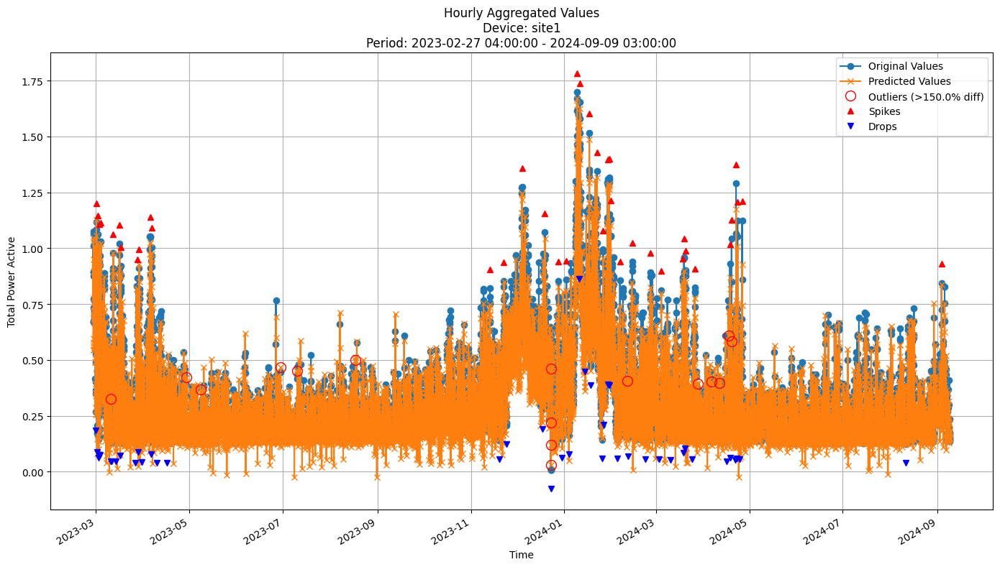


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0783
MAE: 0.0516
MAPE: 19.3902%

Directional Metrics:
Directional Accuracy: 50.4391%
First-Diff Correlation: 0.0885

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1471
  Recall: 0.1282
  F1 Score: 0.1370
Drops:
  Precision: 0.0882
  Recall: 0.0732
  F1 Score: 0.0800

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7059
  Recall: 0.6154
  F1 Score: 0.6575
Drops:
  Precision: 0.3235
  Recall: 0.2683
  F1 Score: 0.2933


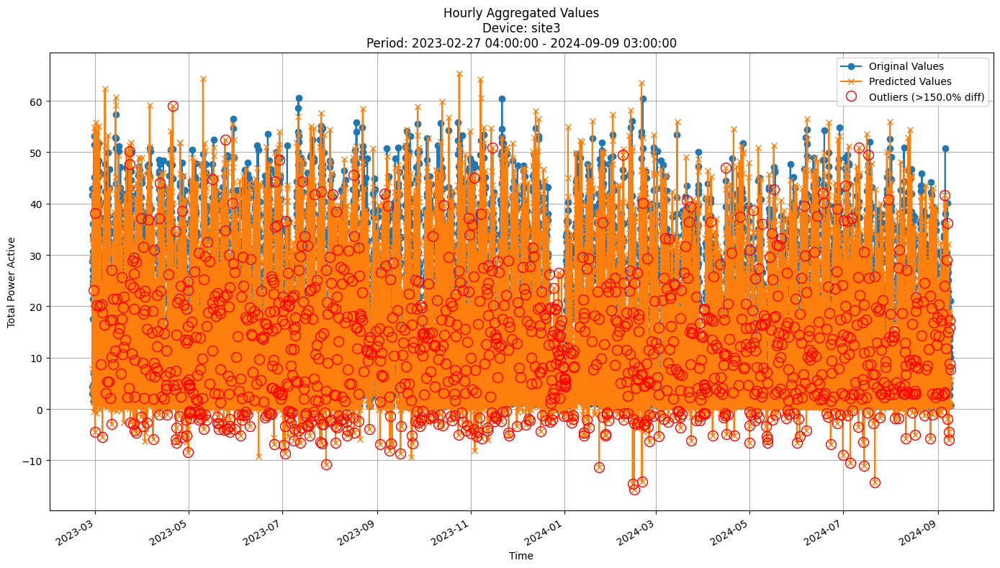


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.6938
MAE: 5.6835
MAPE: 69.0027%

Directional Metrics:
Directional Accuracy: 44.5974%
First-Diff Correlation: -0.0126

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


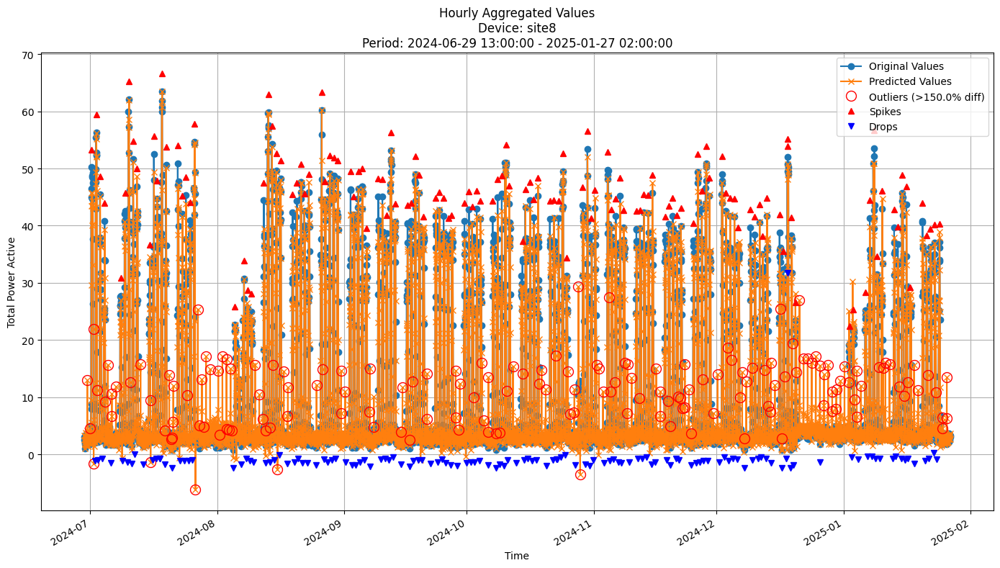


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.0790
MAE: 2.1912
MAPE: 34.1605%

Directional Metrics:
Directional Accuracy: 49.1532%
First-Diff Correlation: 0.4954

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0541
  Recall: 0.0593
  F1 Score: 0.0565
Drops:
  Precision: 0.0544
  Recall: 0.0588
  F1 Score: 0.0565

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8108
  Recall: 0.8889
  F1 Score: 0.8481
Drops:
  Precision: 0.4966
  Recall: 0.5368
  F1 Score: 0.5159


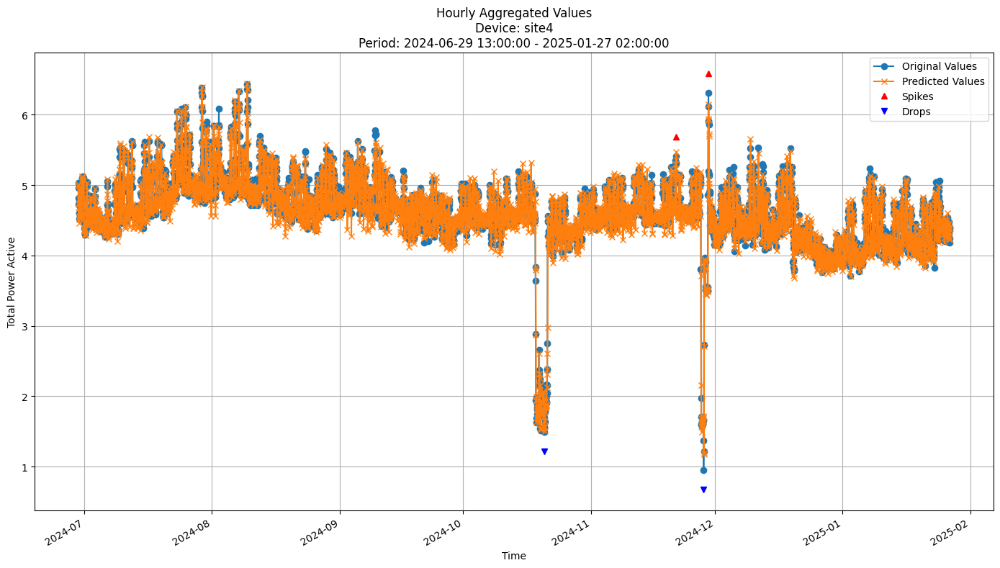


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1580
MAE: 0.1089
MAPE: 2.4197%

Directional Metrics:
Directional Accuracy: 46.8098%
First-Diff Correlation: 0.0624

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


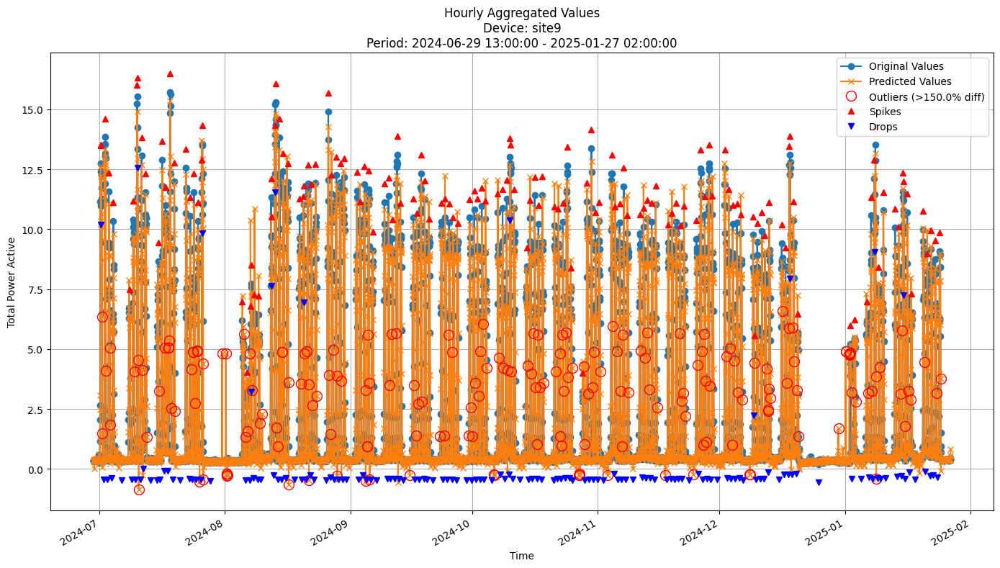


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2602
MAE: 0.5575
MAPE: 32.5680%

Directional Metrics:
Directional Accuracy: 48.0701%
First-Diff Correlation: 0.2759

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0676
  F1 Score: 0.0559
Drops:
  Precision: 0.0191
  Recall: 0.0270
  F1 Score: 0.0224

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6524
  Recall: 0.9257
  F1 Score: 0.7654
Drops:
  Precision: 0.2249
  Recall: 0.3176
  F1 Score: 0.2633


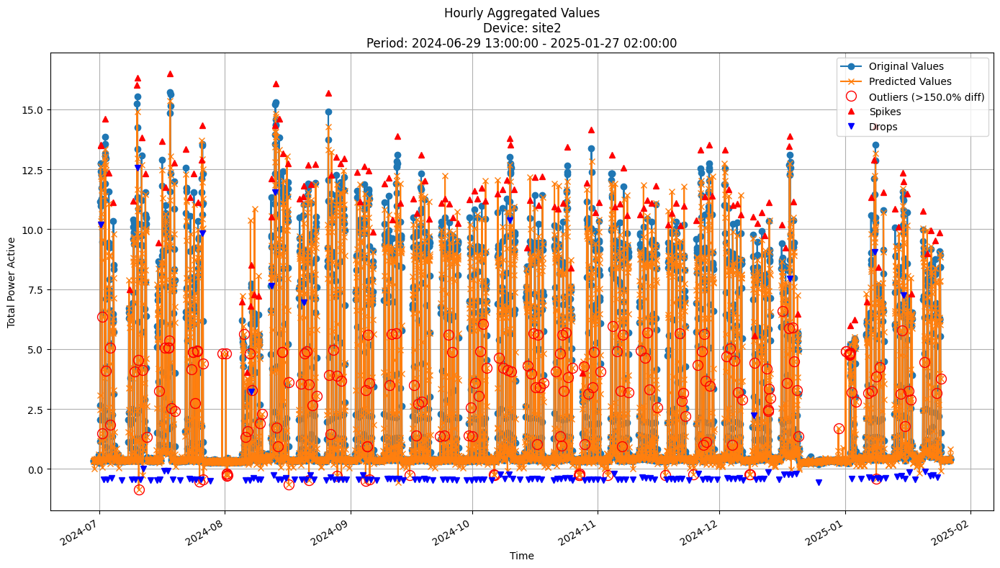


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2602
MAE: 0.5575
MAPE: 32.5680%

Directional Metrics:
Directional Accuracy: 48.0701%
First-Diff Correlation: 0.2759

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0676
  F1 Score: 0.0559
Drops:
  Precision: 0.0191
  Recall: 0.0270
  F1 Score: 0.0224

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6524
  Recall: 0.9257
  F1 Score: 0.7654
Drops:
  Precision: 0.2249
  Recall: 0.3176
  F1 Score: 0.2633


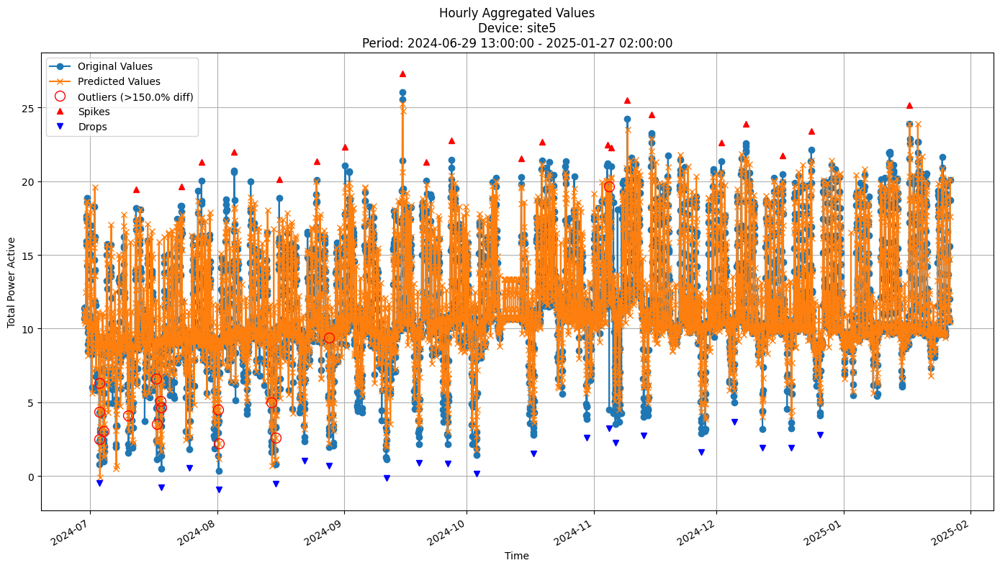


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5367
MAE: 1.0194
MAPE: 11.2608%

Directional Metrics:
Directional Accuracy: 57.4833%
First-Diff Correlation: 0.2168

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1000
  Recall: 0.0476
  F1 Score: 0.0645
Drops:
  Precision: 0.1000
  Recall: 0.0476
  F1 Score: 0.0645

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6000
  Recall: 0.2857
  F1 Score: 0.3871
Drops:
  Precision: 0.6000
  Recall: 0.2857
  F1 Score: 0.3871


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

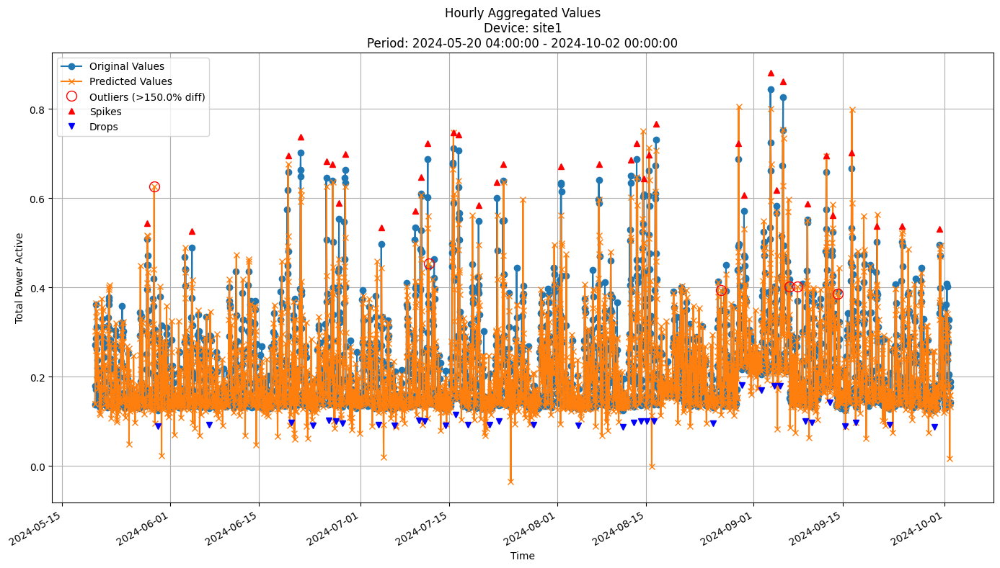


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0707
MAE: 0.0454
MAPE: 19.9525%

Directional Metrics:
Directional Accuracy: 46.9098%
First-Diff Correlation: 0.0375

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1515
  Recall: 0.1389
  F1 Score: 0.1449
Drops:
  Precision: 0.0312
  Recall: 0.0286
  F1 Score: 0.0299

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7576
  Recall: 0.6944
  F1 Score: 0.7246
Drops:
  Precision: 0.0938
  Recall: 0.0857
  F1 Score: 0.0896


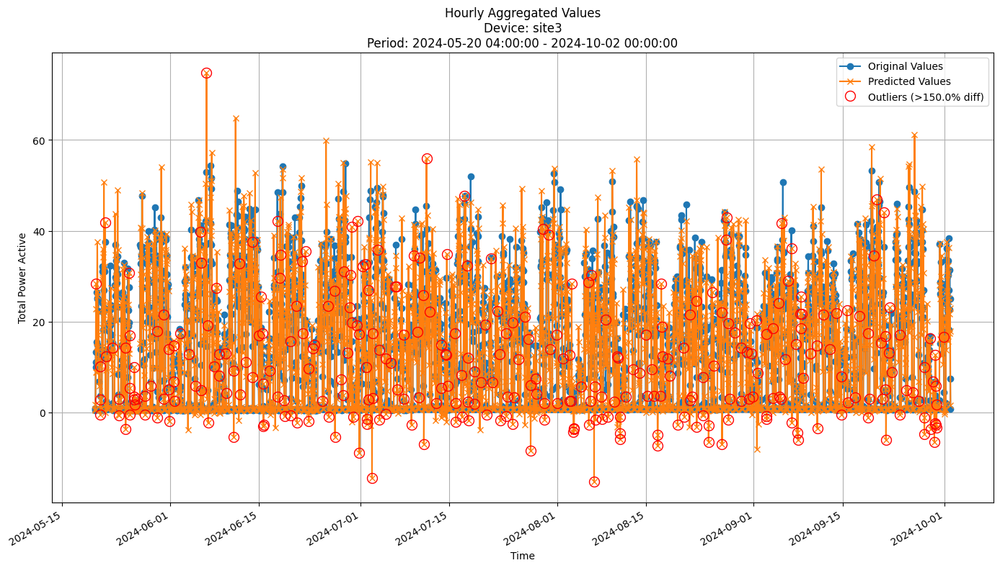


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.0333
MAE: 5.9349
MAPE: 69.8767%

Directional Metrics:
Directional Accuracy: 45.2101%
First-Diff Correlation: -0.0235

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


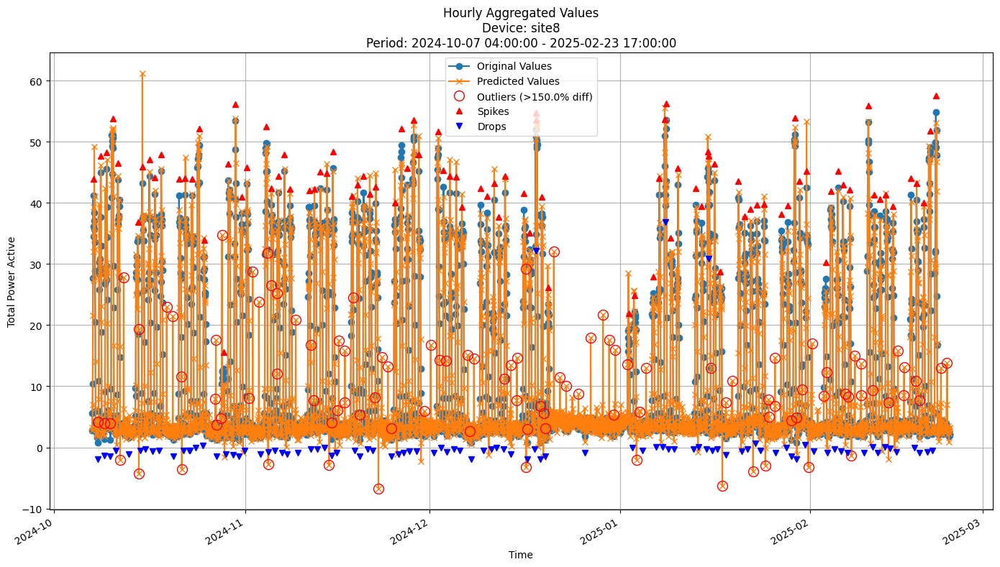


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.2784
MAE: 2.3223
MAPE: 35.4325%

Directional Metrics:
Directional Accuracy: 47.9403%
First-Diff Correlation: 0.4530

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0734
  Recall: 0.0842
  F1 Score: 0.0784
Drops:
  Precision: 0.0185
  Recall: 0.0211
  F1 Score: 0.0197

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7339
  Recall: 0.8421
  F1 Score: 0.7843
Drops:
  Precision: 0.3241
  Recall: 0.3684
  F1 Score: 0.3448


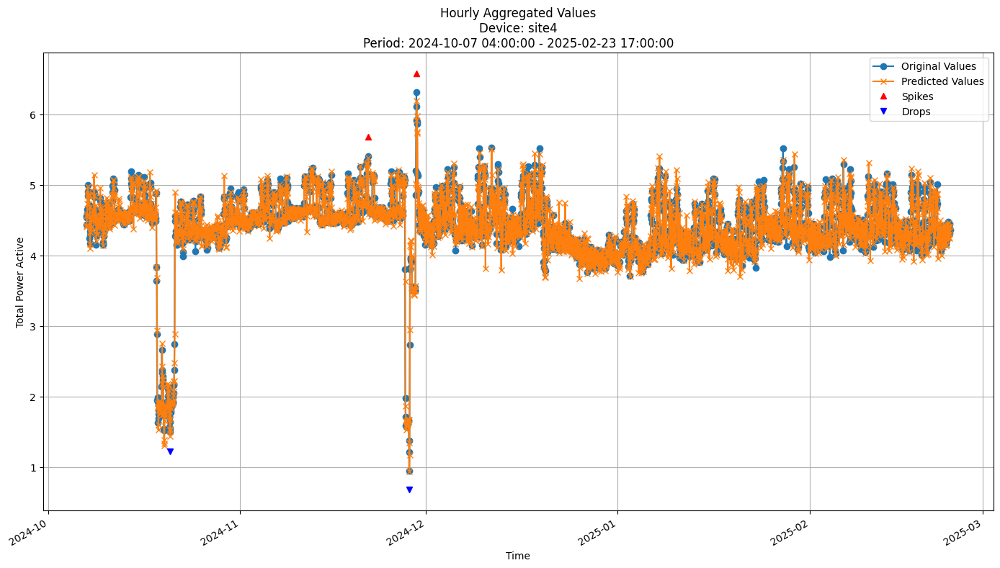


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1828
MAE: 0.1221
MAPE: 2.8526%

Directional Metrics:
Directional Accuracy: 42.2985%
First-Diff Correlation: -0.0736

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


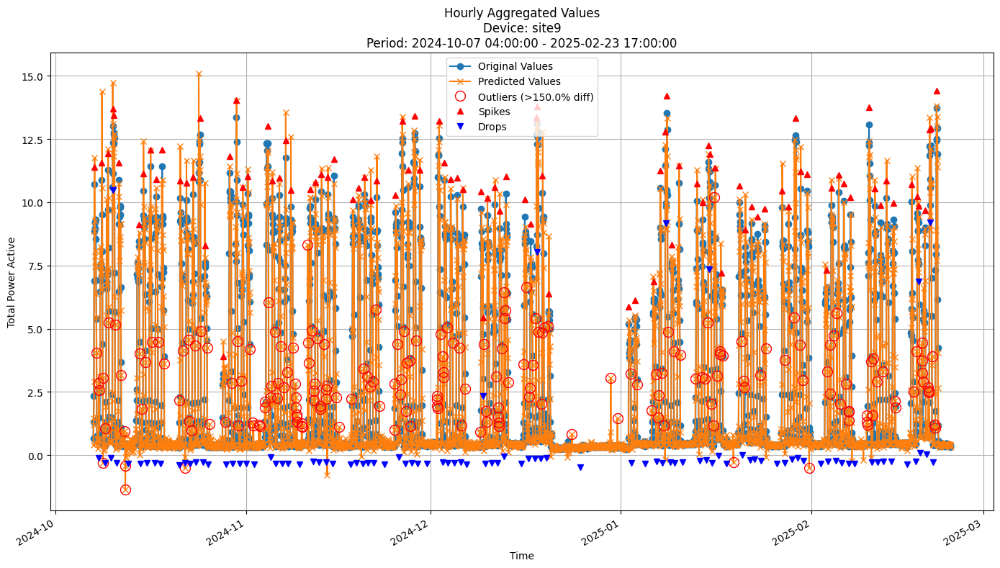


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2852
MAE: 0.6169
MAPE: 37.7111%

Directional Metrics:
Directional Accuracy: 47.9701%
First-Diff Correlation: 0.2588

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0846
  Recall: 0.1111
  F1 Score: 0.0961
Drops:
  Precision: 0.0620
  Recall: 0.0816
  F1 Score: 0.0705

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7077
  Recall: 0.9293
  F1 Score: 0.8035
Drops:
  Precision: 0.3333
  Recall: 0.4388
  F1 Score: 0.3789


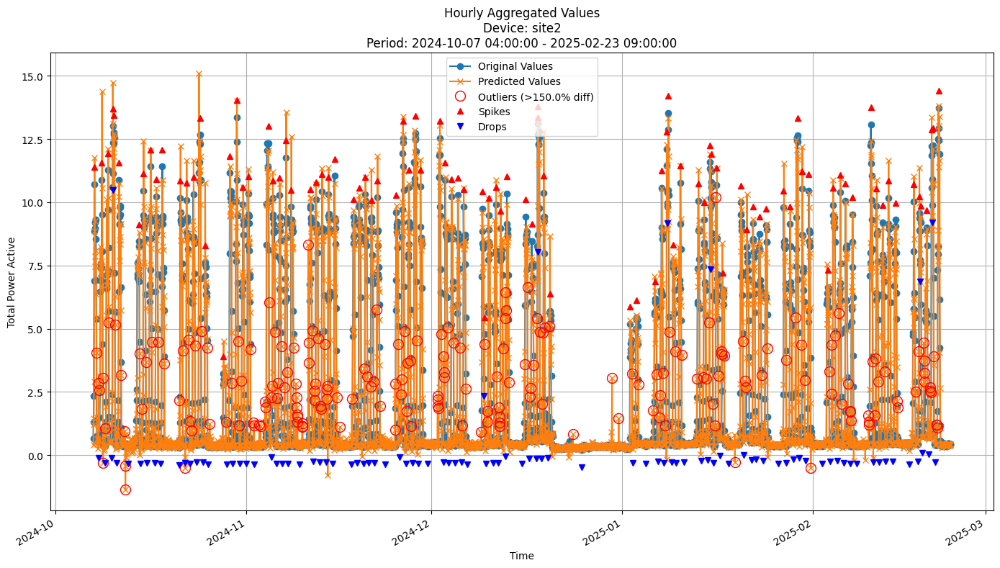


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2868
MAE: 0.6183
MAPE: 37.7784%

Directional Metrics:
Directional Accuracy: 47.9653%
First-Diff Correlation: 0.2588

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0846
  Recall: 0.1111
  F1 Score: 0.0961
Drops:
  Precision: 0.0620
  Recall: 0.0816
  F1 Score: 0.0705

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7077
  Recall: 0.9293
  F1 Score: 0.8035
Drops:
  Precision: 0.3333
  Recall: 0.4388
  F1 Score: 0.3789


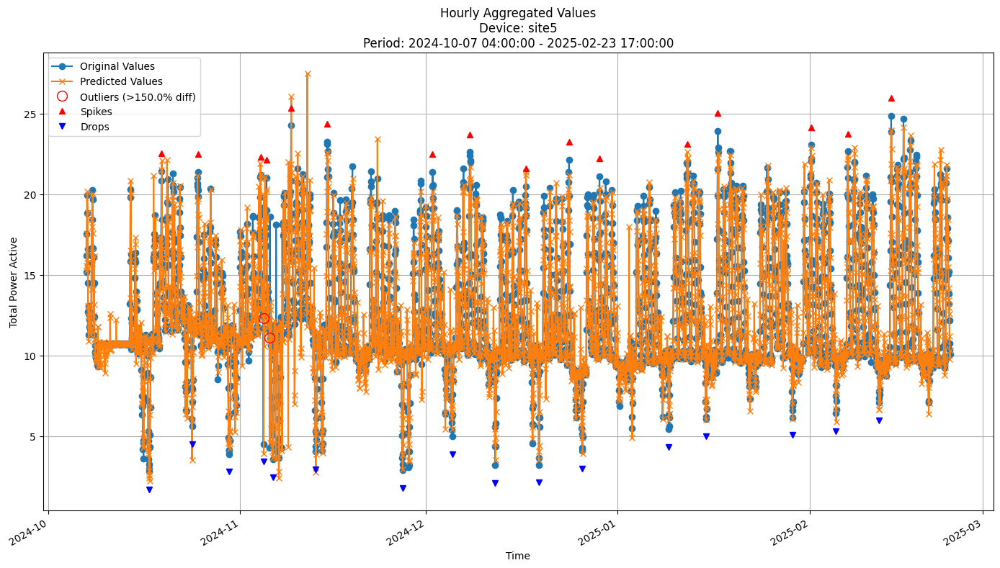


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3327
MAE: 0.8214
MAPE: 6.7668%

Directional Metrics:
Directional Accuracy: 60.3284%
First-Diff Correlation: 0.3406

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1000
  Recall: 0.0625
  F1 Score: 0.0769

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.3125
  F1 Score: 0.3846
Drops:
  Precision: 0.8000
  Recall: 0.5000
  F1 Score: 0.6154


In [39]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [40]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {
    'n_models': 60, 
    'max_feature': 0.5, 
    'max_depth': 30, 
    'aggregation_method': 'mean', 
    'disable_weighted_vote': True, 
    'eagerness': 0, 
    'tau': 0.01, 
    'delta': 0.1, 
    'grace_period': 0, 
    'grace_period_depth': 0,
    'hist' : [
        HistogramContainer(
        bin_type = get_histogram_type('mean'),
        ),
    ],
    'split_criterion': [VarianceReductionRelative],
}

In [ ]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 146.149124 MB


 2023-02-27 04:00:00+01:00    0.771073
2023-02-27 05:00:00+01:00    0.802448
2023-02-27 06:00:00+01:00    1.009154
2023-02-27 07:00:00+01:00    0.835917
2023-02-27 08:00:00+01:00    1.012825
                               ...   
2023-03-26 23:00:00+02:00    0.146452
2023-03-27 00:00:00+02:00    0.167375
2023-03-27 01:00:00+02:00    0.190958
2023-03-27 02:00:00+02:00    0.196801
2023-03-27 03:00:00+02:00    0.220493
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.230605
2023-03-27 05:00:00+02:00    0.227383
2023-03-27 06:00:00+02:00    0.297521
2023-03-27 07:00:00+02:00    0.441446
2023-03-27 08:00:00+02:00    0.434017
                               ...   
2023-04-23 23:00:00+02:00    0.150065
2023-04-24 00:00:00+02:00    0.135565


Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 183.451378 MB


 2023-02-27 04:00:00+01:00    0.775040
2023-02-27 05:00:00+01:00    0.820727
2023-02-27 06:00:00+01:00    1.021361
2023-02-27 07:00:00+01:00    0.833800
2023-02-27 08:00:00+01:00    1.034615
                               ...   
2023-04-23 23:00:00+02:00    0.142659
2023-04-24 00:00:00+02:00    0.139423
2023-04-24 01:00:00+02:00    0.141394
2023-04-24 02:00:00+02:00    0.142488
2023-04-24 03:00:00+02:00    0.140075
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.148163
2023-04-24 05:00:00+02:00    0.186713
2023-04-24 06:00:00+02:00    0.292351
2023-04-24 07:00:00+02:00    0.329910
2023-04-24 08:00:00+02:00    0.346640
                               ...   
2023-05-21 23:00:00+02:00    0.194257
2023-05-22 00:00:00+02:00    0.176193

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 455.595650 MB


 2024-06-29 13:00:00+02:00    3.044814
2024-06-29 14:00:00+02:00    2.980702
2024-06-29 15:00:00+02:00    2.067411
2024-06-29 16:00:00+02:00    1.795355
2024-06-29 17:00:00+02:00    2.576743
                               ...   
2024-12-29 22:00:00+01:00    3.812672
2024-12-29 23:00:00+01:00    2.980455
2024-12-30 00:00:00+01:00    4.123398
2024-12-30 01:00:00+01:00    4.413385
2024-12-30 02:00:00+01:00    3.365365
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00     5.382431
2024-12-30 04:00:00+01:00     5.785844
2024-12-30 05:00:00+01:00    10.818316
2024-12-30 06:00:00+01:00    14.998349
2024-12-30 07:00:00+01:00     8.014873
                               ...    
2025-01-26 22:00:00+01:00     3.447439
2025-01-26 23:00:00+01:00     

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 501.320343 MB


 2024-06-29 13:00:00+02:00    3.025531
2024-06-29 14:00:00+02:00    2.762102
2024-06-29 15:00:00+02:00    2.254668
2024-06-29 16:00:00+02:00    1.783899
2024-06-29 17:00:00+02:00    2.588843
                               ...   
2025-01-26 22:00:00+01:00    3.225963
2025-01-26 23:00:00+01:00    3.044705
2025-01-27 00:00:00+01:00    2.608025
2025-01-27 01:00:00+01:00    2.914023
2025-01-27 02:00:00+01:00    3.339292
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     3.472344
2025-01-27 04:00:00+01:00     5.034494
2025-01-27 05:00:00+01:00     7.665670
2025-01-27 06:00:00+01:00    15.323095
2025-01-27 07:00:00+01:00    39.826739
                               ...    
2025-02-23 13:00:00+01:00     1.979982
2025-02-23 14:00:00+01:00     

#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0543 ± 0.0038
	MAE: 0.0367 ± 0.0030
	MAPE: 13.9342% ± 0.7952%

	Directional Metrics:
		Directional Accuracy: 57.8102% ± 3.5454%
		First-Diff Correlation: 0.2356 ± 0.0710

	Immediate Detection (delta=0):
		Spike Precision: 0.1405 ± 0.0290
		Spike Recall: 0.1281 ± 0.0233
		Spike F1: 0.1333 ± 0.0237
		Drop Precision: 0.1497 ± 0.0212
		Drop Recall: 0.1326 ± 0.0205
		Drop F1: 0.1399 ± 0.0182

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8202 ± 0.0574
		Spike Recall: 0.7537 ± 0.0627
		Spike F1: 0.7817 ± 0.0282
		Drop Precision: 0.5881 ± 0.0789
		Drop Recall: 0.5238 ± 0.0941
		Drop F1: 0.5514 ± 0.0807
Daily Metrics:
	RMSE: 0.2105 ± 0.0714
	MAE: 0.1522 ± 0.0490
	MAPE: 2.2111% ± 0.4001%

	Directional Metrics:
		Directional Accuracy: 96.9490% ± 1.4352%
		First-Diff Correlation: 0.9954 ± 0.0017

	Immediate Detection (delta=0):
		Spik

#### Training plots

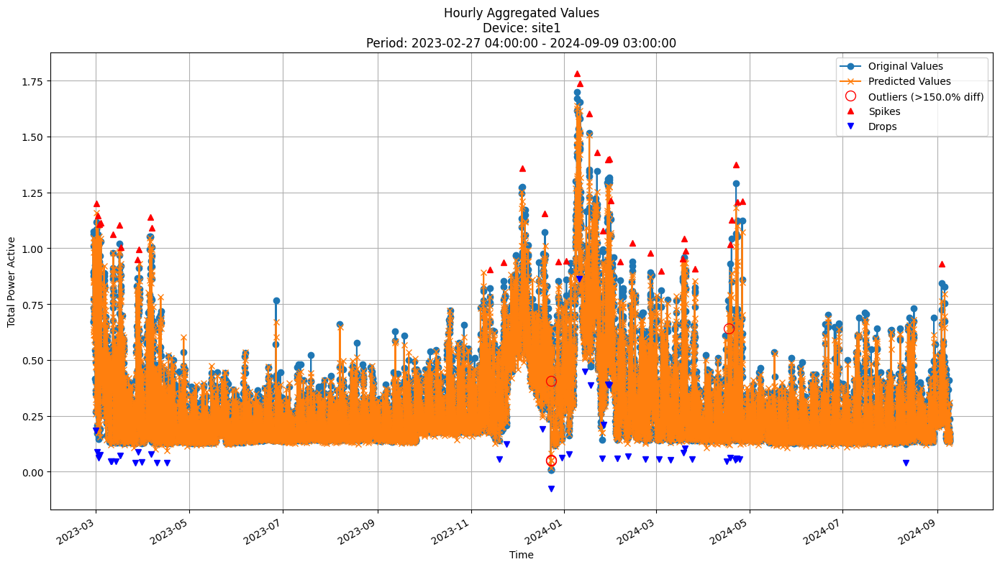


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0554
MAE: 0.0371
MAPE: 14.1276%

Directional Metrics:
Directional Accuracy: 55.1049%
First-Diff Correlation: 0.2190

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1765
  Recall: 0.1538
  F1 Score: 0.1644
Drops:
  Precision: 0.1176
  Recall: 0.0976
  F1 Score: 0.1067

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7647
  Recall: 0.6667
  F1 Score: 0.7123
Drops:
  Precision: 0.6176
  Recall: 0.5122
  F1 Score: 0.5600


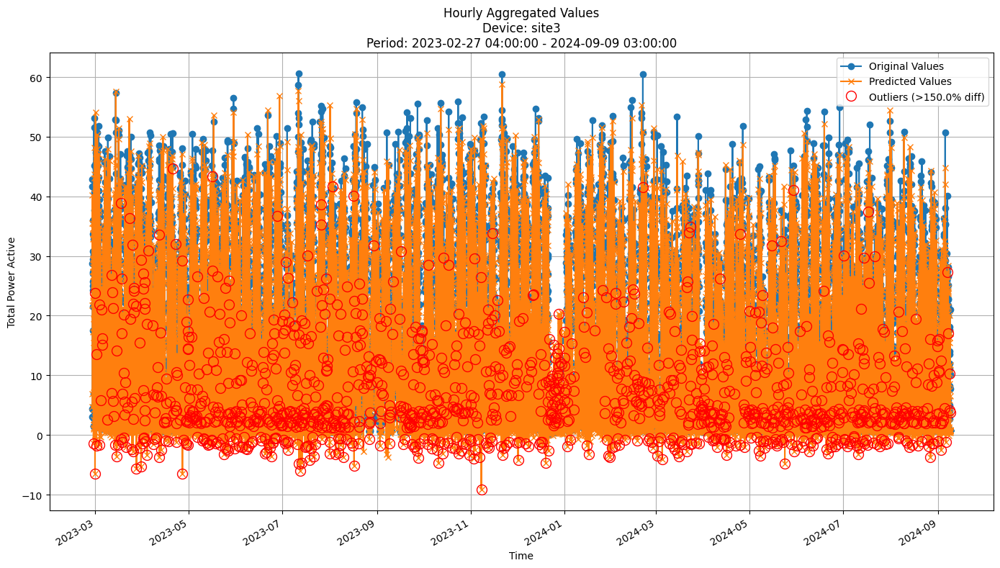


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.7600
MAE: 4.5058
MAPE: 63.2105%

Directional Metrics:
Directional Accuracy: 48.6828%
First-Diff Correlation: 0.1431

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


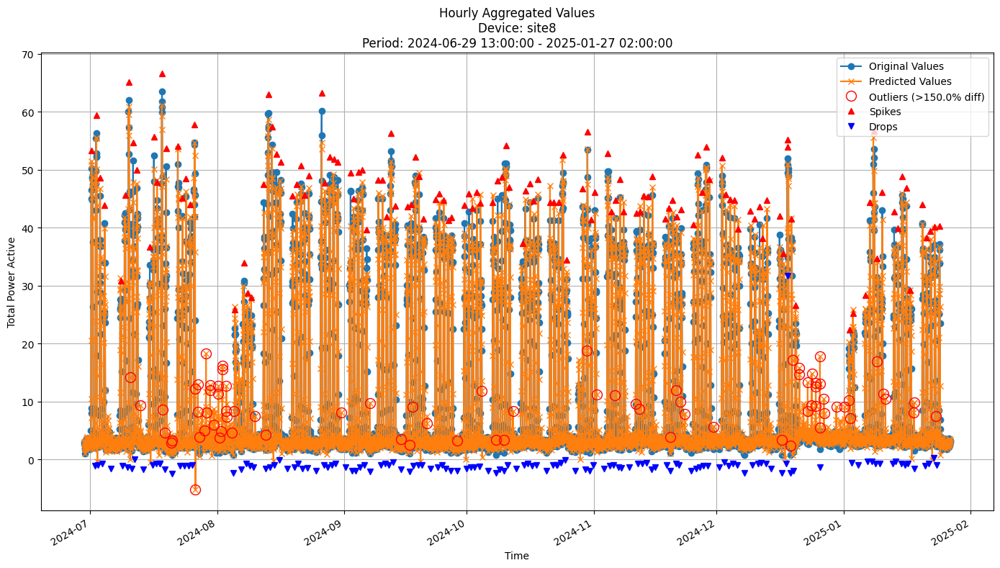


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.2688
MAE: 1.7628
MAPE: 26.0813%

Directional Metrics:
Directional Accuracy: 53.5250%
First-Diff Correlation: 0.5706

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0423
  Recall: 0.0444
  F1 Score: 0.0433
Drops:
  Precision: 0.0426
  Recall: 0.0441
  F1 Score: 0.0433

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8169
  Recall: 0.8593
  F1 Score: 0.8375
Drops:
  Precision: 0.3972
  Recall: 0.4118
  F1 Score: 0.4043


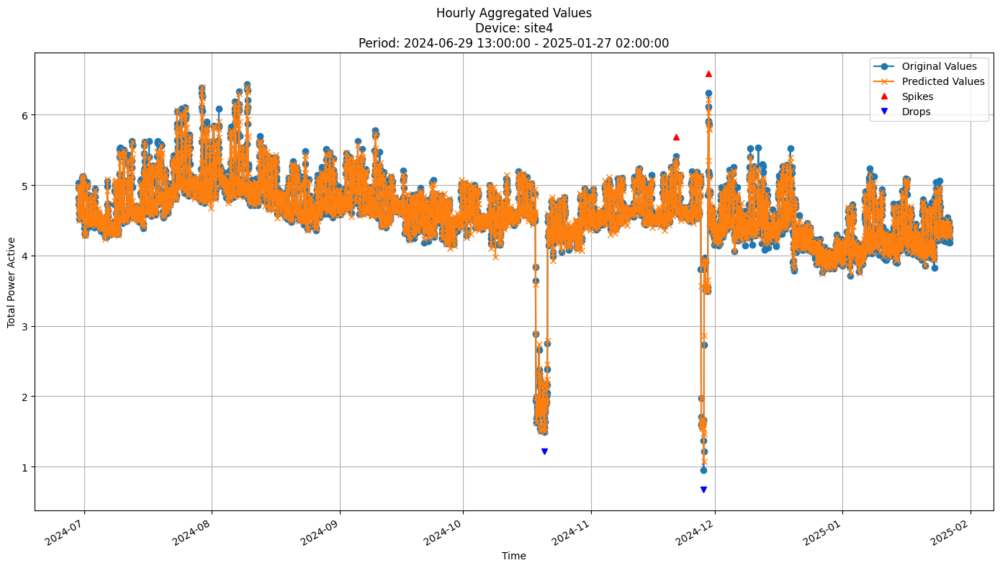


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1179
MAE: 0.0762
MAPE: 1.7179%

Directional Metrics:
Directional Accuracy: 51.7724%
First-Diff Correlation: 0.2487

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


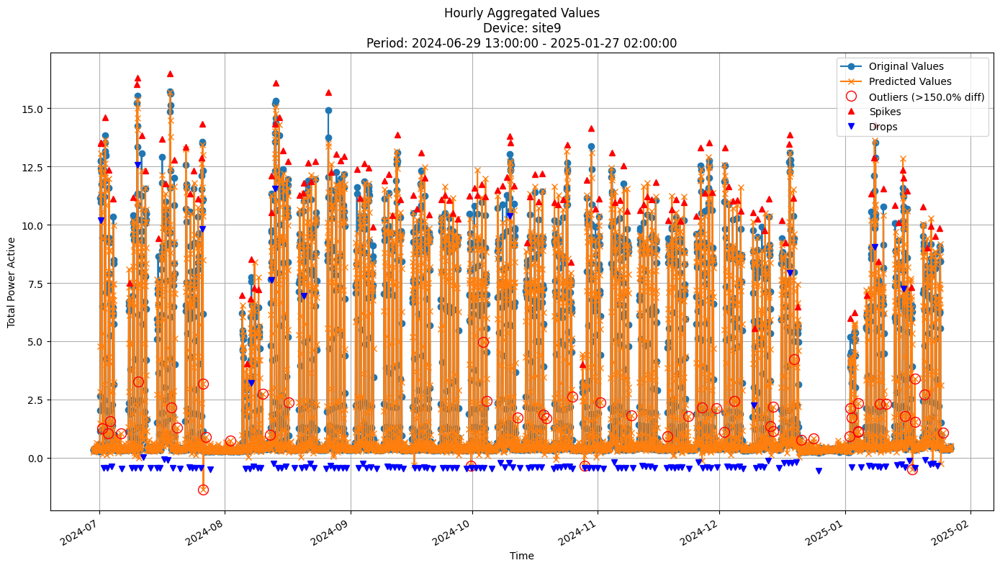


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7553
MAE: 0.3587
MAPE: 20.2059%

Directional Metrics:
Directional Accuracy: 54.3718%
First-Diff Correlation: 0.6248

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0980
  Recall: 0.1014
  F1 Score: 0.0997
Drops:
  Precision: 0.0395
  Recall: 0.0405
  F1 Score: 0.0400

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8301
  Recall: 0.8581
  F1 Score: 0.8439
Drops:
  Precision: 0.2105
  Recall: 0.2162
  F1 Score: 0.2133


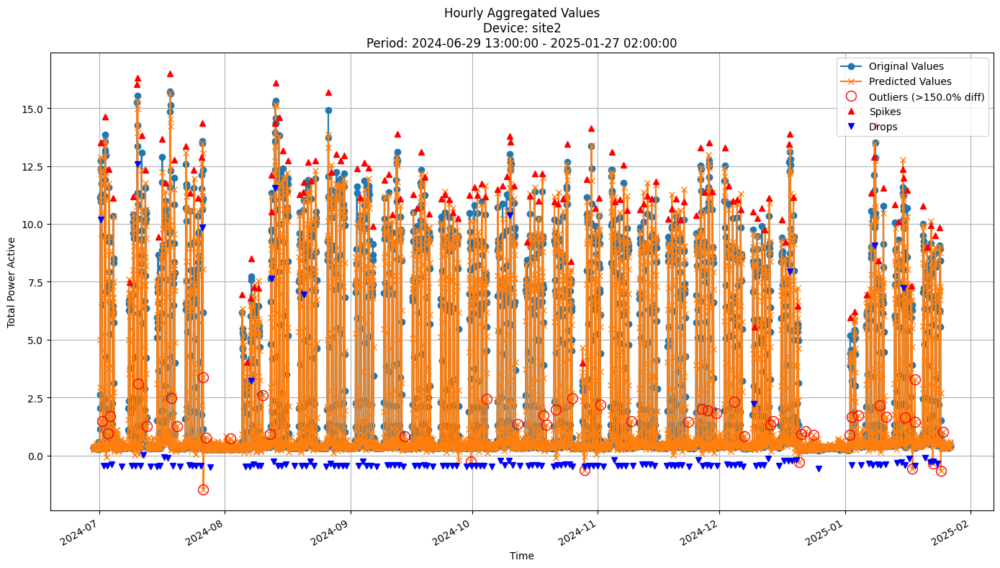


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7541
MAE: 0.3556
MAPE: 20.3633%

Directional Metrics:
Directional Accuracy: 55.1595%
First-Diff Correlation: 0.6259

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1034
  Recall: 0.1014
  F1 Score: 0.1024
Drops:
  Precision: 0.0625
  Recall: 0.0608
  F1 Score: 0.0616

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8759
  Recall: 0.8581
  F1 Score: 0.8669
Drops:
  Precision: 0.2222
  Recall: 0.2162
  F1 Score: 0.2192


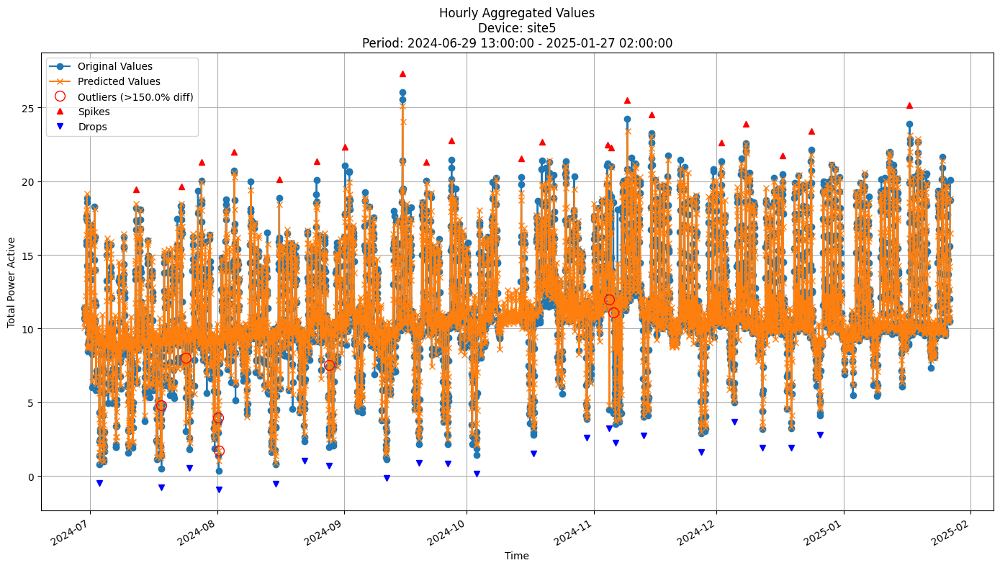


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1354
MAE: 0.7388
MAPE: 7.6665%

Directional Metrics:
Directional Accuracy: 61.1461%
First-Diff Correlation: 0.2904

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0588
  Recall: 0.0476
  F1 Score: 0.0526
Drops:
  Precision: 0.1667
  Recall: 0.1429
  F1 Score: 0.1538

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7647
  Recall: 0.6190
  F1 Score: 0.6842
Drops:
  Precision: 0.7778
  Recall: 0.6667
  F1 Score: 0.7179


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

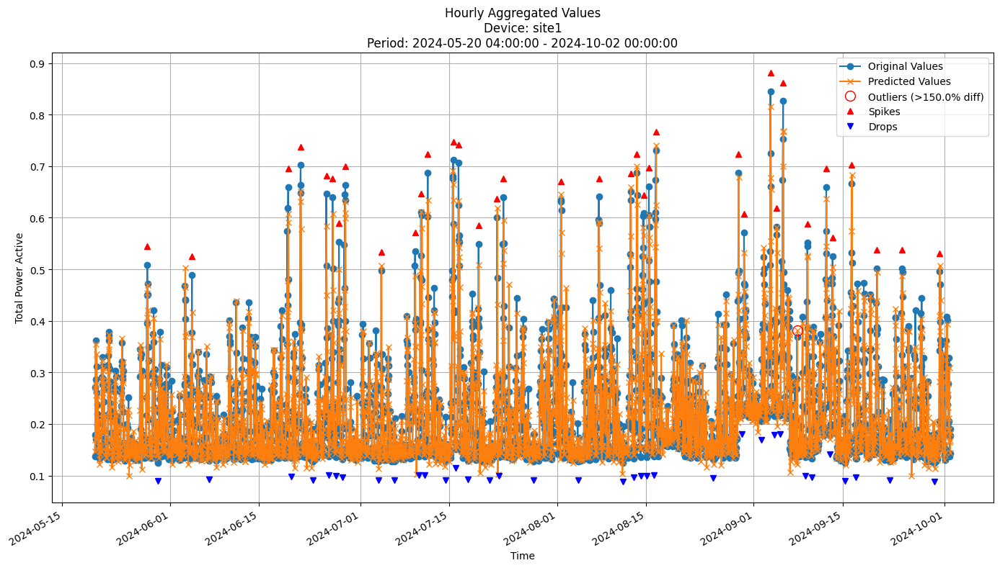


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0592
MAE: 0.0374
MAPE: 16.2590%

Directional Metrics:
Directional Accuracy: 48.7948%
First-Diff Correlation: 0.0670

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1538
  Recall: 0.1111
  F1 Score: 0.1290
Drops:
  Precision: 0.0385
  Recall: 0.0286
  F1 Score: 0.0328

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9231
  Recall: 0.6667
  F1 Score: 0.7742
Drops:
  Precision: 0.2692
  Recall: 0.2000
  F1 Score: 0.2295


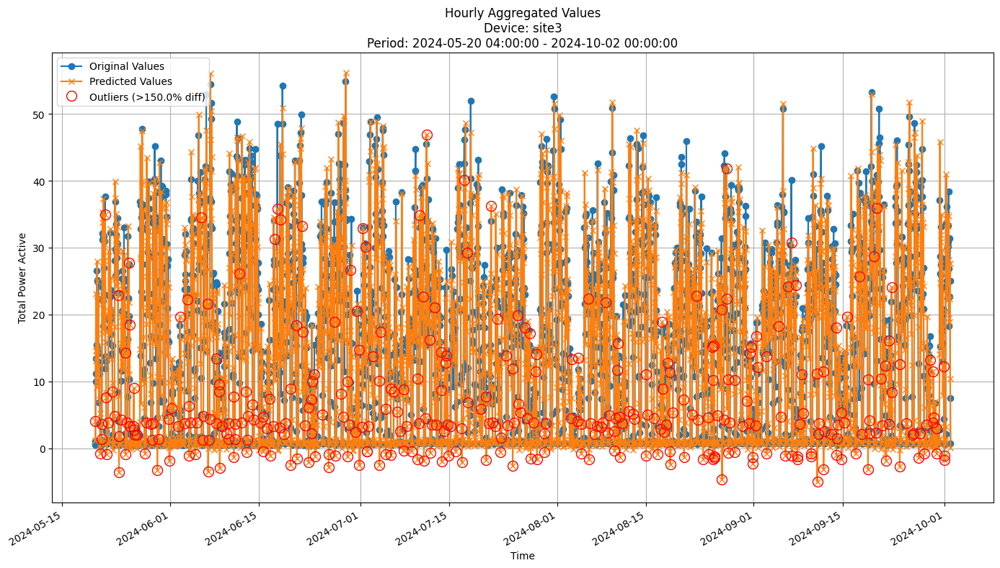


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.3814
MAE: 4.8943
MAPE: 64.7760%

Directional Metrics:
Directional Accuracy: 45.0865%
First-Diff Correlation: 0.0247

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


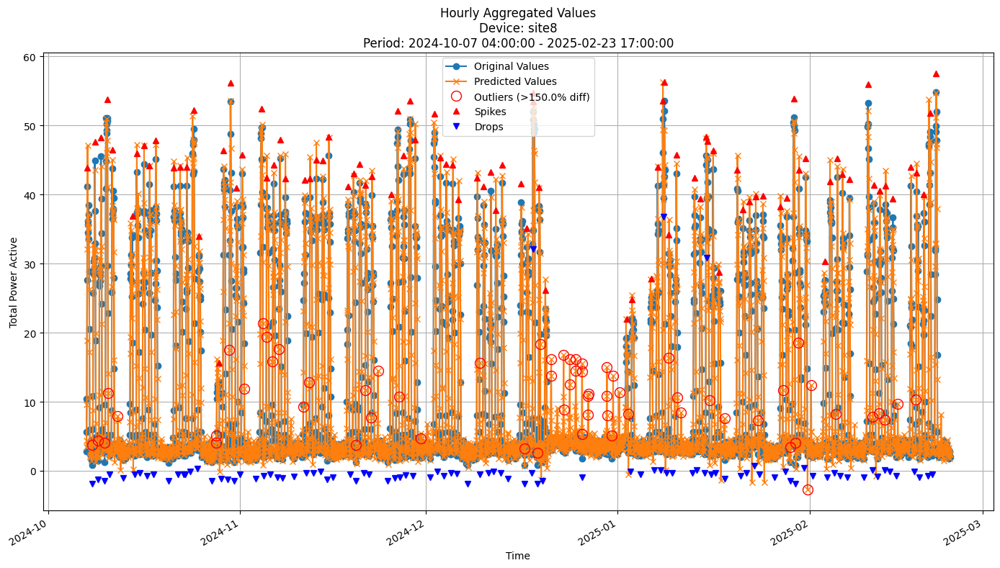


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.6818
MAE: 2.0530
MAPE: 29.6244%

Directional Metrics:
Directional Accuracy: 49.0448%
First-Diff Correlation: 0.4314

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0851
  Recall: 0.0842
  F1 Score: 0.0847
Drops:
  Precision: 0.0323
  Recall: 0.0316
  F1 Score: 0.0319

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8936
  Recall: 0.8842
  F1 Score: 0.8889
Drops:
  Precision: 0.3548
  Recall: 0.3474
  F1 Score: 0.3511


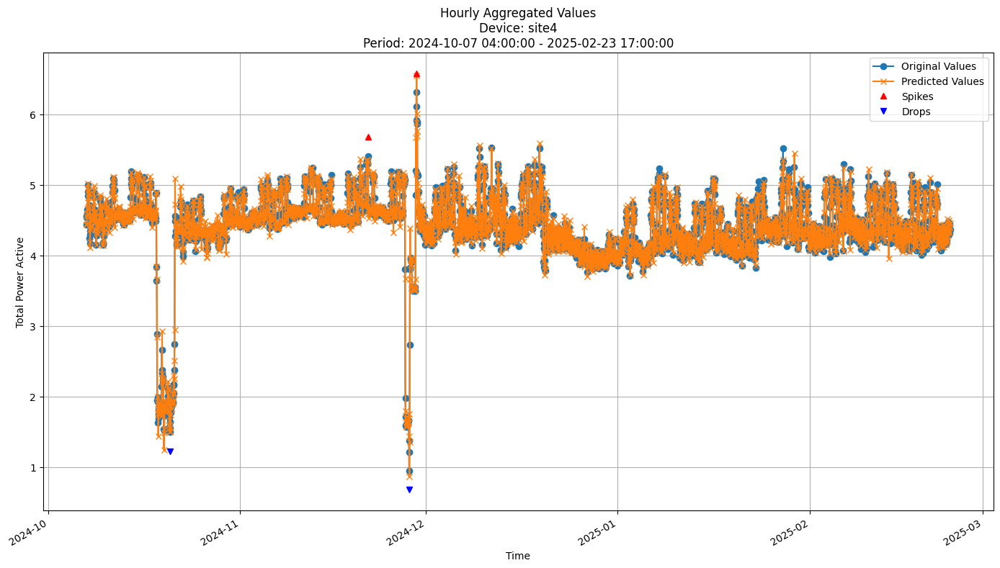


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1691
MAE: 0.1124
MAPE: 2.6255%

Directional Metrics:
Directional Accuracy: 40.5373%
First-Diff Correlation: -0.0906

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


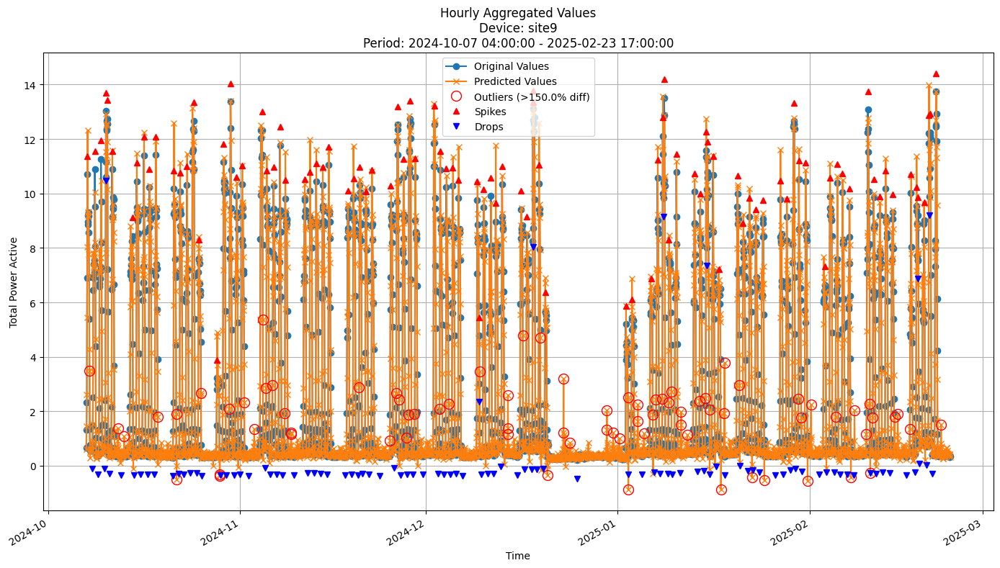


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8342
MAE: 0.4220
MAPE: 26.2908%

Directional Metrics:
Directional Accuracy: 52.5672%
First-Diff Correlation: 0.5209

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0990
  Recall: 0.1010
  F1 Score: 0.1000
Drops:
  Precision: 0.0700
  Recall: 0.0714
  F1 Score: 0.0707

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8614
  Recall: 0.8788
  F1 Score: 0.8700
Drops:
  Precision: 0.2600
  Recall: 0.2653
  F1 Score: 0.2626


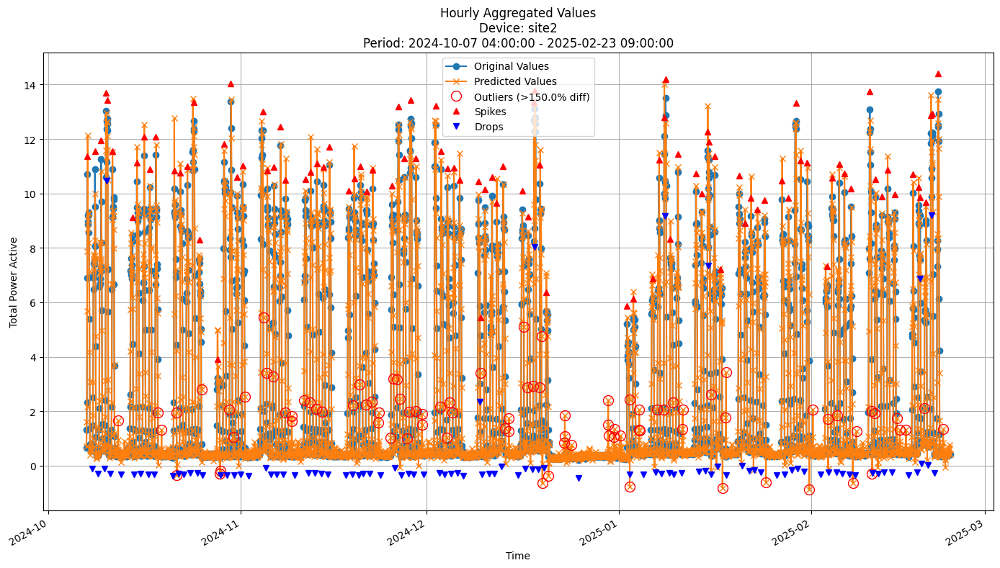


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8407
MAE: 0.4205
MAPE: 26.0555%

Directional Metrics:
Directional Accuracy: 52.7229%
First-Diff Correlation: 0.5144

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0816
  Recall: 0.0808
  F1 Score: 0.0812
Drops:
  Precision: 0.0825
  Recall: 0.0816
  F1 Score: 0.0821

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8878
  Recall: 0.8788
  F1 Score: 0.8832
Drops:
  Precision: 0.2784
  Recall: 0.2755
  F1 Score: 0.2769


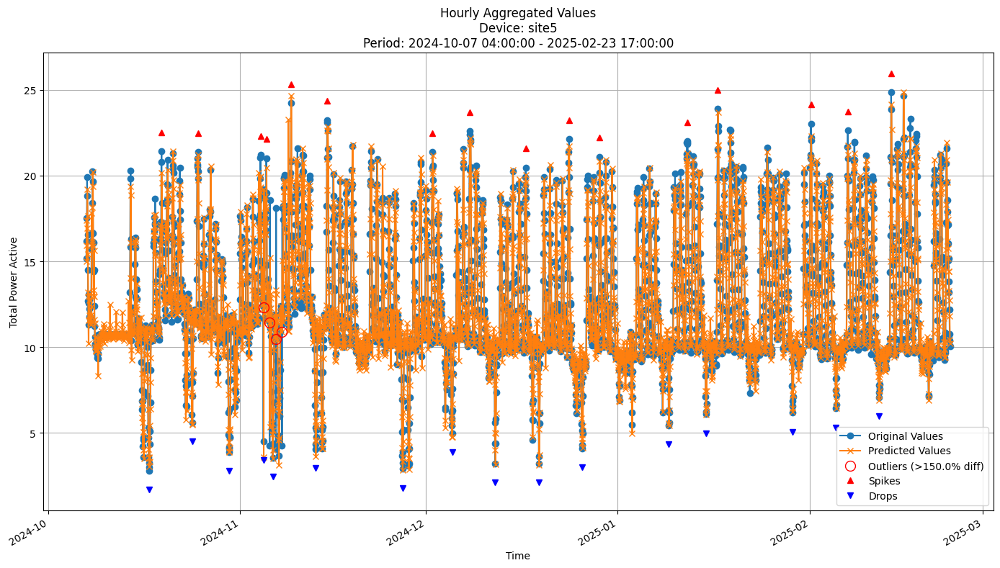


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1696
MAE: 0.7429
MAPE: 6.0076%

Directional Metrics:
Directional Accuracy: 61.1343%
First-Diff Correlation: 0.3217

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1429
  Recall: 0.1250
  F1 Score: 0.1333

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5714
  Recall: 0.5000
  F1 Score: 0.5333
Drops:
  Precision: 0.7857
  Recall: 0.6875
  F1 Score: 0.7333


In [44]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:


incb = IncubationBoost
incb_params = {
    'length': 20, 
    'learning_rate': 0.5, 
    'depth': 5, 
    'grace_period': 48, 
    'grace_period_depth': -1, 
    'split_confidence': 0.5, 
    'max_feature': 1.0, 
    'tie_threshold': 0.05, 
    'hist' : [
        HistogramContainer(
        bin_type = get_histogram_type('adaptive'),
        max_bins = 4,
        ),
    ],
    'split_criterion': [VarianceReductionRelative]
    'verbose': False
}


In [ ]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.186440 MB


 2023-02-27 04:00:00+01:00    0.740309
2023-02-27 05:00:00+01:00    0.778059
2023-02-27 06:00:00+01:00    1.017559
2023-02-27 07:00:00+01:00    0.881809
2023-02-27 08:00:00+01:00    1.014890
                               ...   
2023-03-26 23:00:00+02:00    0.138376
2023-03-27 00:00:00+02:00    0.147876
2023-03-27 01:00:00+02:00    0.172626
2023-03-27 02:00:00+02:00    0.192876
2023-03-27 03:00:00+02:00    0.237876
Length: 671, dtype: float64


 2023-03-27 04:00:00+02:00    0.215626
2023-03-27 05:00:00+02:00    0.206626
2023-03-27 06:00:00+02:00    0.246626
2023-03-27 07:00:00+02:00    0.405876
2023-03-27 08:00:00+02:00    0.416626
                               ...   
2023-04-23 23:00:00+02:00    0.131376
2023-04-24 00:00:00+02:00    0.137376
20

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.158531 MB


 2023-02-27 04:00:00+01:00    0.740309
2023-02-27 05:00:00+01:00    0.778059
2023-02-27 06:00:00+01:00    1.017559
2023-02-27 07:00:00+01:00    0.881809
2023-02-27 08:00:00+01:00    1.014890
                               ...   
2023-04-23 23:00:00+02:00    0.131376
2023-04-24 00:00:00+02:00    0.137376
2023-04-24 01:00:00+02:00    0.137376
2023-04-24 02:00:00+02:00    0.138126
2023-04-24 03:00:00+02:00    0.132626
Length: 1343, dtype: float64


 2023-04-24 04:00:00+02:00    0.136376
2023-04-24 05:00:00+02:00    0.162626
2023-04-24 06:00:00+02:00    0.177376
2023-04-24 07:00:00+02:00    0.278876
2023-04-24 08:00:00+02:00    0.288626
                               ...   
2023-05-21 23:00:00+02:00    0.192876
2023-05-22 00:00:00+02:00    0.173626
2

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.276649 MB


 2024-06-29 13:00:00+02:00    2.934834
2024-06-29 14:00:00+02:00    3.001113
2024-06-29 15:00:00+02:00    2.590642
2024-06-29 16:00:00+02:00    1.796765
2024-06-29 17:00:00+02:00    2.813715
                               ...   
2024-12-29 22:00:00+01:00    3.796988
2024-12-29 23:00:00+01:00    3.767786
2024-12-30 00:00:00+01:00    2.556601
2024-12-30 01:00:00+01:00    5.198333
2024-12-30 02:00:00+01:00    4.153908
Length: 4407, dtype: float64


 2024-12-30 03:00:00+01:00    2.991331
2024-12-30 04:00:00+01:00    3.814838
2024-12-30 05:00:00+01:00    4.556430
2024-12-30 06:00:00+01:00    3.378428
2024-12-30 07:00:00+01:00    2.500367
                               ...   
2025-01-26 22:00:00+01:00    3.420839
2025-01-26 23:00:00+01:00    2.630062
2

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.287346 MB


 2024-06-29 13:00:00+02:00    2.934834
2024-06-29 14:00:00+02:00    3.001113
2024-06-29 15:00:00+02:00    2.590642
2024-06-29 16:00:00+02:00    1.796765
2024-06-29 17:00:00+02:00    2.813715
                               ...   
2025-01-26 22:00:00+01:00    3.420839
2025-01-26 23:00:00+01:00    2.630062
2025-01-27 00:00:00+01:00    3.394334
2025-01-27 01:00:00+01:00    2.785843
2025-01-27 02:00:00+01:00    3.614838
Length: 5079, dtype: float64


 2025-01-27 03:00:00+01:00     3.395109
2025-01-27 04:00:00+01:00     3.496285
2025-01-27 05:00:00+01:00     3.553458
2025-01-27 06:00:00+01:00     9.512249
2025-01-27 07:00:00+01:00    35.888677
                               ...    
2025-02-23 13:00:00+01:00     1.813381
2025-02-23 14:00:00+01:00     2.

#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0734 ± 0.0041
	MAE: 0.0483 ± 0.0038
	MAPE: 17.9776% ± 0.5907%

	Directional Metrics:
		Directional Accuracy: 46.8528% ± 2.6462%
		First-Diff Correlation: -0.0630 ± 0.0500

	Immediate Detection (delta=0):
		Spike Precision: 0.0170 ± 0.0274
		Spike Recall: 0.0175 ± 0.0281
		Spike F1: 0.0173 ± 0.0277
		Drop Precision: 0.0052 ± 0.0069
		Drop Recall: 0.0054 ± 0.0078
		Drop F1: 0.0053 ± 0.0073

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9334 ± 0.0771
		Spike Recall: 0.9425 ± 0.0600
		Spike F1: 0.9376 ± 0.0681
		Drop Precision: 0.9568 ± 0.0851
		Drop Recall: 0.9651 ± 0.0658
		Drop F1: 0.9607 ± 0.0759
Daily Metrics:
	RMSE: 0.1604 ± 0.0428
	MAE: 0.0842 ± 0.0249
	MAPE: 0.9510% ± 0.1923%

	Directional Metrics:
		Directional Accuracy: 97.6070% ± 0.6925%
		First-Diff Correlation: 0.9964 ± 0.0003

	Immediate Detection (delta=0):
		Spi

#### Train plots

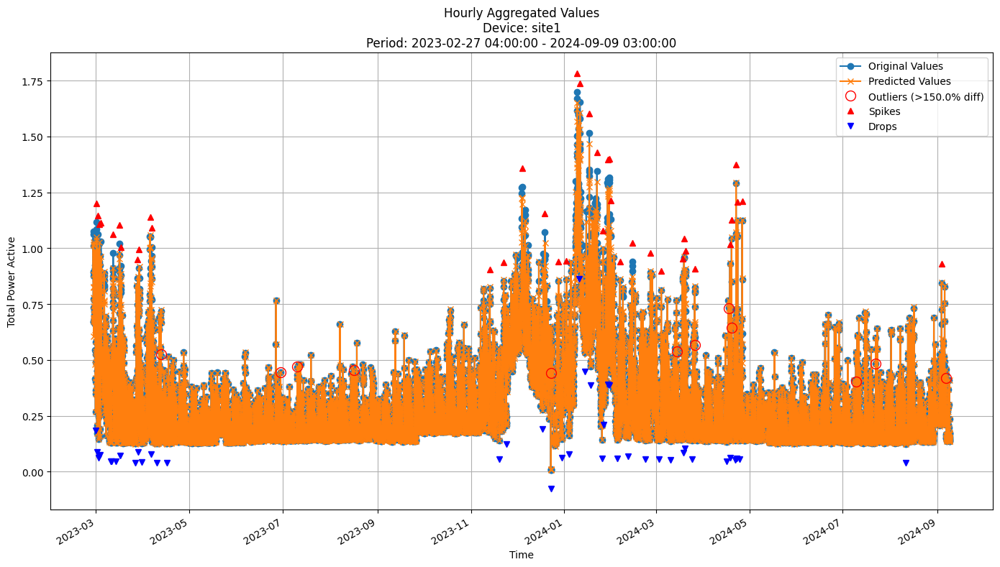


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0736
MAE: 0.0478
MAPE: 17.6012%

Directional Metrics:
Directional Accuracy: 45.2746%
First-Diff Correlation: -0.0637

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0270
  Recall: 0.0256
  F1 Score: 0.0263
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8919
  Recall: 0.8462
  F1 Score: 0.8684
Drops:
  Precision: 0.9487
  Recall: 0.9024
  F1 Score: 0.9250


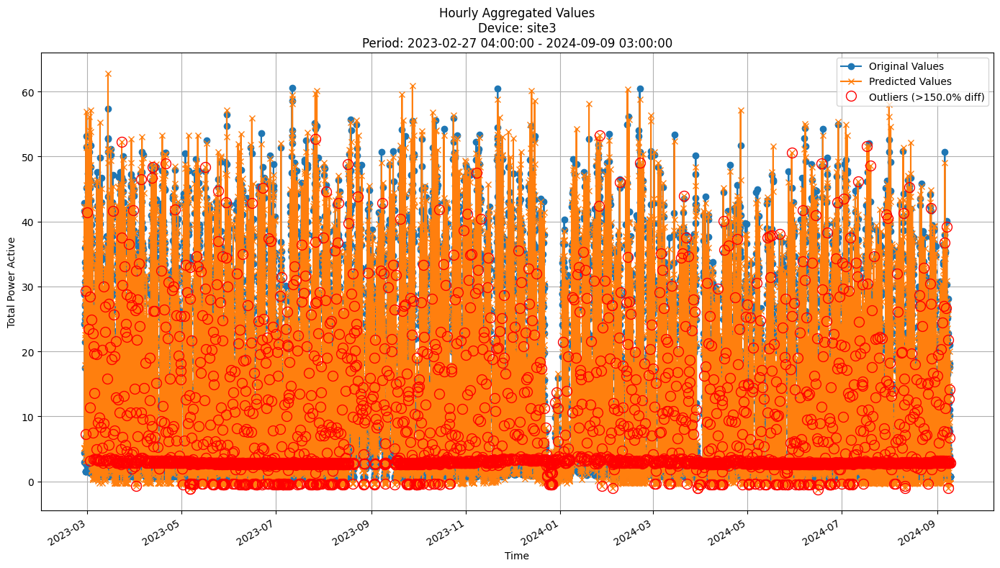


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.2054
MAE: 6.2419
MAPE: 116.6876%

Directional Metrics:
Directional Accuracy: 40.2515%
First-Diff Correlation: -0.1325

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


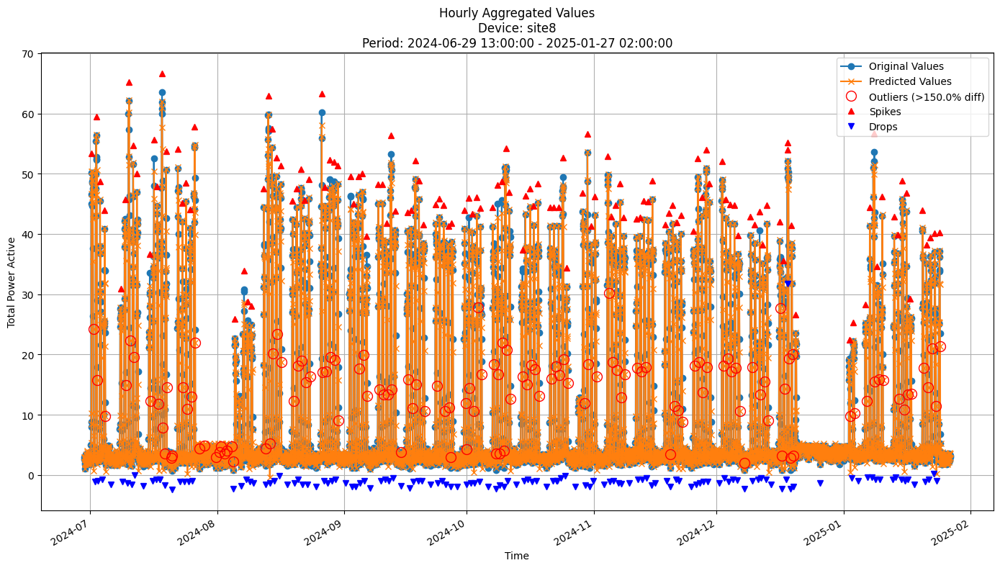


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.2707
MAE: 2.4748
MAPE: 30.8708%

Directional Metrics:
Directional Accuracy: 46.9279%
First-Diff Correlation: 0.2848

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0222
  Recall: 0.0222
  F1 Score: 0.0222
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9481
  Recall: 0.9481
  F1 Score: 0.9481
Drops:
  Precision: 0.5597
  Recall: 0.5515
  F1 Score: 0.5556


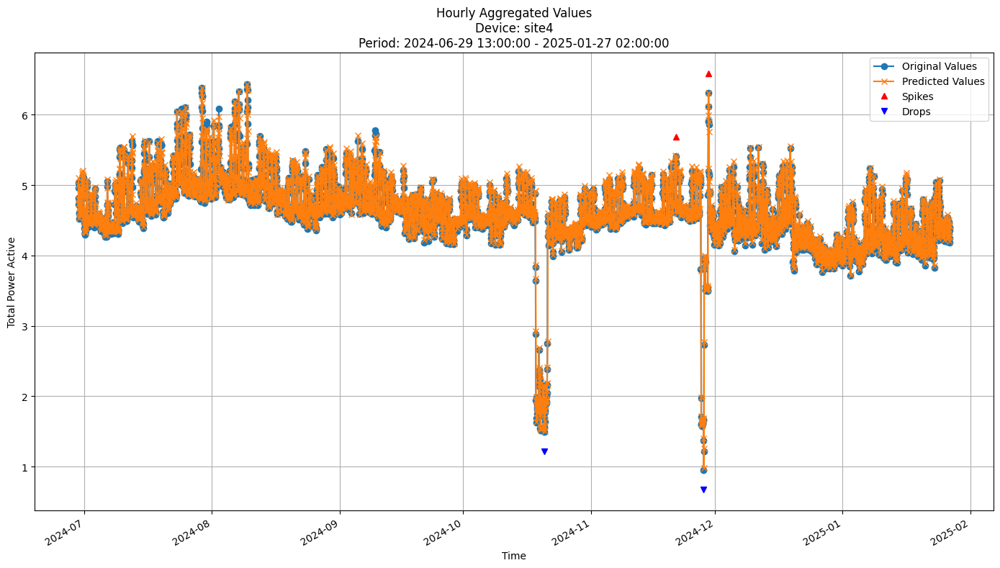


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1465
MAE: 0.0940
MAPE: 2.1086%

Directional Metrics:
Directional Accuracy: 45.1162%
First-Diff Correlation: 0.0343

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


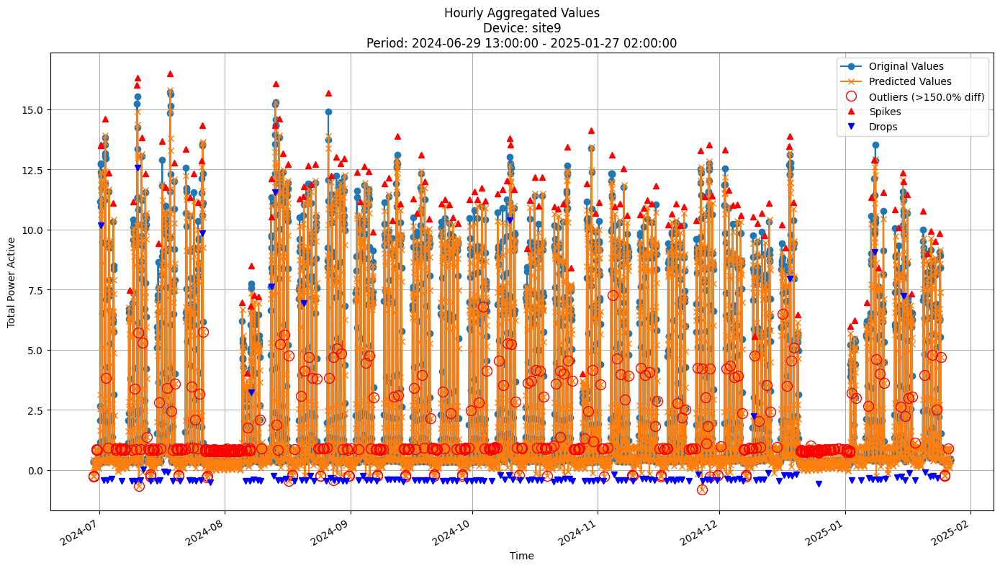


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2780
MAE: 0.6346
MAPE: 54.5918%

Directional Metrics:
Directional Accuracy: 49.6849%
First-Diff Correlation: 0.2967

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0746
  Recall: 0.0676
  F1 Score: 0.0709
Drops:
  Precision: 0.0150
  Recall: 0.0135
  F1 Score: 0.0142

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9403
  Recall: 0.8514
  F1 Score: 0.8936
Drops:
  Precision: 0.2556
  Recall: 0.2297
  F1 Score: 0.2420


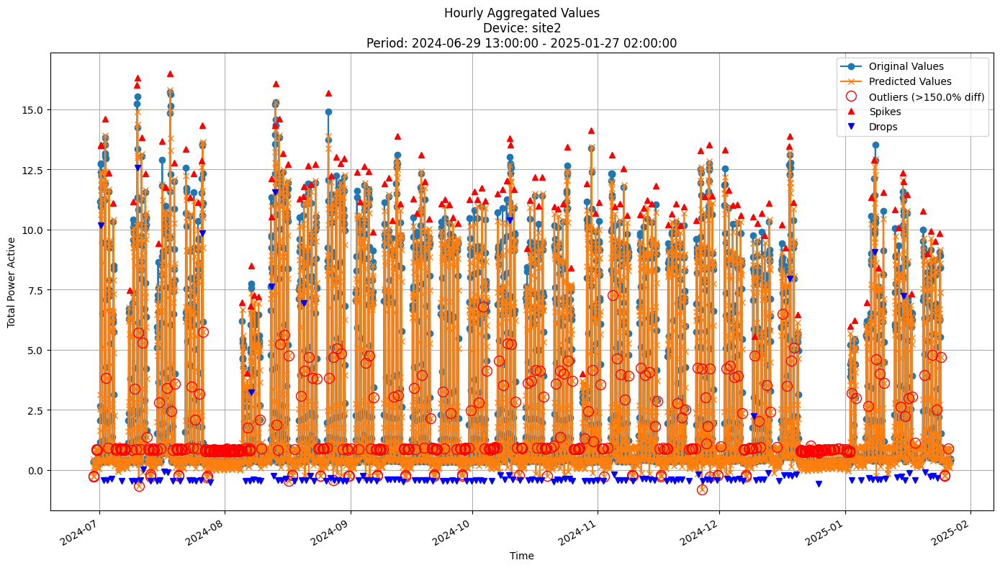


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2780
MAE: 0.6346
MAPE: 54.5918%

Directional Metrics:
Directional Accuracy: 49.6849%
First-Diff Correlation: 0.2967

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0746
  Recall: 0.0676
  F1 Score: 0.0709
Drops:
  Precision: 0.0150
  Recall: 0.0135
  F1 Score: 0.0142

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9403
  Recall: 0.8514
  F1 Score: 0.8936
Drops:
  Precision: 0.2556
  Recall: 0.2297
  F1 Score: 0.2420


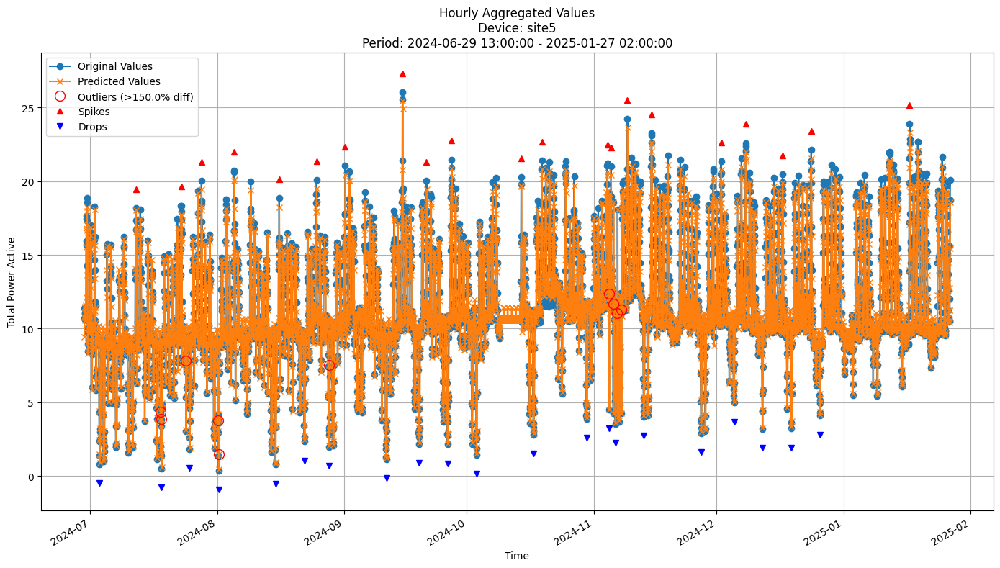


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3760
MAE: 0.8813
MAPE: 9.1169%

Directional Metrics:
Directional Accuracy: 59.6692%
First-Diff Correlation: 0.1465

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.8095
  F1 Score: 0.8947
Drops:
  Precision: 1.0000
  Recall: 0.8571
  F1 Score: 0.9231


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

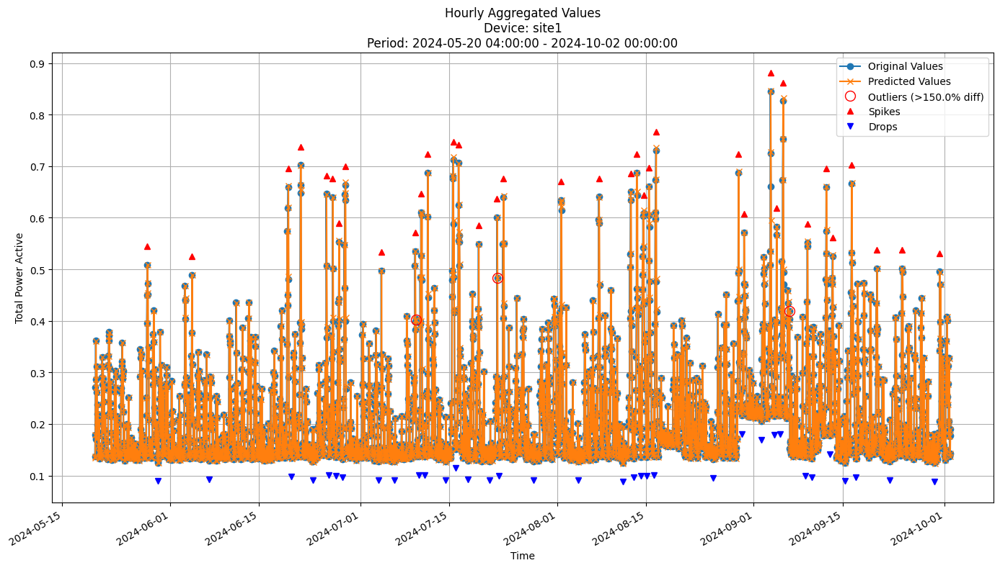


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0683
MAE: 0.0436
MAPE: 18.6467%

Directional Metrics:
Directional Accuracy: 42.3053%
First-Diff Correlation: -0.0929

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


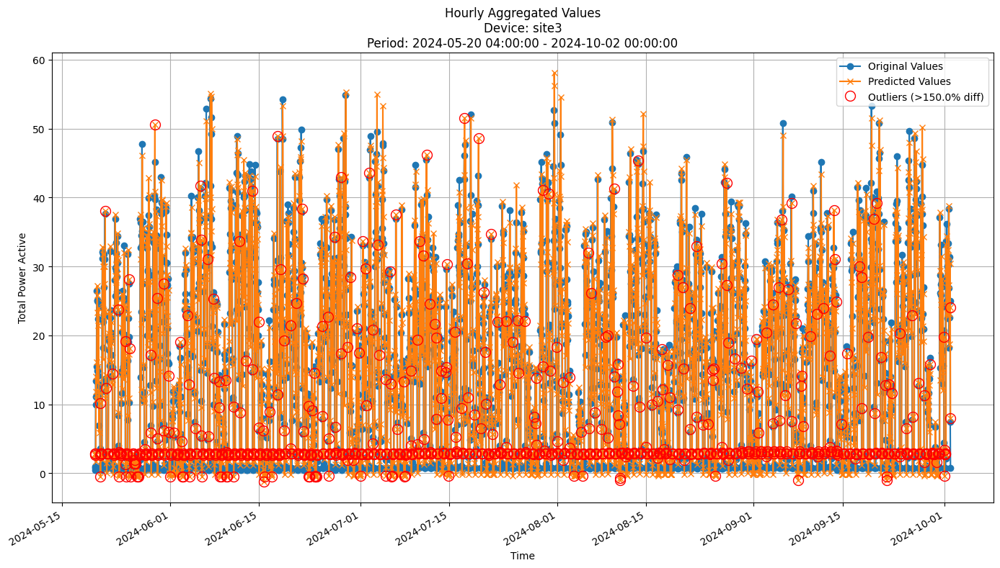


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.9750
MAE: 6.1820
MAPE: 129.1201%

Directional Metrics:
Directional Accuracy: 40.6057%
First-Diff Correlation: -0.1438

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


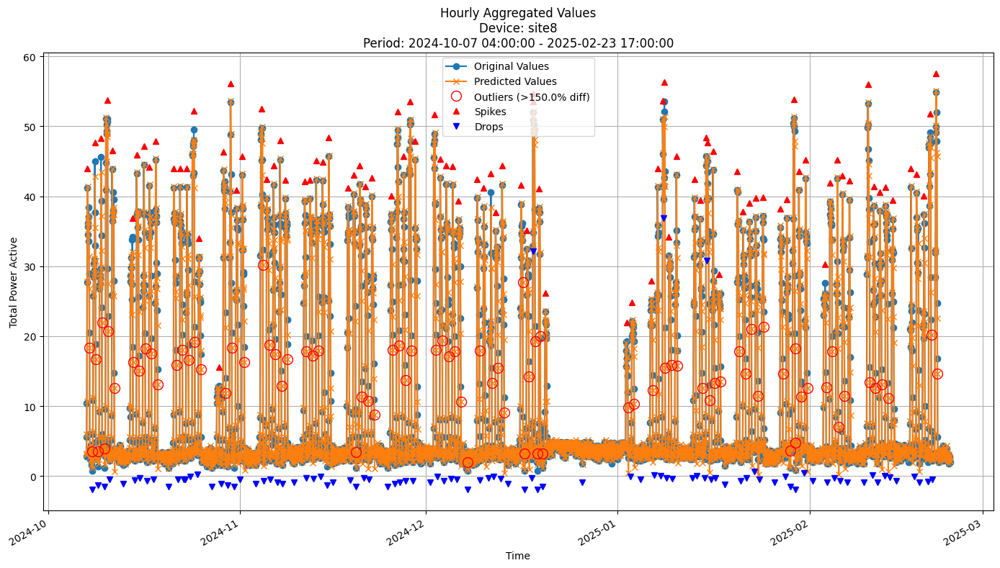


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.1840
MAE: 2.4323
MAPE: 29.7818%

Directional Metrics:
Directional Accuracy: 45.4030%
First-Diff Correlation: 0.2516

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0211
  Recall: 0.0211
  F1 Score: 0.0211
Drops:
  Precision: 0.0106
  Recall: 0.0105
  F1 Score: 0.0106

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9684
  Recall: 0.9684
  F1 Score: 0.9684
Drops:
  Precision: 0.5745
  Recall: 0.5684
  F1 Score: 0.5714


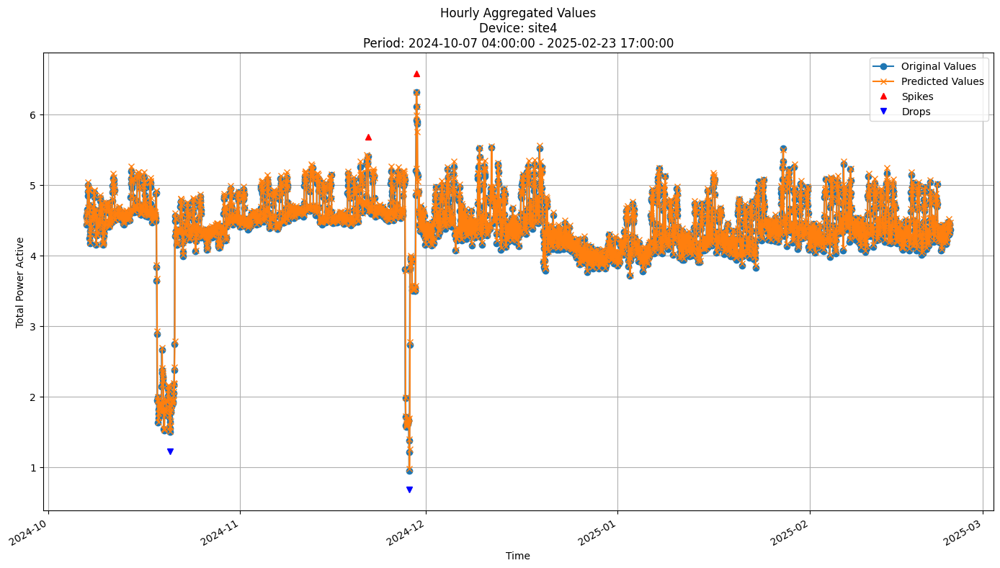


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1729
MAE: 0.1141
MAPE: 2.6681%

Directional Metrics:
Directional Accuracy: 39.6119%
First-Diff Correlation: -0.1063

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


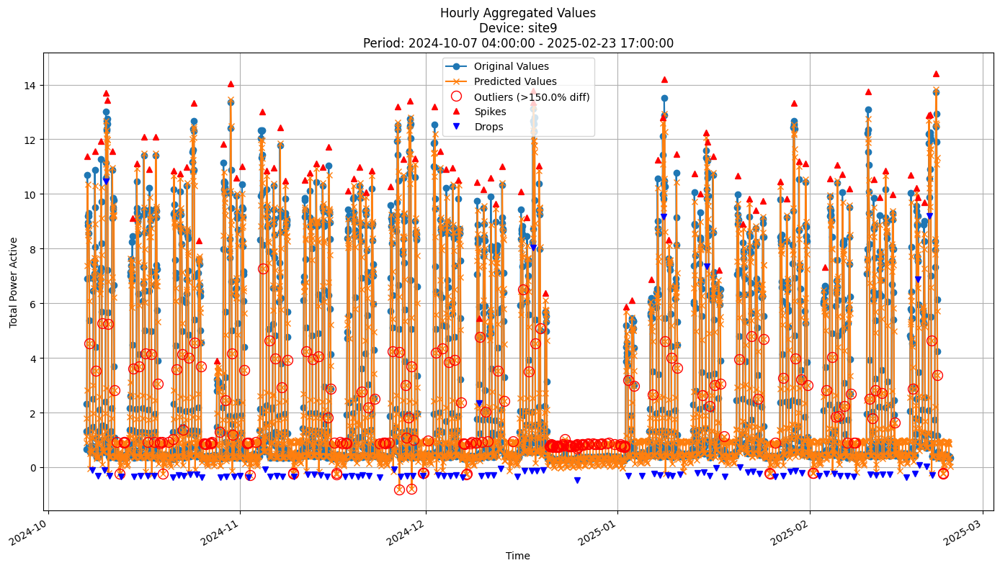


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2423
MAE: 0.6280
MAPE: 51.9627%

Directional Metrics:
Directional Accuracy: 48.1791%
First-Diff Correlation: 0.2778

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0505
  F1 Score: 0.0529
Drops:
  Precision: 0.0674
  Recall: 0.0612
  F1 Score: 0.0642

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9333
  Recall: 0.8485
  F1 Score: 0.8889
Drops:
  Precision: 0.3034
  Recall: 0.2755
  F1 Score: 0.2888


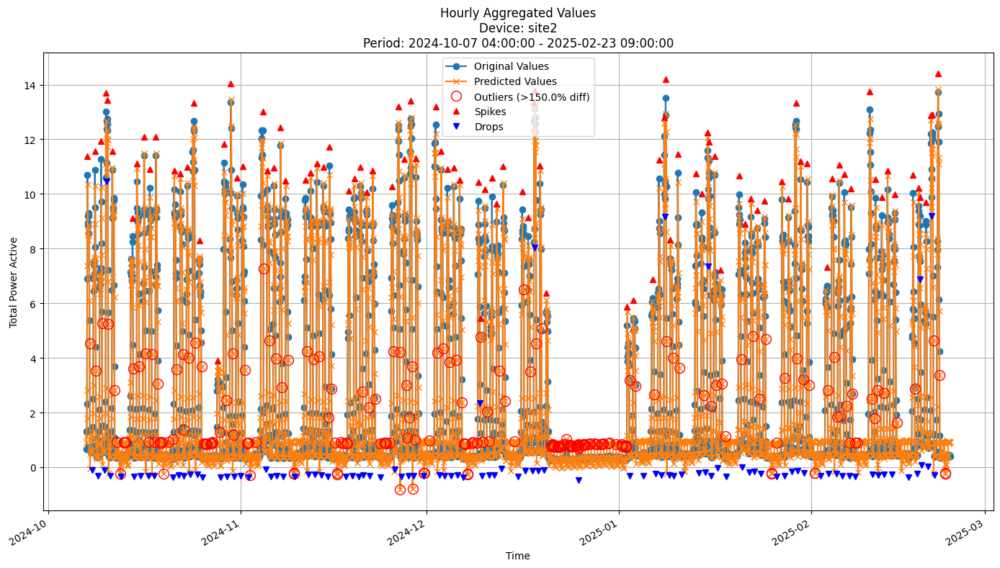


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2436
MAE: 0.6288
MAPE: 51.8994%

Directional Metrics:
Directional Accuracy: 48.2047%
First-Diff Correlation: 0.2779

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0505
  F1 Score: 0.0529
Drops:
  Precision: 0.0674
  Recall: 0.0612
  F1 Score: 0.0642

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9333
  Recall: 0.8485
  F1 Score: 0.8889
Drops:
  Precision: 0.3034
  Recall: 0.2755
  F1 Score: 0.2888


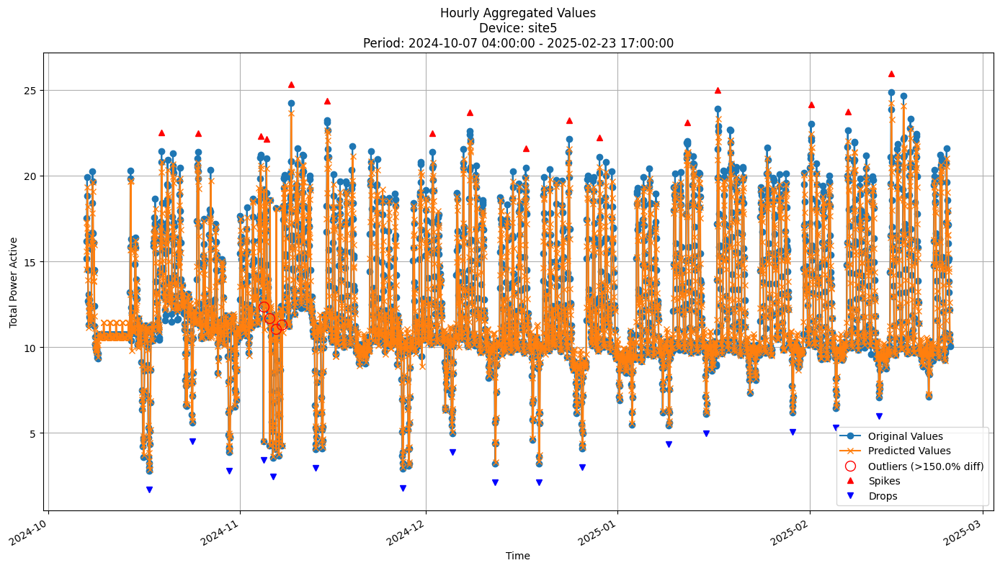


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3204
MAE: 0.8194
MAPE: 6.6555%

Directional Metrics:
Directional Accuracy: 62.4776%
First-Diff Correlation: 0.2168

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.7500
  F1 Score: 0.8571
Drops:
  Precision: 1.0000
  Recall: 0.7500
  F1 Score: 0.8571


In [49]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [ ]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 0.000313 MB
Metrics for Device: site8 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.9069
	MAE: 3.8430
	MAPE: 52.7435%

Directional Metrics:
	Directional Accuracy: 48.0916%
	First-Diff Correlation: 0.2555

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1447
		Recall: 0.2444
		F1: 0.1818
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.8444
		F1: 0.6281
	Drops:
		Precision: 0.1447
		Recall: 0.2500
		F1: 0.1833
--------------------------------------------------
Dai

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-02-23 19:00:00+01:00 to 2025-03-09 19:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-03-09 19:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-03-09 20:00:00+01:00 to 2025-03-23 20:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-03-23 20:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-03-23 21:00:00+01:00 to 2025-04-06 22:00:00+02:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-04-06 22:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2025-04-06 23:00:00+02:00 to 2025-04-20 23:00:00+02:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-04-20 23:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2025-04-21 0

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 605.282181 MB
Metrics for Device: site8 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8637
	MAE: 2.1359
	MAPE: 31.3249%

Directional Metrics:
	Directional Accuracy: 49.6183%
	First-Diff Correlation: 0.4508

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0408
		Recall: 0.0444
		F1: 0.0426
	Drops:
		Precision: 0.0208
		Recall: 0.0227
		F1: 0.0217

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7959
		Recall: 0.8667
		F1: 0.8298
	Drops:
		Precision: 0.4167
		Recall: 0.4545
		F1: 0.4348
--------------------------------------------------
D

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 0.200188 MB
Metrics for Device: site8 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.4926
	MAE: 2.7041
	MAPE: 33.8299%

Directional Metrics:
	Directional Accuracy: 46.7037%
	First-Diff Correlation: 0.3119

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0455
		Recall: 0.0444
		F1: 0.0449
	Drops:
		Precision: 0.0465
		Recall: 0.0455
		F1: 0.0460

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9778
		F1: 0.9888
	Drops:
		Precision: 0.6512
		Recall: 0.6364
		F1: 0.6437
--------------------------------------------------
Dai

In [51]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [52]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [53]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [54]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [55]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.132 ± 0.000,0.093 ± 0.000,20.687 ± 0.000,49.029 ± 0.000,-2.448 ± 0.000,3.636 ± 0.000,52.727 ± 0.000,18.182 ± 0.000,36.364 ± 0.000
1,BL_Mean,0.066 ± 0.000,0.047 ± 0.000,10.160 ± 0.000,59.195 ± 0.000,34.993 ± 0.000,16.667 ± 0.000,66.667 ± 0.000,20.339 ± 0.000,84.746 ± 0.000
2,GBDT,0.064 ± 0.000,0.045 ± 0.000,9.882 ± 0.000,59.452 ± 0.000,35.282 ± 0.000,15.873 ± 0.000,76.190 ± 0.000,19.355 ± 0.000,74.194 ± 0.000
3,RandomForest,0.065 ± 0.000,0.046 ± 0.000,9.914 ± 0.000,58.995 ± 0.000,34.692 ± 0.000,6.250 ± 0.000,75.000 ± 0.000,22.222 ± 0.000,76.190 ± 0.000
4,HoeffdingTree,0.074 ± 0.000,0.053 ± 0.000,11.241 ± 0.000,57.453 ± 0.000,23.095 ± 0.000,12.308 ± 0.000,80.000 ± 0.000,18.750 ± 0.000,81.250 ± 0.000
5,ARF_Hoeffding,0.073 ± 0.000,0.052 ± 0.000,11.300 ± 0.000,54.397 ± 0.000,14.820 ± 0.000,3.226 ± 0.000,74.194 ± 0.000,19.672 ± 0.000,75.410 ± 0.000
6,FastODT,0.085 ± 0.000,0.060 ± 0.000,13.338 ± 0.000,54.483 ± 0.000,17.529 ± 0.000,8.219 ± 0.000,68.493 ± 0.000,30.137 ± 0.000,68.493 ± 0.000
7,ARF_FastODT,0.076 ± 0.000,0.054 ± 0.000,11.569 ± 0.000,53.255 ± 0.000,7.665 ± 0.000,3.279 ± 0.000,75.410 ± 0.000,16.667 ± 0.000,70.000 ± 0.000
8,IncubationBoost,0.091 ± 0.000,0.064 ± 0.000,13.499 ± 0.000,49.629 ± 0.000,-3.532 ± 0.000,6.250 ± 0.000,90.625 ± 0.000,0.000 ± 0.000,93.750 ± 0.000




Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.689 ± 0.000,0.805 ± 0.000,39.820 ± 0.000,53.162 ± 0.000,27.656 ± 0.000,14.737 ± 0.000,64.211 ± 0.000,9.524 ± 0.000,33.862 ± 0.000
1,BL_Mean,0.788 ± 0.000,0.381 ± 0.000,22.887 ± 0.000,59.555 ± 0.000,67.017 ± 0.000,4.651 ± 0.000,79.070 ± 0.000,10.938 ± 0.000,57.812 ± 0.000
2,GBDT,0.753 ± 0.000,0.362 ± 0.000,17.991 ± 0.000,57.679 ± 0.000,66.736 ± 0.000,5.369 ± 0.000,72.483 ± 0.000,13.605 ± 0.000,38.095 ± 0.000
3,RandomForest,0.754 ± 0.000,0.359 ± 0.000,17.342 ± 0.000,58.999 ± 0.000,66.283 ± 0.000,5.674 ± 0.000,72.340 ± 0.000,12.857 ± 0.000,34.286 ± 0.000
4,HoeffdingTree,0.893 ± 0.000,0.434 ± 0.000,24.408 ± 0.000,55.316 ± 0.000,58.692 ± 0.000,9.655 ± 0.000,77.241 ± 0.000,9.722 ± 0.000,40.278 ± 0.000
5,ARF_Hoeffding,0.837 ± 0.000,0.417 ± 0.000,26.237 ± 0.000,58.235 ± 0.000,58.844 ± 0.000,5.357 ± 0.000,82.143 ± 0.000,7.273 ± 0.000,34.545 ± 0.000
6,FastODT,1.321 ± 0.000,0.645 ± 0.000,39.024 ± 0.000,52.953 ± 0.000,27.268 ± 0.000,11.613 ± 0.000,69.677 ± 0.000,5.195 ± 0.000,44.156 ± 0.000
7,ARF_FastODT,0.818 ± 0.000,0.406 ± 0.000,21.933 ± 0.000,57.331 ± 0.000,57.531 ± 0.000,8.264 ± 0.000,80.992 ± 0.000,10.000 ± 0.000,38.333 ± 0.000
8,IncubationBoost,1.308 ± 0.000,0.670 ± 0.000,50.292 ± 0.000,53.718 ± 0.000,33.206 ± 0.000,3.846 ± 0.000,78.846 ± 0.000,5.825 ± 0.000,27.184 ± 0.000




Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,12.933 ± 0.000,8.588 ± 0.000,106.488 ± 0.000,47.030 ± 0.000,-2.998 ± 0.000,7.673 ± 0.000,36.829 ± 0.000,12.346 ± 0.000,22.222 ± 0.000
1,BL_Mean,6.696 ± 0.000,4.441 ± 0.000,56.571 ± 0.000,51.628 ± 0.000,26.910 ± 0.000,7.092 ± 0.000,45.390 ± 0.000,15.484 ± 0.000,38.710 ± 0.000
2,GBDT,6.519 ± 0.000,4.179 ± 0.000,43.167 ± 0.000,51.256 ± 0.000,29.628 ± 0.000,6.803 ± 0.000,46.259 ± 0.000,18.634 ± 0.000,45.963 ± 0.000
3,RandomForest,6.557 ± 0.000,4.184 ± 0.000,40.517 ± 0.000,52.142 ± 0.000,29.631 ± 0.000,5.405 ± 0.000,45.946 ± 0.000,14.815 ± 0.000,44.444 ± 0.000
4,HoeffdingTree,7.602 ± 0.000,4.921 ± 0.000,50.999 ± 0.000,49.372 ± 0.000,15.179 ± 0.000,6.369 ± 0.000,47.134 ± 0.000,19.883 ± 0.000,43.275 ± 0.000
5,ARF_Hoeffding,7.391 ± 0.000,4.946 ± 0.000,59.013 ± 0.000,49.829 ± 0.000,4.999 ± 0.000,5.128 ± 0.000,65.385 ± 0.000,23.529 ± 0.000,54.118 ± 0.000
6,FastODT,8.433 ± 0.000,5.392 ± 0.000,53.099 ± 0.000,48.287 ± 0.000,6.593 ± 0.000,5.063 ± 0.000,51.899 ± 0.000,22.093 ± 0.000,43.023 ± 0.000
7,ARF_FastODT,7.080 ± 0.000,4.749 ± 0.000,53.150 ± 0.000,51.171 ± 0.000,8.637 ± 0.000,6.623 ± 0.000,52.980 ± 0.000,23.030 ± 0.000,46.061 ± 0.000
8,IncubationBoost,8.921 ± 0.000,5.826 ± 0.000,81.452 ± 0.000,42.519 ± 0.000,-8.534 ± 0.000,3.593 ± 0.000,61.078 ± 0.000,17.989 ± 0.000,68.783 ± 0.000


... (4 outputs left out)



Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,6.907 ± 0.000,3.843 ± 0.000,52.744 ± 0.000,48.092 ± 0.000,25.545 ± 0.000,18.182 ± 0.000,62.810 ± 0.000,0.000 ± 0.000,18.333 ± 0.000
1,BL_Mean,3.358 ± 0.000,1.899 ± 0.000,29.345 ± 0.000,50.520 ± 0.000,61.800 ± 0.000,2.083 ± 0.000,83.333 ± 0.000,4.255 ± 0.000,53.191 ± 0.000
2,GBDT,3.368 ± 0.000,1.874 ± 0.000,27.523 ± 0.000,49.063 ± 0.000,59.613 ± 0.000,8.081 ± 0.000,76.768 ± 0.000,2.062 ± 0.000,49.485 ± 0.000
3,RandomForest,3.356 ± 0.000,1.869 ± 0.000,27.574 ± 0.000,48.161 ± 0.000,59.271 ± 0.000,8.247 ± 0.000,78.351 ± 0.000,2.105 ± 0.000,50.526 ± 0.000
4,HoeffdingTree,4.127 ± 0.000,2.370 ± 0.000,36.576 ± 0.000,49.480 ± 0.000,50.083 ± 0.000,3.571 ± 0.000,66.071 ± 0.000,3.636 ± 0.000,20.000 ± 0.000
5,ARF_Hoeffding,4.131 ± 0.000,2.284 ± 0.000,34.740 ± 0.000,49.133 ± 0.000,45.819 ± 0.000,2.174 ± 0.000,80.435 ± 0.000,2.222 ± 0.000,46.667 ± 0.000
6,FastODT,4.533 ± 0.000,2.553 ± 0.000,41.121 ± 0.000,48.230 ± 0.000,46.735 ± 0.000,12.069 ± 0.000,63.793 ± 0.000,3.509 ± 0.000,43.860 ± 0.000
7,ARF_FastODT,3.864 ± 0.000,2.136 ± 0.000,31.325 ± 0.000,49.618 ± 0.000,45.083 ± 0.000,4.255 ± 0.000,82.979 ± 0.000,2.174 ± 0.000,43.478 ± 0.000
8,IncubationBoost,5.493 ± 0.000,2.704 ± 0.000,33.830 ± 0.000,46.704 ± 0.000,31.189 ± 0.000,4.494 ± 0.000,98.876 ± 0.000,4.598 ± 0.000,64.368 ± 0.000




Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.697 ± 0.000,0.814 ± 0.000,40.349 ± 0.000,53.366 ± 0.000,27.687 ± 0.000,14.583 ± 0.000,63.542 ± 0.000,9.474 ± 0.000,32.632 ± 0.000
1,BL_Mean,0.791 ± 0.000,0.384 ± 0.000,23.014 ± 0.000,59.750 ± 0.000,67.199 ± 0.000,4.651 ± 0.000,79.070 ± 0.000,11.024 ± 0.000,58.268 ± 0.000
2,GBDT,0.757 ± 0.000,0.367 ± 0.000,18.317 ± 0.000,58.293 ± 0.000,66.432 ± 0.000,4.167 ± 0.000,66.667 ± 0.000,11.268 ± 0.000,35.211 ± 0.000
3,RandomForest,0.754 ± 0.000,0.360 ± 0.000,17.438 ± 0.000,59.403 ± 0.000,66.714 ± 0.000,7.042 ± 0.000,71.831 ± 0.000,12.857 ± 0.000,35.714 ± 0.000
4,HoeffdingTree,0.895 ± 0.000,0.437 ± 0.000,24.560 ± 0.000,55.378 ± 0.000,58.986 ± 0.000,9.655 ± 0.000,77.241 ± 0.000,9.722 ± 0.000,40.278 ± 0.000
5,ARF_Hoeffding,0.839 ± 0.000,0.420 ± 0.000,26.363 ± 0.000,58.432 ± 0.000,59.084 ± 0.000,5.405 ± 0.000,82.883 ± 0.000,9.174 ± 0.000,34.862 ± 0.000
6,FastODT,1.323 ± 0.000,0.648 ± 0.000,39.238 ± 0.000,53.158 ± 0.000,27.750 ± 0.000,10.596 ± 0.000,70.199 ± 0.000,5.369 ± 0.000,42.953 ± 0.000
7,ARF_FastODT,0.859 ± 0.000,0.432 ± 0.000,23.020 ± 0.000,58.015 ± 0.000,52.546 ± 0.000,10.084 ± 0.000,80.672 ± 0.000,8.547 ± 0.000,41.026 ± 0.000
8,IncubationBoost,1.315 ± 0.000,0.675 ± 0.000,50.308 ± 0.000,53.921 ± 0.000,33.382 ± 0.000,3.846 ± 0.000,80.769 ± 0.000,5.882 ± 0.000,27.451 ± 0.000


## Validation results

In [56]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.106 ± 0.009,0.073 ± 0.008,29.072 ± 4.502,48.442 ± 2.537,-3.367 ± 6.313,12.099 ± 4.301,67.076 ± 11.277,12.673 ± 7.037,39.335 ± 15.632
1,BL_Mean,0.057 ± 0.009,0.038 ± 0.007,14.981 ± 2.990,56.936 ± 3.574,38.650 ± 9.076,25.244 ± 11.996,66.754 ± 13.495,12.796 ± 9.302,47.360 ± 14.136
2,GBDT,0.055 ± 0.010,0.037 ± 0.008,14.044 ± 2.206,55.673 ± 4.106,35.234 ± 8.962,26.066 ± 8.707,71.031 ± 8.972,13.845 ± 8.584,44.643 ± 9.733
3,RandomForest,0.055 ± 0.010,0.037 ± 0.008,14.105 ± 2.054,54.970 ± 3.731,33.200 ± 7.629,25.128 ± 10.616,70.646 ± 9.573,11.380 ± 8.231,43.800 ± 9.495
4,HoeffdingTree,0.058 ± 0.012,0.039 ± 0.010,14.938 ± 2.450,54.646 ± 2.741,32.537 ± 10.416,24.201 ± 10.863,69.406 ± 10.034,13.153 ± 9.173,46.788 ± 12.440
5,ARF_Hoeffding,0.059 ± 0.009,0.039 ± 0.007,15.178 ± 2.359,51.141 ± 4.123,13.748 ± 8.181,12.146 ± 9.209,79.693 ± 8.913,10.767 ± 11.110,57.307 ± 14.014
6,FastODT,0.069 ± 0.010,0.047 ± 0.008,18.350 ± 2.532,49.924 ± 2.452,15.081 ± 8.231,16.422 ± 9.481,71.683 ± 6.924,7.496 ± 4.386,39.811 ± 12.769
7,ARF_FastODT,0.060 ± 0.010,0.040 ± 0.008,15.393 ± 2.043,51.955 ± 3.557,9.554 ± 6.034,14.221 ± 8.939,77.899 ± 8.406,12.955 ± 9.592,52.863 ± 13.805
8,IncubationBoost,0.072 ± 0.009,0.047 ± 0.008,17.670 ± 2.175,44.671 ± 3.495,-9.722 ± 9.630,0.556 ± 2.422,96.445 ± 4.444,0.000 ± 0.000,96.257 ± 7.526




Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.665 ± 0.143,0.757 ± 0.099,37.906 ± 4.881,49.294 ± 5.720,23.167 ± 2.419,13.034 ± 4.103,65.005 ± 4.776,7.059 ± 3.073,32.062 ± 7.923
1,BL_Mean,0.865 ± 0.131,0.418 ± 0.063,33.019 ± 21.248,50.568 ± 5.618,62.605 ± 8.324,6.797 ± 5.353,67.059 ± 8.892,6.817 ± 3.929,36.354 ± 7.216
2,GBDT,0.815 ± 0.100,0.388 ± 0.038,23.026 ± 7.256,52.196 ± 4.598,62.067 ± 9.932,6.065 ± 3.657,62.433 ± 9.945,5.020 ± 4.814,29.800 ± 9.113
3,RandomForest,0.793 ± 0.091,0.378 ± 0.042,22.612 ± 8.388,52.901 ± 3.680,61.910 ± 11.154,8.050 ± 3.299,65.119 ± 7.546,5.575 ± 6.719,32.571 ± 9.793
4,HoeffdingTree,1.045 ± 0.122,0.504 ± 0.071,34.843 ± 15.316,49.989 ± 4.288,43.176 ± 9.108,9.853 ± 4.776,69.306 ± 10.468,5.339 ± 4.629,27.080 ± 8.909
5,ARF_Hoeffding,0.876 ± 0.063,0.426 ± 0.039,28.106 ± 4.467,52.571 ± 4.912,51.376 ± 6.783,8.344 ± 3.504,76.704 ± 11.339,6.209 ± 8.653,29.260 ± 13.648
6,FastODT,1.338 ± 0.132,0.656 ± 0.100,40.314 ± 5.631,49.596 ± 4.861,26.776 ± 3.932,7.337 ± 2.568,63.632 ± 6.775,6.035 ± 3.455,39.237 ± 5.847
7,ARF_FastODT,0.858 ± 0.065,0.421 ± 0.033,26.067 ± 4.510,52.905 ± 4.243,52.389 ± 8.528,8.620 ± 4.686,71.414 ± 9.961,4.878 ± 5.125,27.049 ± 8.790
8,IncubationBoost,1.292 ± 0.128,0.640 ± 0.062,50.727 ± 5.496,50.078 ± 5.017,28.528 ± 3.304,6.008 ± 4.154,79.081 ± 7.440,4.388 ± 5.573,31.852 ± 9.847




Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,13.500 ± 1.313,9.109 ± 1.185,137.050 ± 28.864,44.788 ± 3.381,-6.342 ± 5.008,6.158 ± 3.618,33.656 ± 17.127,7.435 ± 3.789,20.912 ± 11.282
1,BL_Mean,7.015 ± 0.637,4.707 ± 0.544,79.356 ± 23.233,48.284 ± 2.993,23.043 ± 8.652,8.547 ± 6.258,61.135 ± 10.815,8.547 ± 6.953,24.181 ± 11.167
2,GBDT,7.026 ± 0.727,4.620 ± 0.615,62.160 ± 11.028,47.604 ± 3.407,20.197 ± 9.278,9.844 ± 9.564,60.649 ± 11.425,9.115 ± 6.538,28.873 ± 13.181
3,RandomForest,7.042 ± 0.695,4.591 ± 0.594,58.132 ± 11.148,46.765 ± 3.395,19.066 ± 9.370,10.838 ± 8.130,61.440 ± 14.801,6.725 ± 5.967,26.352 ± 14.787
4,HoeffdingTree,7.951 ± 0.782,5.244 ± 0.693,73.211 ± 13.517,45.270 ± 3.244,7.314 ± 8.575,8.045 ± 7.216,62.258 ± 14.548,8.715 ± 5.257,27.995 ± 15.677
5,ARF_Hoeffding,7.668 ± 0.703,5.174 ± 0.559,80.807 ± 16.220,45.499 ± 3.218,0.898 ± 6.773,8.058 ± 10.164,76.404 ± 9.238,13.662 ± 11.253,33.330 ± 14.876
6,FastODT,9.099 ± 0.917,5.954 ± 0.768,77.525 ± 15.371,44.856 ± 2.758,-0.447 ± 6.660,9.092 ± 7.605,53.662 ± 15.241,9.462 ± 6.785,30.032 ± 12.422
7,ARF_FastODT,7.464 ± 0.815,4.991 ± 0.668,70.192 ± 11.391,45.946 ± 3.353,3.488 ± 7.482,8.943 ± 10.324,63.841 ± 15.543,10.902 ± 5.789,29.575 ± 12.986
8,IncubationBoost,9.104 ± 0.795,6.201 ± 0.681,118.519 ± 23.822,40.050 ± 3.095,-12.823 ± 4.863,1.557 ± 3.294,70.367 ± 18.022,12.591 ± 10.774,57.667 ± 11.926


... (4 outputs left out)



Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,6.775 ± 0.549,3.576 ± 0.327,46.974 ± 3.121,47.618 ± 2.919,21.351 ± 2.543,14.165 ± 5.630,65.004 ± 5.675,3.175 ± 3.215,16.797 ± 7.175
1,BL_Mean,3.578 ± 0.551,1.987 ± 0.300,30.057 ± 9.136,49.353 ± 3.160,59.280 ± 9.145,6.569 ± 4.006,76.506 ± 13.567,2.543 ± 2.914,33.812 ± 7.952
2,GBDT,3.407 ± 0.288,1.882 ± 0.146,26.523 ± 4.545,49.038 ± 3.251,57.285 ± 9.821,7.906 ± 5.928,70.599 ± 9.651,1.871 ± 2.684,41.203 ± 3.161
3,RandomForest,3.368 ± 0.323,1.858 ± 0.165,26.463 ± 4.819,48.611 ± 2.966,57.271 ± 10.083,7.913 ± 5.937,71.700 ± 8.204,1.915 ± 2.742,42.801 ± 5.110
4,HoeffdingTree,4.766 ± 0.341,2.634 ± 0.223,39.256 ± 7.507,49.055 ± 1.899,32.575 ± 6.677,7.376 ± 7.059,67.500 ± 6.942,5.335 ± 1.916,34.246 ± 8.379
5,ARF_Hoeffding,3.978 ± 0.317,2.181 ± 0.172,32.154 ± 5.103,48.982 ± 1.858,43.335 ± 5.856,8.943 ± 3.889,84.086 ± 8.403,2.839 ± 3.101,47.189 ± 9.964
6,FastODT,4.392 ± 0.386,2.419 ± 0.245,37.712 ± 3.969,48.215 ± 2.688,46.988 ± 9.015,5.467 ± 3.795,66.565 ± 4.854,1.749 ± 2.437,25.945 ± 7.250
7,ARF_FastODT,3.683 ± 0.304,2.060 ± 0.139,30.162 ± 4.480,49.076 ± 2.543,45.890 ± 10.355,8.599 ± 5.349,77.119 ± 9.578,2.227 ± 3.271,34.603 ± 9.870
8,IncubationBoost,5.253 ± 0.524,2.500 ± 0.287,31.137 ± 3.088,46.460 ± 3.205,27.243 ± 3.821,2.145 ± 3.058,93.194 ± 8.269,0.510 ± 1.350,55.472 ± 15.620




Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.663 ± 0.142,0.756 ± 0.098,37.877 ± 4.895,49.289 ± 5.716,23.167 ± 2.419,13.246 ± 4.061,65.526 ± 3.803,7.007 ± 3.038,32.714 ± 8.149
1,BL_Mean,0.864 ± 0.132,0.418 ± 0.063,33.009 ± 21.256,50.541 ± 5.592,62.605 ± 8.324,6.715 ± 5.253,67.032 ± 8.880,6.729 ± 3.771,36.486 ± 7.391
2,GBDT,0.814 ± 0.100,0.388 ± 0.038,23.050 ± 7.256,52.221 ± 4.462,62.065 ± 9.958,6.327 ± 4.186,62.254 ± 9.720,5.280 ± 5.311,29.833 ± 9.068
3,RandomForest,0.793 ± 0.091,0.377 ± 0.042,22.603 ± 8.396,52.853 ± 3.663,61.911 ± 11.155,7.974 ± 3.264,64.615 ± 7.633,5.414 ± 6.368,32.168 ± 9.072
4,HoeffdingTree,1.045 ± 0.123,0.503 ± 0.072,34.823 ± 15.332,49.981 ± 4.277,43.176 ± 9.108,9.812 ± 4.804,69.258 ± 10.445,5.254 ± 4.477,27.278 ± 9.087
5,ARF_Hoeffding,0.876 ± 0.063,0.426 ± 0.039,28.088 ± 4.482,52.520 ± 4.848,51.375 ± 6.783,8.252 ± 3.402,76.030 ± 10.563,6.009 ± 8.199,28.861 ± 13.004
6,FastODT,1.337 ± 0.132,0.655 ± 0.100,40.273 ± 5.659,49.589 ± 4.853,26.776 ± 3.932,7.296 ± 2.556,63.966 ± 6.935,5.978 ± 3.371,39.699 ± 6.202
7,ARF_FastODT,0.852 ± 0.070,0.423 ± 0.030,26.451 ± 4.609,52.703 ± 4.139,52.756 ± 9.253,9.287 ± 4.121,69.596 ± 8.288,3.908 ± 4.448,26.820 ± 5.111
8,IncubationBoost,1.291 ± 0.128,0.640 ± 0.062,50.774 ± 5.467,50.053 ± 4.997,28.527 ± 3.304,5.908 ± 3.990,78.448 ± 7.327,4.243 ± 5.216,31.526 ± 9.581


### By-period validation results

In [57]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [58]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: site1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,50.820,63.785,64.232,62.146,60.060,58.867,52.906,55.887,49.627,57.592222
Period 2,48.286,59.762,56.930,56.036,53.651,53.204,48.435,51.118,41.729,52.127889
Period 3,49.776,59.165,57.526,57.079,57.973,55.142,49.925,57.973,42.474,54.114778
Period 4,52.310,60.209,60.656,60.656,56.930,55.589,51.565,58.867,44.113,55.655000
Period 5,46.945,58.122,55.440,55.440,56.185,53.800,50.224,52.608,44.411,52.575000
Period 6,49.478,58.122,54.247,53.502,54.396,49.627,52.608,52.906,41.580,51.829556
Period 7,46.647,59.613,57.526,56.483,57.973,51.565,51.118,53.651,43.815,53.154556
Period 8,46.647,56.781,55.589,54.993,54.098,49.925,50.671,50.373,40.686,51.084778
Period 9,46.796,57.079,56.185,54.844,56.930,53.055,50.224,51.267,47.690,52.674444
Period 10,45.306,56.483,55.440,54.247,52.906,50.373,49.627,48.733,47.392,51.167444



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-2.534,-4.023,-7.302,-6.110,-6.409,-5.663,-4.471,-4.769,-7.898,-5.464
Period 3 - Period 2,1.490,-0.597,0.596,1.043,4.322,1.938,1.490,6.855,0.745,1.987
Period 4 - Period 3,2.534,1.044,3.130,3.577,-1.043,0.447,1.640,0.894,1.639,1.540
Period 5 - Period 4,-5.365,-2.087,-5.216,-5.216,-0.745,-1.789,-1.341,-6.259,0.298,-3.080
Period 6 - Period 5,2.533,0.000,-1.193,-1.938,-1.789,-4.173,2.384,0.298,-2.831,-0.745
Period 7 - Period 6,-2.831,1.491,3.279,2.981,3.577,1.938,-1.490,0.745,2.235,1.325
Period 8 - Period 7,0.000,-2.832,-1.937,-1.490,-3.875,-1.640,-0.447,-3.278,-3.129,-2.070
Period 9 - Period 8,0.149,0.298,0.596,-0.149,2.832,3.130,-0.447,0.894,7.004,1.590
Period 10 - Period 9,-1.490,-0.596,-0.745,-0.597,-4.024,-2.682,-0.597,-2.534,-0.298,-1.507
Period 11 - Period 10,5.812,6.408,5.663,6.260,3.130,7.749,4.620,7.452,6.557,5.961



Device: site2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,52.012,53.204,51.416,52.161,49.329,50.522,50.224,52.459,50.820,51.349667
Period 2,57.079,58.420,57.526,58.569,56.334,59.165,56.185,57.675,56.930,57.542556
Period 3,50.224,46.945,50.820,51.863,49.627,49.627,50.224,49.627,51.714,50.074556
Period 4,51.565,50.373,55.291,54.247,49.925,53.353,50.671,56.334,51.416,52.575000
Period 5,39.195,42.027,46.200,49.180,43.070,50.075,43.517,49.180,44.411,45.206111
Period 6,41.133,43.219,44.709,46.647,44.858,43.517,40.686,45.604,40.089,43.384667
Period 7,49.478,54.396,53.502,53.204,51.267,55.440,50.522,53.949,51.118,52.541778
Period 8,53.670,55.963,58.104,57.339,55.505,58.869,54.740,58.410,54.128,56.303111


... (18 outputs left out)


Device: site9 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,52.012,53.204,51.416,52.161,49.329,50.522,50.224,49.329,50.820,51.001889
Period 2,57.079,58.420,57.526,58.569,56.334,59.165,56.185,59.165,56.930,57.708111
Period 3,50.224,46.945,50.820,51.863,49.627,49.627,50.224,50.522,51.714,50.174000
Period 4,51.565,50.373,55.291,54.247,49.925,53.353,50.671,56.334,51.416,52.575000
Period 5,39.195,42.027,45.902,49.031,43.070,50.075,43.517,48.435,44.411,45.073667
Period 6,41.133,43.219,45.455,46.647,44.858,43.517,40.686,47.243,40.089,43.649667
Period 7,49.478,54.396,53.502,53.204,51.267,55.440,50.522,53.800,51.118,52.525222
Period 8,53.625,55.740,57.855,57.100,55.438,58.459,54.683,56.798,53.927,55.958333



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.067,5.216,6.110,6.408,7.005,8.643,5.961,9.836,6.110,6.706
Period 3 - Period 2,-6.855,-11.475,-6.706,-6.706,-6.707,-9.538,-5.961,-8.643,-5.216,-7.534
Period 4 - Period 3,1.341,3.428,4.471,2.384,0.298,3.726,0.447,5.812,-0.298,2.401
Period 5 - Period 4,-12.370,-8.346,-9.389,-5.216,-6.855,-3.278,-7.154,-7.899,-7.005,-7.501
Period 6 - Period 5,1.938,1.192,-0.447,-2.384,1.788,-6.558,-2.831,-1.192,-4.322,-1.424
Period 7 - Period 6,8.345,11.177,8.047,6.557,6.409,11.923,9.836,6.557,11.029,8.876
Period 8 - Period 7,4.147,1.344,4.353,3.896,4.171,3.019,4.161,2.998,2.809,3.433


#### MAPE (lower is better)

In [59]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: site1 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,30.039,18.504,16.028,15.888,16.316,16.340,19.850,17.313,18.892,18.796667
Period 2,31.668,17.602,13.385,13.408,13.996,14.712,17.387,15.472,18.155,17.309444
Period 3,34.349,16.240,13.229,13.194,14.060,15.271,17.856,15.392,19.102,17.632556
Period 4,32.297,15.636,13.161,13.297,14.211,15.034,19.056,15.355,18.628,17.408333
Period 5,31.082,13.466,12.528,12.525,12.668,13.404,17.015,14.501,17.993,16.131333
Period 6,30.008,14.316,13.809,13.966,14.580,13.996,17.848,14.473,17.378,16.708222
Period 7,31.396,12.755,13.423,13.830,13.934,14.570,18.666,15.513,17.968,16.895000
Period 8,28.376,12.174,12.718,12.765,13.808,13.293,17.705,14.013,17.118,15.774444
Period 9,20.531,10.620,11.621,11.470,12.183,11.296,14.760,12.144,13.446,13.119000
Period 10,28.087,22.447,20.895,19.641,22.425,19.626,22.159,18.730,18.069,21.342111



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,1.629,-0.902,-2.643,-2.480,-2.320,-1.628,-2.463,-1.841,-0.737,-1.487
Period 3 - Period 2,2.681,-1.362,-0.156,-0.214,0.064,0.559,0.469,-0.080,0.947,0.323
Period 4 - Period 3,-2.052,-0.604,-0.068,0.103,0.151,-0.237,1.200,-0.037,-0.474,-0.224
Period 5 - Period 4,-1.215,-2.170,-0.633,-0.772,-1.543,-1.630,-2.041,-0.854,-0.635,-1.277
Period 6 - Period 5,-1.074,0.850,1.281,1.441,1.912,0.592,0.833,-0.028,-0.615,0.577
Period 7 - Period 6,1.388,-1.561,-0.386,-0.136,-0.646,0.574,0.818,1.040,0.590,0.187
Period 8 - Period 7,-3.020,-0.581,-0.705,-1.065,-0.126,-1.277,-0.961,-1.500,-0.850,-1.121
Period 9 - Period 8,-7.845,-1.554,-1.097,-1.295,-1.625,-1.997,-2.945,-1.869,-3.672,-2.655
Period 10 - Period 9,7.556,11.827,9.274,8.171,10.242,8.330,7.399,6.586,4.623,8.223
Period 11 - Period 10,-14.412,-14.586,-11.759,-10.655,-12.827,-11.318,-12.337,-9.928,-7.988,-11.757



Device: site2 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,32.513,73.411,39.287,42.928,72.776,38.674,43.072,35.374,53.732,47.974111
Period 2,35.700,16.038,16.608,15.688,38.403,25.645,45.203,22.679,42.562,28.725111
Period 3,40.484,16.745,18.259,17.715,36.453,24.463,45.372,20.252,50.146,29.987667
Period 4,42.856,19.204,18.592,19.210,24.589,25.156,38.569,22.485,49.741,28.933556
Period 5,47.234,21.544,20.706,19.311,24.488,27.643,47.354,29.208,48.701,31.798778
Period 6,36.509,61.524,28.011,26.076,31.962,29.005,36.875,26.191,62.881,37.670444
Period 7,32.295,38.765,25.703,23.854,27.216,30.043,29.420,28.186,50.903,31.820556
Period 8,35.660,16.923,17.045,16.111,22.858,24.217,36.645,24.159,47.150,26.752000


... (18 outputs left out)


Device: site9 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,32.513,73.411,39.287,42.928,72.776,38.674,43.072,36.201,53.732,48.066000
Period 2,35.700,16.038,16.608,15.688,38.403,25.645,45.203,23.007,42.562,28.761556
Period 3,40.484,16.745,18.259,17.715,36.453,24.463,45.372,20.971,50.146,30.067556
Period 4,42.856,19.204,18.592,19.210,24.589,25.156,38.569,23.216,49.741,29.014778
Period 5,47.234,21.544,20.717,19.312,24.488,27.643,47.354,26.730,48.701,31.524778
Period 6,36.509,61.524,28.107,26.076,31.962,29.005,36.875,26.878,62.881,37.757444
Period 7,32.295,38.765,25.703,23.861,27.216,30.043,29.420,30.527,50.903,32.081444
Period 8,35.429,16.843,17.126,16.034,22.696,24.075,36.319,24.073,47.527,26.680222



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,3.187,-57.373,-22.679,-27.240,-34.373,-13.029,2.131,-13.194,-11.170,-19.304
Period 3 - Period 2,4.784,0.707,1.651,2.027,-1.950,-1.182,0.169,-2.036,7.584,1.306
Period 4 - Period 3,2.372,2.459,0.333,1.495,-11.864,0.693,-6.803,2.245,-0.405,-1.053
Period 5 - Period 4,4.378,2.340,2.125,0.102,-0.101,2.487,8.785,3.514,-1.040,2.510
Period 6 - Period 5,-10.725,39.980,7.390,6.764,7.474,1.362,-10.479,0.148,14.180,6.233
Period 7 - Period 6,-4.214,-22.759,-2.404,-2.215,-4.746,1.038,-7.455,3.649,-11.978,-5.676
Period 8 - Period 7,3.134,-21.922,-8.577,-7.827,-4.520,-5.968,6.899,-6.454,-3.376,-5.401


#### RMSE (lower is better)

In [60]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: site1 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.111,0.060,0.055,0.055,0.063,0.060,0.074,0.068,0.077,0.069222
Period 2,0.095,0.046,0.039,0.040,0.040,0.044,0.051,0.047,0.060,0.051333
Period 3,0.103,0.045,0.041,0.040,0.041,0.046,0.053,0.047,0.065,0.053444
Period 4,0.103,0.051,0.046,0.048,0.049,0.052,0.064,0.053,0.067,0.059222
Period 5,0.096,0.045,0.044,0.043,0.044,0.046,0.054,0.047,0.062,0.053444
Period 6,0.093,0.048,0.046,0.046,0.048,0.047,0.057,0.047,0.060,0.054667
Period 7,0.108,0.047,0.048,0.050,0.050,0.053,0.064,0.055,0.070,0.060556
Period 8,0.110,0.052,0.052,0.052,0.056,0.057,0.070,0.059,0.073,0.064556
Period 9,0.111,0.058,0.062,0.062,0.067,0.063,0.079,0.069,0.077,0.072000
Period 10,0.115,0.071,0.069,0.068,0.080,0.071,0.082,0.075,0.081,0.079111



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.016,-0.014,-0.016,-0.015,-0.023,-0.016,-0.023,-0.021,-0.017,-0.018
Period 3 - Period 2,0.008,-0.001,0.002,0.000,0.001,0.002,0.002,0.000,0.005,0.002
Period 4 - Period 3,0.000,0.006,0.005,0.008,0.008,0.006,0.011,0.006,0.002,0.006
Period 5 - Period 4,-0.007,-0.006,-0.002,-0.005,-0.005,-0.006,-0.010,-0.006,-0.005,-0.006
Period 6 - Period 5,-0.003,0.003,0.002,0.003,0.004,0.001,0.003,0.000,-0.002,0.001
Period 7 - Period 6,0.015,-0.001,0.002,0.004,0.002,0.006,0.007,0.008,0.010,0.006
Period 8 - Period 7,0.002,0.005,0.004,0.002,0.006,0.004,0.006,0.004,0.003,0.004
Period 9 - Period 8,0.001,0.006,0.010,0.010,0.011,0.006,0.009,0.010,0.004,0.007
Period 10 - Period 9,0.004,0.013,0.007,0.006,0.013,0.008,0.003,0.006,0.004,0.007
Period 11 - Period 10,0.003,-0.004,0.008,0.009,0.003,0.000,0.003,0.002,0.008,0.004



Device: site2 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.485,1.121,1.049,1.002,1.139,0.955,1.279,0.958,1.245,1.137000
Period 2,1.792,0.859,0.824,0.789,1.234,0.968,1.545,0.937,1.517,1.162778
Period 3,1.810,0.707,0.708,0.686,1.162,0.830,1.466,0.772,1.374,1.057222
Period 4,1.715,0.788,0.839,0.807,1.005,0.873,1.299,0.835,1.302,1.051444
Period 5,1.818,0.730,0.726,0.715,1.067,0.900,1.416,0.840,1.371,1.064778
Period 6,1.505,1.017,0.821,0.803,0.969,0.830,1.253,0.856,1.137,1.021222
Period 7,1.469,0.854,0.745,0.729,0.832,0.765,1.092,0.771,1.092,0.927667
Period 8,1.723,0.845,0.805,0.814,0.954,0.891,1.352,0.898,1.295,1.064111


... (18 outputs left out)


Device: site9 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.485,1.121,1.049,1.002,1.139,0.955,1.279,0.977,1.245,1.139111
Period 2,1.792,0.859,0.824,0.789,1.234,0.968,1.545,0.917,1.517,1.160556
Period 3,1.810,0.707,0.708,0.686,1.162,0.830,1.466,0.759,1.374,1.055778
Period 4,1.715,0.788,0.839,0.807,1.005,0.873,1.299,0.817,1.302,1.049444
Period 5,1.818,0.730,0.726,0.715,1.067,0.900,1.416,0.824,1.371,1.063000
Period 6,1.505,1.017,0.821,0.803,0.969,0.830,1.253,0.848,1.137,1.020333
Period 7,1.469,0.854,0.745,0.729,0.832,0.765,1.092,0.777,1.092,0.928333
Period 8,1.712,0.840,0.802,0.809,0.948,0.885,1.344,0.901,1.288,1.058778



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.307,-0.262,-0.225,-0.213,0.095,0.013,0.266,-0.060,0.272,0.021
Period 3 - Period 2,0.018,-0.152,-0.116,-0.103,-0.072,-0.138,-0.079,-0.158,-0.143,-0.105
Period 4 - Period 3,-0.095,0.081,0.131,0.121,-0.157,0.043,-0.167,0.058,-0.072,-0.006
Period 5 - Period 4,0.103,-0.058,-0.113,-0.092,0.062,0.027,0.117,0.007,0.069,0.014
Period 6 - Period 5,-0.313,0.287,0.095,0.088,-0.098,-0.070,-0.163,0.024,-0.234,-0.043
Period 7 - Period 6,-0.036,-0.163,-0.076,-0.074,-0.137,-0.065,-0.161,-0.071,-0.045,-0.092
Period 8 - Period 7,0.243,-0.014,0.057,0.080,0.116,0.120,0.252,0.124,0.196,0.130
